# Import packages and figure settings

In [3]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from skimage.measure import marching_cubes
import datetime
from pyproj import Transformer, Geod
import pandas as pd
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

from mpl_toolkits.basemap import Basemap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from windrose import WindroseAxes
from scipy.integrate import cumulative_trapezoid
from skimage import measure, draw
from scipy.interpolate import RegularGridInterpolator
from scipy import ndimage,interpolate
from scipy.signal import find_peaks
from matplotlib.ticker import FormatStrFormatter
from shapely import Point, unary_union
import matplotlib.gridspec as gridspec
import rasterio.features
from scipy.optimize import minimize
from scipy.signal import correlate
from scipy.interpolate import CubicSpline
from scipy.optimize import  NonlinearConstraint
from scipy.ndimage import gaussian_filter1d, gaussian_filter
from scipy.optimize import curve_fit
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'Arial' # Choose a nice font here
plt.rcParams['font.size'] = 12 # standard font size
plt.rcParams['mathtext.fontset'] ='dejavusans'
plt.rcParams['mathtext.rm'] = 'Arial'
plt.rcParams['mathtext.it'] = 'Arial'

# Parameters

In [4]:
kap  = 0.41 # von karman constant
rhos_ws = 2320 # density gypsum
rhos_tk = 2650 # density quartz
rhof = 1.225 # density air
grav = 9.81 # gravity
z00  = 1e-3 # roughness length from Gadal et al. 2020 (White Sands) and Ren et al. 2024 (Taklamakan)
d = 2e-4 # particle diameter - representive
nu = 1e-5 # viscocity - representive
phi_ws = 1-0.27 # Porosity: Gunn et al. 2020 GRL (0.28); Pelletier 2015 JGR:ES (0.23-0.30)
phi_tk = 1-0.38 # Pye and Tsoar 2009, the porosity of quartz dune sands is approximately 38%.
d_tk = 160e-6 # particle diameter - Taklamakan
d_ws = 400e-6 # particle diameter - White Sands

# Functions

In [5]:
# all functions in this block used to calculate wind velocity over terrain based on the stress perturbation theory
def get_ab(Rei,Re_di):
 
    ReiF   = True
    if not isinstance(Rei, np.ndarray):
        if type(Rei)==list:
            Rei    = np.array(Rei)
        else:
            Rei    = np.array([Rei])
            ReiF   = False            
    Re_diF = True
    if not isinstance(Re_di, np.ndarray):
        if type(Re_di)==list:
            Re_di  = np.array(Re_di)
        else:
            Re_di  = np.array([Re_di])
            Re_diF = False

    Re_d = np.logspace(-2,4, 60+1) # Re for saved solutions
    Re   = np.logspace(-2,8,100+1) # Re_d for saved solutions
    ab   = np.loadtxt('/Users/ylin0188/Desktop/code box/dfsframework code/abcd.txt').reshape((4,len(Re),len(Re_d)))[:2] # saved solutions for A+iB

    # cubic interpolations for A and B based on saved solutions
    a_log10Re_log10Red = RegularGridInterpolator((np.log10(Re),np.log10(Re_d)),ab[0],method='cubic',bounds_error=False,fill_value=np.nan)
    b_log10Re_log10Red = RegularGridInterpolator((np.log10(Re),np.log10(Re_d)),ab[1],method='cubic',bounds_error=False,fill_value=np.nan)

    # grid of Re and Re_d to compute A and B on
    # A and B for Re when Re_d>1e+4 is equivalent to when Re_d=1e+4 but shifted 4 decades
    Reig   = np.where(Re_di[None,:]>Re_d[-1],10**(np.log10(Rei[:,None])+np.log10(Re_d[-1])-np.log10(Re_di[None,:])),Rei[:,None])
    # A and B for Re_d<1e-2 is equivalent to Re_d=1e-2
    Re_dig = np.clip(Re_di,Re_d[0],Re_d[-1])[None,:]

    abi   = np.stack((a_log10Re_log10Red((np.log10(Reig),np.log10(Re_dig))),
                      b_log10Re_log10Red((np.log10(Reig),np.log10(Re_dig)))))

    # for Re outside solved range, A and B are well approximated with extrapolation on powerlaw fit to edges of solved range
    if np.any(Reig<Re[0]):
        abiL = np.where(Reig<Re[0],10**np.stack((np.polyval(np.polyfit(np.log10(Re[:2]),
                   np.log10(a_log10Re_log10Red((np.log10(Re[:2])[:,None],np.log10(Re_dig)))),deg=1),
                   np.log10(Reig)),
                         np.polyval(np.polyfit(np.log10(Re[:2]),
                   np.log10(b_log10Re_log10Red((np.log10(Re[:2])[:,None],np.log10(Re_dig)))),deg=1),
                   np.log10(Reig)))),np.nan)
    else:
        abiL = abi*np.nan
    if np.any(Reig>Re[-1]):
        abiR = np.where(Reig>Re[-1],10**np.stack((np.polyval(np.polyfit(np.log10(Re[-2:]),
                   np.log10(a_log10Re_log10Red((np.log10(Re[-2:])[:,None],np.log10(Re_dig)))),deg=1),
                   np.log10(Reig)),
                         np.polyval(np.polyfit(np.log10(Re[-2:]),
                   np.log10(b_log10Re_log10Red((np.log10(Re[-2:])[:,None],np.log10(Re_dig)))),deg=1),
                   np.log10(Reig)))),np.nan)
    else:
        abiR = abi*np.nan
    
    abi = np.nansum(np.stack((abiL,abi,abiR)),0)
    
    if ReiF:
        if Re_diF:
            return abi
        else:
            return abi[:,:,0]
    else:
        if Re_diF:
            return abi[:,0,:]
        else:
            return abi[:,0,0]

def get_taupx_x(x,z,d,us,nu):
    
    import numpy as np
    from scipy.fft import ifft,fft,fftfreq
    
    # calculate terrain height FFT
    kz = fft(z-np.mean(z))

    # modify kx calculation
    kx = 2*np.pi*fftfreq(len(x),d=x[1]-x[0])
    kx[kx==0] = 1e-10 
    
    A,B = get_ab(us/nu/np.abs(kx),d*us/nu)

    taupx = ifft((A*np.abs(kx)+1j*B*kx)*kz).real
    
    return taupx

def get_taupx_xy(x,y,z,d,us,nu):
    
    import numpy as np
    from scipy.fft import ifft2,fft2,fftfreq
    
    # calculate terrain height FFT
    kz = fft2(z-np.mean(z))

    # modify kx calculation
    kx = 2*np.pi*fftfreq(len(x),d=x[1]-x[0])[:,None]
    ky = 2*np.pi*fftfreq(len(y),d=y[1]-y[0])[None,:]
    kx[kx==0] = 1e-10 
    ky[ky==0] = 1e-10 
    k = (kx**2+ky**2)**0.5
    
    A,B = get_ab(us/nu/np.abs(kx),d*us/nu)

    taupx = ifft2(kx/k*(A*kx+1j*B*np.abs(kx))*kz).real
    
    return taupx

def get_taupxy_xy(x,y,z,d,us,nu):
    
    import numpy as np
    from scipy.fft import ifft2,fft2,fftfreq
    
    # calculate terrain height FFT
    kz = fft2(z-np.mean(z))

    # modify kx calculation
    kx = 2*np.pi*fftfreq(len(x),d=x[1]-x[0])[:,None]
    ky = 2*np.pi*fftfreq(len(y),d=y[1]-y[0])[None,:]
    kx[kx==0] = 1e-10 
    ky[ky==0] = 1e-10 
    k = (kx**2+ky**2)**0.5
    
    Ax,Bx = get_ab(us/nu/np.abs(kx),d*us/nu)
    Ay,By = get_ab(us/nu/np.abs(ky),d*us/nu)/2
    
    taupx = ifft2(kx/k*(Ax*kx+1j*Bx*np.abs(kx))*kz).real
    taupy = ifft2(kx/k*(Ay*ky+1j*By*np.abs(ky))*kz).real

    return taupx+1j*taupy

def get_usxy_xy(taupxy,us):
    
    tauxy = taupxy+1
    return us*np.abs(tauxy)**0.5*np.exp(1j*np.angle(tauxy))

In [6]:
# function used to make recirculation bubbles in the dune leeside
def make_bubble(dt,varin,varout,recth,recsl,nroll=2,rbfmode='multiquadric',bzepsilon=1e-8,iterate=True):
    dx = np.diff(dt.x.data).mean()
    dy = np.diff(dt.y.data).mean()
    if (dt[varin].differentiate('x')<recth).any():
        temp0 = dt[varin].stack(p=('x','y'))
        temp1 = dt[varin].where(~((dt[varin]-dt.x*recsl)<(dt[varin].where(dt[varin].differentiate('x')<recth)-dt.x*recsl).cumulative('x').max())).to_dataset(name=varin)
        temp2 = ndimage.label(temp1[varin].isnull())
        temp5 = []
        for j in np.arange(temp2[1])+1:
            temp3 = temp2[0]==j
            temp4 = (~temp3)&ndimage.binary_dilation(temp3,iterations=nroll)
            temp3,temp4 = temp0.isel(p=np.where(temp3.flatten())[0]).to_dataset(),temp0.isel(p=np.where(temp4.flatten())[0]).to_dataset()
            rbffull = interpolate.RBFInterpolator(np.stack((temp4.x.data,temp4.y.data)).T,temp4[varin].data,kernel=rbfmode,epsilon=np.min([dx,dy]))
            temp3[varout] = (('p'),rbffull(np.stack((temp3.x.data,temp3.y.data)).T))
            if iterate:
                while (temp3[varout]<temp3[varin]).any():
                    temp4 = xr.concat((temp4,(temp3[varin].where(temp3[varout]<temp3[varin],drop=True)+bzepsilon).to_dataset()),'p')
                    rbffull = interpolate.RBFInterpolator(np.stack((temp4.x.data,temp4.y.data)).T,temp4[varin].data,kernel=rbfmode,epsilon=np.min([dx,dy]))
                    temp3[varout] = (('p'),rbffull(np.stack((temp3.x.data,temp3.y.data)).T))
            temp5.append(temp3[varout])
        return xr.merge((dt,xr.concat(temp5,'p').unstack()))
    else:
        dt[varout] = (('x','y'),np.zeros(dt[varin].shape)*np.nan)
        return dt

# extending domain to make the boundaries periodic
def make_pad(dt,varin,varout,padsl,nroll=2,rbfmode='multiquadric',bzepsilon=1e-8,iterate=True):
    z0 = dt[varin].min().data
    dx = dt.x.isel(x=slice(None,2)).diff('x').data[0]
    dy = dt.y.isel(y=slice(None,2)).diff('y').data[0]
    tempxyz = np.hstack((np.stack((dt.isel(x=0).x.data*np.ones(len(dt.isel(x=0).y)),dt.isel(x=0).y.data,dt.isel(x=0)[varin].data)),
                         np.stack((dt.isel(x=-1).x.data*np.ones(len(dt.isel(x=-1).y)),dt.isel(x=-1).y.data,dt.isel(x=-1)[varin].data)),
                         np.stack((dt.isel(y=0).x.data,dt.isel(y=0).y.data*np.ones(len(dt.isel(y=0).x)),dt.isel(y=0)[varin].data)),
                         np.stack((dt.isel(y=-1).x.data,dt.isel(y=-1).y.data*np.ones(len(dt.isel(y=-1).x)),dt.isel(y=-1)[varin].data)))).T
    padxy = -np.max(tempxyz[:,2])/padsl
    if ~((padxy<dx)&(padxy<dy)):
        padxy = np.ceil(padxy)
        temp = unary_union([Point(val[0],val[1]).buffer(-(val[2]-z0)/padsl) for val in tempxyz])
        dp = xr.Dataset(coords=dict(x=(['x'],np.arange(dt.x.min()-padxy-nroll*dx,dt.x.max()+padxy+nroll*dx+dx,dx)),
                                    y=(['y'],np.arange(dt.y.min()-padxy-nroll*dy,dt.y.max()+padxy+nroll*dy+dy,dy))))
        dp['bm'] = (('x','y'),rasterio.features.rasterize([temp],out_shape=[len(dp.y),len(dp.x)],
                                               transform=(dx,0,dp.x.isel(x=0).data,0,dy,dp.y.isel(y=0).data,0,0,1),
                                               all_touched=False).T)
        dp[varin] = dt[varin]
        dp['bm'] = (dp[varin].isnull()&(dp.bm==1))
        temp0 = dp[varin].fillna(z0).stack(p=('x','y'))
        temp2 = ndimage.label(dp.bm)
        temp5 = []
        for j in np.arange(temp2[1])+1:
            temp3 = temp2[0]==j
            temp4 = (~temp3)&ndimage.binary_dilation(temp3,iterations=nroll)
            temp3,temp4 = temp0.isel(p=np.where(temp3.flatten())[0]).to_dataset(),temp0.isel(p=np.where(temp4.flatten())[0]).to_dataset()
            rbffull = interpolate.RBFInterpolator(np.stack((temp4.x.data,temp4.y.data)).T,temp4[varin].data,kernel=rbfmode,epsilon=np.min([dx,dy]))
            temp3[varout] = (('p'),rbffull(np.stack((temp3.x.data,temp3.y.data)).T))
            if iterate:
                while (temp3[varout]<temp3[varin]).any():
                    temp4 = xr.concat((temp4,(temp3.z.where(temp3[varout]<temp3[varin],drop=True)+bzepsilon).to_dataset()),'p')
                    rbffull = interpolate.RBFInterpolator(np.stack((temp4.x.data,temp4.y.data)).T,temp4[varin].data,kernel=rbfmode,epsilon=np.min([dx,dy]))
                    temp3[varout] = (('p'),rbffull(np.stack((temp3.x.data,temp3.y.data)).T))
            temp5.append(temp3[varout])
        dp = xr.merge((dp,xr.concat(temp5,'p').unstack()))
        dp[varout] = xr.where(dp.z.isnull(),xr.where((~dp.bm)&(dp[varin].isnull()),z0,dp[varout]),dp.z)
        return dp
    else:
        dt[varout] = (('x','y'),dt[varin].data)
        dt['bm'] = (('x','y'),np.full(dt[varin].shape,False))
        return dt

In [7]:
def bearing_2_pm180_af0(ai,af0):
    # ai is the bearing of the wind
    # af0 is the direction of the wind vector you wish to set as the origin
    af = np.copy(ai)
    af = -af - af0 - 90
    af[af<-180] = af[af<-180] + 360
    return af

In [8]:
def flux(U,zU,z0,rhos,constant=6.1,uscr=0.3):
    usabs = U*kap/np.log(zU/z0) # neutral law of the wall
    usabs[usabs<uscr] = uscr # get rid of negative unreal data
    return constant*rhof/rhos/grav*uscr*usabs**2*(1-(uscr/usabs)**2)

## Figure 2 (dont show here to control the file size, see Figure 2-3.ipynb)

## Dem Preprosessing

In [9]:
dftk = xr.open_dataset('/Users/ylin0188/Desktop/code box/dfsframework code/1streview/dem_TKnew.nc')

dftk.close()
dftk['zs'] = dftk.z.fillna(0)
x = dftk.x.values
y = dftk.y.values
phi_tk = 0.14
dftk['zre'] = (dftk.zs-dftk.zs.rolling(xg=400,min_periods=1).min()).fillna(0) # tare z over wx

dh_error = 7.8e-3 # dem error
dx = dftk.x.values[1] - dftk.x.values[0]
time_seconds = dftk.time.values.astype('datetime64[s]').astype(float)

def compute_dhdt_with_error(zs, dh_error=0):
    nt = zs.shape[0]
    dhdt = np.zeros_like(zs)

    dt1 = time_seconds[1] - time_seconds[0]
    dh_1 = (zs[1] - zs[0])
    dh_1_with_error = dh_1 + dh_error/2 if dh_error > 0 else dh_1 - abs(dh_error/2)
    dhdt[0] = dh_1_with_error / dt1
    
    dt_last = time_seconds[2] - time_seconds[1]
    dh_last = (zs[2] - zs[1])
    dh_last_with_error = dh_last + dh_error/2 if dh_error > 0 else dh_last - abs(dh_error/2)
    dhdt[1] = dh_last_with_error / dt_last
    return dhdt

dhdt_original = compute_dhdt_with_error(dftk.zs.values*dftk.mask.values, dh_error=0)
dhdt_original = np.nan_to_num(dhdt_original, nan=0.0)
dhdt_upper = compute_dhdt_with_error(dftk.zs.values*dftk.mask.values, dh_error=dh_error)   # +55 cm
dhdt_upper = np.nan_to_num(dhdt_upper, nan=0.0)
dhdt_lower = compute_dhdt_with_error(dftk.zs.values*dftk.mask.values, dh_error=-dh_error)  # -55 cm
dhdt_lower = np.nan_to_num(dhdt_lower, nan=0.0)

def compute_q(dhdt):
    return -np.cumsum(dhdt *  60 * 60 * 24 * 365 * phi_tk, axis=1)
dftk['q01'] = (('time','xg','yg'), compute_q(dhdt_original))
dftk['q01_upper'] = (('time','xg','yg'), compute_q(dhdt_upper))
dftk['q01_lower'] = (('time','xg','yg'), compute_q(dhdt_lower))

wx=1400
dftk['qre'] = dftk.q01-dftk.q01.rolling(xg=wx,min_periods=1).min() # tare q over wx
dftk['qre_upper'] = dftk.q01_upper-dftk.q01_upper.rolling(xg=wx,min_periods=1).min() # tare q over wx
dftk['qre_lower'] = dftk.q01_lower-dftk.q01_lower.rolling(xg=wx,min_periods=1).min() # tare q over wx

dftk['qmask'] = dftk['qre'].where(pd.notna(dftk['dunemask']), other=0)
dftk['qmask_upper'] = dftk['qre_upper'].where(pd.notna(dftk['dunemask']), other=0)
dftk['qmask_lower'] = dftk['qre_lower'].where(pd.notna(dftk['dunemask']), other=0)

dftk=dftk.coarsen(xg=6, yg=6, boundary='pad').mean()

In [10]:
dfws = xr.open_dataset('/Users/ylin0188/Desktop/code box/dfsframework code/DemWS.nc')
dfws.close()
wx = 100 # distance to do rolling min
dfws['q01'] = (('t','x','y'),-cumulative_trapezoid(dfws.zs.differentiate('t').fillna(0)*1e+9*60*60*24*365*phi_ws,x=dfws.x.data,axis=1,initial=0)) # get q using dh/dt = -dq/dx (does central diff for all times but only against consecutive times)
dfws['zre'] = (dfws.zs-dfws.zs.rolling(x=wx,min_periods=1).min()).fillna(0) # tare z over wx

dh_error = 14e-3 # dem error
dx = dfws.x.values[1] - dfws.x.values[0]
time_seconds = dfws.t.values.astype('datetime64[s]').astype(float)

def compute_dhdt_with_error(zs, dh_error=0):
    nt = zs.shape[0]
    dhdt = np.zeros_like(zs)

    dt1 = time_seconds[1] - time_seconds[0]
    dh_1 = (zs[1] - zs[0])
    dh_1_with_error = dh_1 + dh_error/2 if dh_error > 0 else dh_1 - abs(dh_error/2)
    dhdt[0] = dh_1_with_error / dt1
    
    dt_last = time_seconds[-1] - time_seconds[-2]
    dh_last = (zs[-1] - zs[-2])
    dh_last_with_error = dh_last + dh_error/2 if dh_error > 0 else dh_last - abs(dh_error/2)
    dhdt[-1] = dh_last_with_error / dt_last
    
    for i in range(1, nt - 1):
        dt_prev = time_seconds[i] - time_seconds[i-1]
        dt_next = time_seconds[i+1] - time_seconds[i]
        dh_center = (zs[i+1] - zs[i-1])
        dh_center_with_error = dh_center + dh_error if dh_error > 0 else dh_center - abs(dh_error)
        dhdt[i] = dh_center_with_error / (dt_prev + dt_next)
    return dhdt

dhdt_original = compute_dhdt_with_error(dfws.zs.values, dh_error=0)
dhdt_original = np.nan_to_num(dhdt_original, nan=0.0)
dhdt_upper = compute_dhdt_with_error(dfws.zs.values, dh_error=dh_error)
dhdt_upper = np.nan_to_num(dhdt_upper, nan=0.0)
dhdt_lower = compute_dhdt_with_error(dfws.zs.values, dh_error=-dh_error)
dhdt_lower = np.nan_to_num(dhdt_lower, nan=0.0)

def compute_q(dhdt):
    return -np.cumsum(dhdt *  60 * 60 * 24 * 365 * phi_ws, axis=1)

dfws['q01'] = (('t','x','y'), compute_q(dhdt_original))
dfws['q01_upper'] = (('t','x','y'), compute_q(dhdt_upper))
dfws['q01_lower'] = (('t','x','y'), compute_q(dhdt_lower))

dfws['qre'] = dfws.q01-dfws.q01.rolling(x=wx,min_periods=1).min() # tare q over wx
dfws['qre_upper'] = dfws.q01_upper-dfws.q01_upper.rolling(x=wx,min_periods=1).min() # tare q over wx
dfws['qre_lower'] = dfws.q01_lower-dfws.q01_lower.rolling(x=wx,min_periods=1).min() # tare q over wx

dfws['x']=dfws.x.data-3000
dfws['y']=dfws.y.data+250

## Figure S1

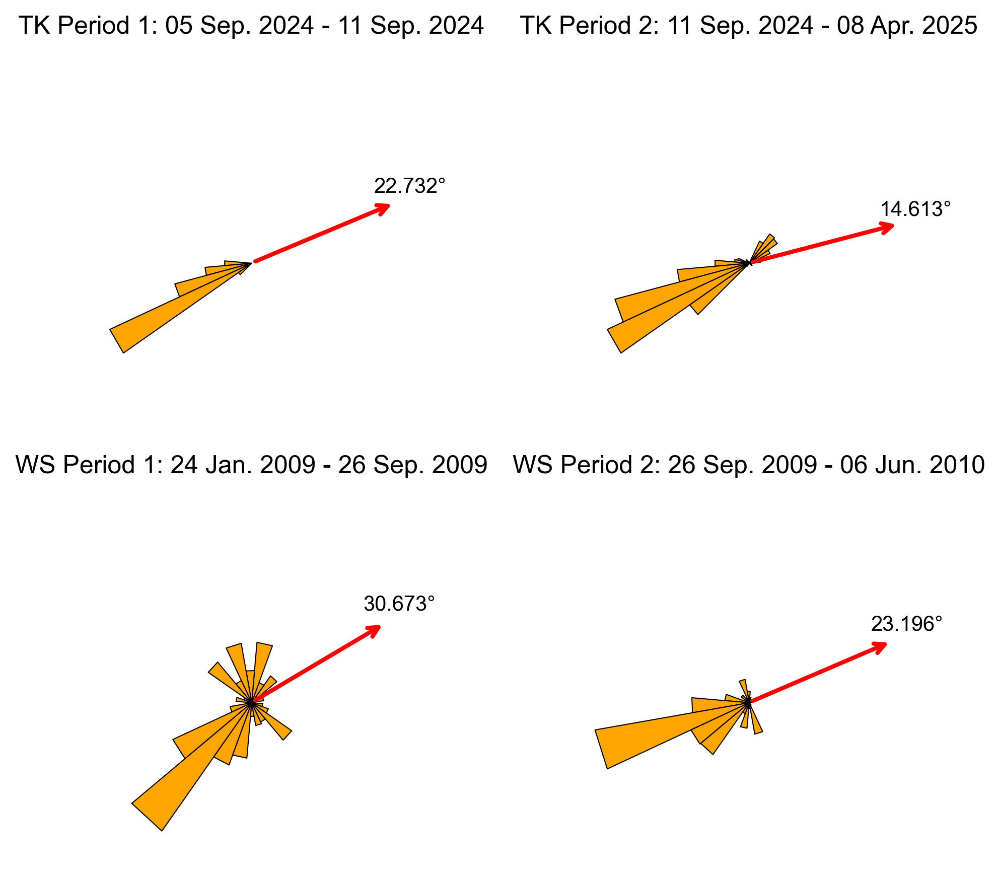

In [11]:
# TK
dw_tk = pd.read_excel('/Users/ylin0188/Desktop/code box/dfsframework code/wind_general.xlsx', sheet_name='TK')
dw_tk = dw_tk.set_index('Time').resample('1h').mean().reset_index()

time1tk = pd.Timestamp('2024-09-05 15:26:00')
time2tk = pd.Timestamp('2024-09-11 11:19:00')
time3tk = pd.Timestamp('2025-04-08 12:58:00')

dw_tk1 = dw_tk[(dw_tk.Time >= time1tk) & (dw_tk.Time <= time2tk)].copy()
dw_tk2 = dw_tk[(dw_tk.Time >= time2tk) & (dw_tk.Time <= time3tk)].copy()

z01_tk = 1.5
af0_tk = 15

def process_dw(dw):
    time_col = dw.columns[0]
    wind_dir_col = dw.columns[1]
    wind_speed_col = dw.columns[2]
    dw = dw.rename(columns={time_col:'time', wind_dir_col: 'wind_direction', wind_speed_col: 'wind_speed'})
    dw['time'] = pd.to_datetime(dw['time'])
    dw['speed'] = pd.to_numeric(dw['wind_speed'], errors='coerce')
    dw['direction'] = pd.to_numeric(dw['wind_direction'], errors='coerce')
    dw = dw.drop(['wind_speed', 'wind_direction'], axis=1)
    return dw

dw_tk1 = process_dw(dw_tk1)
dw_tk2 = process_dw(dw_tk2)

# WS
dw_ws = pd.read_excel('/Users/ylin0188/Desktop/code box/dfsframework code/wind_general.xlsx', sheet_name='WS')
time_col = dw_ws.columns[0]
wind_dir_col = dw_ws.columns[1]
wind_speed_col = dw_ws.columns[2]
dw_ws = dw_ws.rename(columns={time_col:'time', wind_dir_col: 'wind_direction', wind_speed_col: 'wind_speed'})
dw_ws['time'] = pd.to_datetime(dw_ws['time'])
dw_ws['speed'] = pd.to_numeric(dw_ws['wind_speed'], errors='coerce')
dw_ws['direction'] = pd.to_numeric(dw_ws['wind_direction'], errors='coerce')
dw_ws = dw_ws.drop(['wind_speed', 'wind_direction'], axis=1)

time0 = pd.Timestamp(dfws.t[0].item()).tz_localize('UTC')
time1 = pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')
time2 = pd.Timestamp(dfws.t[2].item()).tz_localize('UTC')

dwws_period1 = dw_ws[(dw_ws.time >= time0) & (dw_ws.time <= time1)].dropna()
dwws_period2 = dw_ws[(dw_ws.time >= time1) & (dw_ws.time <= time2)].dropna()

z01_ws = 10
af0_ws = 25
da_ws = 15

# draw flux rose plot
def plot_rose_tk(ax, dw, title):
    da = 10
    mAf = np.arange(-180, 180 + da, da)
    mAmidf = mAf[1:] - da / 2
    
    uKHMN = dw.speed
    qKHMN = flux(uKHMN, z01_tk, z00, rhos_tk)
    aKHMN = bearing_2_pm180_af0(dw.direction, af0_tk)
    
    pq2aa = np.empty(len(mAmidf))
    for i in range(len(mAmidf)):
        pq2aa[i] = np.sum(qKHMN[(aKHMN >= mAf[i]) & (aKHMN < mAf[i + 1])])
    pq2aa = pq2aa / np.sum(qKHMN)
    
    for i in range(len(mAmidf)):
        ax.fill_between([(mAf[i] + af0_tk) / 180 * np.pi + np.pi, 
                         (mAf[i + 1] + af0_tk) / 180 * np.pi + np.pi], 
                        pq2aa[i], lw=0.5, edgecolor='k', facecolor='orange')
    
    theta_center_deg = np.array([(mAf[i] + mAf[i + 1]) / 2 for i in range(len(mAmidf))])
    theta_center_rad = (theta_center_deg + af0_tk) / 180 * np.pi + np.pi
    vector_sum = np.sum(pq2aa * np.exp(1j * theta_center_rad))
    dominant_rad = np.angle(vector_sum)
    max_r = max(pq2aa)
    ax.annotate('', xy=(dominant_rad + np.pi, max_r), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='red', lw=2))
    dominant_deg = (dominant_rad / np.pi * 180 + 180) % 360
    ax.text(dominant_rad + np.pi, max_r * 1.1, f'{dominant_deg:.3f}°',
            ha='center', va='bottom', fontsize=10)
    ax.axis('off')
    ax.set_title(title, fontsize=12)

def plot_rose_ws(ax, dw, title):
    da = 15
    mAf = np.arange(-180, 180 + da, da)
    mAmidf = mAf[1:] - da / 2
    
    uKHMN = dw.speed
    qKHMN = flux(uKHMN, z01_ws, z00, rhos_tk)
    aKHMN = bearing_2_pm180_af0(dw.direction, af0_ws)
    
    pq2aa = np.empty(len(mAmidf))
    for i in range(len(mAmidf)):
        pq2aa[i] = np.sum(qKHMN[(aKHMN >= mAf[i]) & (aKHMN < mAf[i + 1])])
    pq2aa = pq2aa / np.sum(qKHMN)
    
    for i in range(len(mAmidf)):
        ax.fill_between([(mAf[i] + af0_ws) / 180 * np.pi + np.pi, 
                         (mAf[i + 1] + af0_ws) / 180 * np.pi + np.pi], 
                        pq2aa[i], lw=0.5, edgecolor='k', facecolor='orange')
    
    theta_center_deg = np.array([(mAf[i] + mAf[i + 1]) / 2 for i in range(len(mAmidf))])
    theta_center_rad = (theta_center_deg + af0_ws) / 180 * np.pi + np.pi
    vector_sum = np.sum(pq2aa * np.exp(1j * theta_center_rad))
    dominant_rad = np.angle(vector_sum)
    max_r = max(pq2aa)
    ax.annotate('', xy=(dominant_rad + np.pi, max_r), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='red', lw=2))
    dominant_deg = (dominant_rad / np.pi * 180 + 180) % 360
    ax.text(dominant_rad + np.pi, max_r * 1.1, f'{dominant_deg:.3f}°',
            ha='center', va='bottom', fontsize=10)
    ax.axis('off')
    ax.set_title(title, fontsize=12)

fig, axes = plt.subplots(2, 2, figsize=(7, 6), subplot_kw={'projection': 'polar'})

plot_rose_tk(axes[0, 0], dw_tk1, f'TK Period 1: {time1tk:%d %b. %Y} - {time2tk:%d %b. %Y}')
plot_rose_tk(axes[0, 1], dw_tk2, f'TK Period 2: {time2tk:%d %b. %Y} - {time3tk:%d %b. %Y}')

plot_rose_ws(axes[1, 0], dwws_period1, f'WS Period 1: {time0:%d %b. %Y} - {time1:%d %b. %Y}')
plot_rose_ws(axes[1, 1], dwws_period2, f'WS Period 2: {time1:%d %b. %Y} - {time2:%d %b. %Y}')

plt.tight_layout()
plt.show()

In [11]:
def process_wind_data(file_path, start_time, end_time, af0):
    dwtk = pd.read_excel(file_path, sheet_name='TK')
    
    cols = dwtk.columns[:3]
    dwtk = dwtk.rename(columns={cols[0]: 'time', cols[1]: 'wind_direction', cols[2]: 'wind_speed'})
    
    dwtk['time'] = pd.to_datetime(dwtk['time'])
    dwtk['speed'] = pd.to_numeric(dwtk['wind_speed'], errors='coerce')
    dwtk['direction'] = pd.to_numeric(dwtk['wind_direction'], errors='coerce')
    dwtk = dwtk.drop(['wind_speed', 'wind_direction'], axis=1)
    
    dwtk['time'] = dwtk['time'].dt.tz_localize('UTC')
    dwtk = dwtk[(dwtk.time >= start_time) & (dwtk.time <= end_time)].dropna()
    
    dwtk['direction_af0'] = bearing_2_pm180_af0(dwtk['direction'], af0)
    dwtk['speed_proj'] = dwtk.speed * np.cos(np.abs(np.deg2rad(dwtk['direction_af0'])))
    
    dwtk_hourly = dwtk.resample('1h', on='time').mean().reset_index()
    dwtk_hourly['direction_af0'] = bearing_2_pm180_af0(dwtk_hourly['direction'], af0)
    dwtk_hourly['speed_proj'] = dwtk_hourly.speed * np.cos(np.abs(np.deg2rad(dwtk_hourly['direction_af0'])))
    
    return dwtk, dwtk_hourly


file_path = '/Users/ylin0188/Desktop/code box/dfsframework code/wind_general.xlsx'


start1 = pd.Timestamp('2024-09-05 15:26:00').tz_localize('UTC')
end1 = pd.Timestamp('2024-09-11 11:19:00').tz_localize('UTC')
dwtk0, dwtk_hourly0 = process_wind_data(file_path, start1, end1, 22.732)

start2 = pd.Timestamp('2024-09-11 11:19:00').tz_localize('UTC')
end2 = pd.Timestamp('2025-04-08 12:58:00').tz_localize('UTC')
dwtk1, dwtk_hourly1 = process_wind_data(file_path, start2, end2, 14.613)

In [12]:
dwws = pd.read_excel('/Users/ylin0188/Desktop/code box/dfsframework code/wind_general.xlsx', sheet_name='WS')
dwws['direction']=dwws.Direction
dwws['time'] = pd.to_datetime(dwws['Time'])
dwws = dwws.set_index('time')
dwws = dwws.to_xarray()

time0 = pd.Timestamp(dfws.t[0].item()).tz_localize('UTC')
time1 = pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')
time2 = pd.Timestamp(dfws.t[2].item()).tz_localize('UTC')

dwws_period1 = dwws.where((dwws.time >= time0) & (dwws.time <= time1), drop=True)
dwws_period2 = dwws.where((dwws.time >= time1) & (dwws.time <= time2), drop=True)
dwws_period1['direction_af0']=('time',bearing_2_pm180_af0(dwws_period1['direction'],30.673))
dwws_period1['speed_proj']=dwws_period1.Speed*np.cos(np.abs(np.deg2rad(dwws_period1['direction_af0'])))
dwws_period2['direction_af0']=('time',bearing_2_pm180_af0(dwws_period2['direction'],23.196))
dwws_period2['speed_proj']=dwws_period2.Speed*np.cos(np.abs(np.deg2rad(dwws_period2['direction_af0'])))

dwws_daily1 = dwws_period1.resample(time='1D').mean()
dwws_df1 = dwws_period1.to_dataframe().reset_index()
dwws_daily_df1 = dwws_daily1.to_dataframe().reset_index()

dwws_daily2 = dwws_period2.resample(time='1D').mean()
dwws_df2 = dwws_period2.to_dataframe().reset_index()
dwws_daily_df2 = dwws_daily2.to_dataframe().reset_index()

In [13]:
dunemask_data = (dftk.zs[0]-dftk.zs[0].min()).T.values
contours = measure.find_contours(dunemask_data, level=2.8)
xmin=dftk.x.min()
ymin=dftk.y.min()


if contours:
    max_area = 0
    largest_contour = None
    
    for contour in contours:
        x_vals = contour[:, 1]
        y_vals = contour[:, 0]
        area = 0.5 * np.abs(np.dot(x_vals, np.roll(y_vals, 1)) - np.dot(y_vals, np.roll(x_vals, 1)))
        
        if area > max_area:
            max_area = area
            largest_contour = contour
    
    if largest_contour is not None:
        X = np.linspace(float(x[0]-xmin), float(x[-1]-xmin), dunemask_data.shape[1])
        Y = np.linspace(float(y[0]-ymin), float(y[-1]-ymin), dunemask_data.shape[0])

## Figure 3 (dont show here to control the file size, see Figure 2-3.ipynb)

In [29]:
# process DEM+wind data in the White Sands to get field-resolved wind and sediment flux

af0 = 25 # for white sands from Gunn et al. 2020
z01 = 10 # wind speed is measured at 10 m from KHMN station in the mestwest dataset
adelta = 15
start_time = pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')
end_time = pd.Timestamp(dfws.t[2].item()).tz_localize('UTC')

zdata=dfws.zre[1].values[3000:8000,:] # in order to save computational cost

dtws = xr.Dataset(data_vars=dict(z=(['x','y'],zdata)),
                coords=dict(x=(['x'],np.arange(zdata.shape[0])),
                            y=(['y'],np.arange(zdata.shape[1]))))

# use the represenstative/best values from the optimization method
ut = 0.32
Cq = 4.5
lsat = 1.7
padsl = -1/6
recth = np.tan(-18*np.pi/180)
recsl = -1/6

dtws = make_pad(dtws,'z','zp',padsl)
dtws = make_bubble(dtws,'zp','zb',recth,recsl)
# dtws = dtws.coarsen(x=2, y=2, boundary='pad').mean()

In [30]:
dw_period1 = dwws_df2[
    (dwws_df2.time >= start_time) & 
    (dwws_df2.time <= end_time) & 
    (dwws_df2.speed_proj * kap / np.log(10 / z00) >= ut)
].dropna()

dw_period1['stree_velocity'] = dw_period1['Speed']*kap/np.log(z01/z00)

us=dw_period1['stree_velocity'].mean().item()#representative value e.g. mean value

dtws['uxso'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dtws.x.data,dtws.y.data,dtws.zb.where(~dtws.zb.isnull(),dtws.zp).data,d,us,nu),us).real)
dtws['uxs'] = dtws.uxso.where(dtws.zb.isnull(),np.nan)
dtws['uxso_neg'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dtws.x.data,dtws.y.data,dtws.zb.where(~dtws.zb.isnull(), dtws.zp).data[::-1, ::-1],d,us,nu),us).real)
dtws['uxs_neg'] = dtws.uxso_neg.where(dtws.zb.isnull(),np.nan)
dtws['uyso'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dtws.x.data,dtws.y.data,dtws.zb.where(~dtws.zb.isnull(),dtws.zp).data,d,us,nu),us).imag)
dtws['uys'] = dtws.uyso.where(dtws.zb.isnull(),np.nan)

dtws = dtws.assign_coords(time=dw_period1.time)
dtws['ux'] = (('time'),dw_period1['stree_velocity'])
dtws['uxt_positive'] = dtws.ux.where(dtws.ux >= 0) / us * dtws.uxs
dtws['uxt_negative'] = (-np.abs(dtws.ux.where(dtws.ux <= 0)) / us * dtws.uxs_neg)[::-1, ::-1]  # rotate after calculation
dtws['uxt'] = dtws.uxt_positive.fillna(0)
dtws['uxspt'] = dtws.uxt.mean('time')
dtws['qs'] = (dtws.uxt**2-ut**2)*Cq*ut*rhof/rhos_ws*grav
dtws['qs'] = dtws.qs.where(dtws.qs>0,0)
dtws['qsat'] = dtws.qs.mean('time') * 365.25 * 24

dtws['qs'] = dtws.qs[:,
    int((dtws.uxspt.shape[0]-5000)/2):int((dtws.uxspt.shape[0]-5000)/2+5000),
    int((dtws.uxspt.shape[1]-501)/2):int((dtws.uxspt.shape[1]-501)/2+501)
].where(dfws.qre[1, 3000:8000, :] > 2, other=0)
dtws['qs'] = dtws.qs.fillna(0)
# dtws['qsat'] = dtws.qs.mean('time') * 365.25 * 24
q = np.zeros(dtws.qs.shape) # true flux array initialised
q[:,0] = 0 # input true flux at x=0, here just arbitrary
dx=dtws.x.isel(x=slice(None,2)).diff('x').data[0]
for i in range(1,q.shape[1]):
    q[:,i] = (q[:,i-1]+dx*dtws.qs.data[:,i]/lsat)/(1+dx/lsat) # loop through and make true flux
dtws['q'] = (('time','x','y'),q)
dtws['qspt'] = dtws.q.mean('time') * 365.25 * 24

In [25]:
start_time = pd.Timestamp(dftk.time[1].item()).tz_localize('UTC')
end_time = pd.Timestamp(dftk.time[2].item()).tz_localize('UTC')

dttk = xr.Dataset(
    {
        'z': (('x', 'y'),gaussian_filter((dftk.dunemask[1] - dftk.dunemask[1].min()).
                                         fillna(0).values.astype(float), sigma=8))
    },
    coords={
        'x': (('x'), dftk.x.values - dftk.x.min().item()),
        'y': (('y'), dftk.y.values - dftk.y.min().item()),
    },
)

dttk = make_pad(dttk,'z','zp',padsl)
dttk= make_bubble(dttk,'zp','zb',recth,recsl)
dttk['zpb'] = xr.where(dttk.zb.isnull(), dttk.zp, dttk.zb)
dttk['zpbro'] = dttk.zpb-dttk.zp+dttk.z
qdata=dftk.qmask[1].values
qdem = np.zeros(dttk.z.shape)
x_offset = (dttk.x.size- qdata.shape[0]) // 2
y_offset = (dttk.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dttk['qdem'] = (('x','y'),qdem)

ut = 0.3
Cq = 6
lsat = 1.5
z01 = 1.5
dw_period1 = dwtk_hourly1.where((dwtk_hourly1.time >= start_time) & (dwtk_hourly1.time <= end_time) & (dwtk_hourly1.speed*kap/np.log(z01/z00) >=ut))
dw_period1['stree_velocity'] = dw_period1['speed']*kap/np.log(z01/z00)
dw_period1 = dw_period1.dropna()

us=dw_period1['stree_velocity'].mean()#representative value
dttk['uxso'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dttk.x.data,dttk.y.data,dttk.zb.where(~dttk.zb.isnull(),dttk.zp).data,d,us,nu),us).real)
dttk['uxs'] = dttk.uxso.where(dttk.zb.isnull(),np.nan)
dttk['uyso'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dttk.x.data,dttk.y.data,dttk.zb.where(~dttk.zb.isnull(),dttk.zp).data,d,us,nu),us).imag)
dttk['uys'] = dttk.uyso.where(dttk.zb.isnull(),np.nan)

dttk = dttk.assign_coords(time=dw_period1.time)
dttk['ux'] = (('time'),dw_period1['stree_velocity'])
dttk['uxt'] = dttk.ux/us*dttk.uxs
dttk['qs'] = (dttk.uxt**2-ut**2)*Cq*ut*rhof/rhos_tk*grav
dttk['qs'] = dttk.qs.where(dttk.qs>0,0)

dttk['qsat'] = dttk.qs.mean('time') * 365.25 * 24

dx = dttk.x.isel(x=slice(None,2)).diff('x').data[0]

q = np.zeros(dttk.qs.shape) # true flux array initialised
q[:,0] = 0 # input true flux at x=0, here just arbitrary
dx=dttk.x.isel(x=slice(None,2)).diff('x').data[0]
for i in range(1,q.shape[1]):
    q[:,i] = (q[:,i-1]+dx*dttk.qs.data[:,i]/lsat)/(1+dx/lsat) # loop through and make true flux
dttk['q'] = (('time','x','y'),q)
dttk['qspt'] = dttk.q.mean('time') * 365.25 * 24
dttk1 = dttk.copy()
dttk1['qspt'] = (('x', 'y'), np.nan_to_num(dftk.mask.values * dttk.qspt.values, nan=0.0))


dttk = xr.Dataset(
    {
        'z': (('x', 'y'),gaussian_filter((dftk.dunemask[1] - dftk.dunemask[1].min()).
                                         fillna(0).values.astype(float), sigma=3))
    },
    coords={
        'x': (('x'), dftk.x.values - dftk.x.min().item()),
        'y': (('y'), dftk.y.values - dftk.y.min().item()),
    },
)

dttk = make_pad(dttk,'z','zp',padsl)
dttk= make_bubble(dttk,'zp','zb',recth,recsl)
dttk['zpb'] = xr.where(dttk.zb.isnull(), dttk.zp, dttk.zb)
dttk['zpbro'] = dttk.zpb-dttk.zp+dttk.z
qdata=dftk.qmask[1].values
qdem = np.zeros(dttk.z.shape)
x_offset = (dttk.x.size- qdata.shape[0]) // 2
y_offset = (dttk.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dttk['qdem'] = (('x','y'),qdem)

ut = 0.25
Cq = 6
lsat = 0.8
z01=1.5
dw_period1 = dwtk_hourly1.where((dwtk_hourly1.time >= start_time) & (dwtk_hourly1.time <= end_time) & (dwtk_hourly1.speed*kap/np.log(z01/z00) >=ut))
dw_period1['stree_velocity'] = dw_period1['speed']*kap/np.log(z01/z00)
dw_period1 = dw_period1.dropna()

us=dw_period1['stree_velocity'].mean()#representative value
dttk['uxso'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dttk.x.data,dttk.y.data,dttk.zb.where(~dttk.zb.isnull(),dttk.zp).data,d,us,nu),us).real)
dttk['uxs'] = dttk.uxso.where(dttk.zb.isnull(),np.nan)
dttk['uyso'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dttk.x.data,dttk.y.data,dttk.zb.where(~dttk.zb.isnull(),dttk.zp).data,d,us,nu),us).imag)
dttk['uys'] = dttk.uyso.where(dttk.zb.isnull(),np.nan)

# Figure 4

## For the barchan dune in Taklamakan

In [23]:
def fromfactor_tolossfunction(ut,Cq,lsat,dt,dw,z01,start_time,end_time):
    dw_period = dw.where((dw.time >= start_time) & (dw.time <= end_time) & (dw.speed_proj*kap/np.log(z01/z00) >=ut))
    dw_period['stree_velocity'] = dw_period['speed']*kap/np.log(z01/z00)
    dw_period = dw_period.dropna()

    us=dw_period['stree_velocity'].mean().item()#representative value
    dt['uxs'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dt.x.data,dt.y.data,dt.zb.where(~dt.zb.isnull(),dt.zp).data,d,us,nu),us).real)
    dt['uxs'] = dt.uxs.where(dt.zb.isnull(),0).clip(0,None)


    dt = dt.assign_coords(time=dw_period.time)
    dt['ux'] = (('time'),dw_period['stree_velocity'])
    dt['uxt'] = dt.ux/us*dt.uxs
    dt['qs'] = (dt.uxt**2-ut**2)*Cq*ut*rhof/rhos_tk*grav
    dt['qs'] = dt.qs.where(dt.qs>0,0)

    dx = dt.x.isel(x=slice(None,2)).diff('x').data[0]
    q = np.zeros(dt.qs.shape) # true flux array initialised
    q[:,0] = 0 # input true flux at x=0, here just arbitrary
    dx=dt.x.isel(x=slice(None,2)).diff('x').data[0]
    for i in range(1,q.shape[1]):
        q[:,i] = (q[:,i-1]+dx*dt.qs.data[:,i]/lsat)/(1+dx/lsat) # loop through and make true flux
    dt['q'] = (('time','x','y'),q)
    dt['qspt'] = dt.q.mean('time') * 365.25 * 24

    q_spt=[]
    q_dem=[]

    for y_disp in range(dftk.y.shape[0]):
        z_y=dt.z[:,y_disp]   
        qspt_y=dt.qspt[:,y_disp]
        qdem_y=dt.qdem[:,y_disp]

        if z_y.max()>0:

            q_spt.append(qspt_y[z_y ==z_y.max().values])
            q_dem.append(qdem_y[z_y ==z_y.max().values])

    q_spt = np.array(q_spt, dtype=np.float64).flatten()
    q_dem = np.array(q_dem, dtype=np.float64).flatten()
    invalid_indices = (q_dem<=0) | (q_spt<=0)
    q_dem = q_dem[~invalid_indices]
    q_spt = q_spt[~invalid_indices]

    return(np.mean(np.abs(q_dem-q_spt)))

In [32]:
start_time = pd.Timestamp(dftk.time[1].item()).tz_localize('UTC')
end_time = pd.Timestamp(dftk.time[2].item()).tz_localize('UTC')
sigma = 3
dttk = xr.Dataset(
    {
        'z': (('x', 'y'),gaussian_filter((dftk.dunemask[1] - dftk.dunemask[1].min()).
                                         fillna(0).values.astype(float), sigma=sigma))
    },
    coords={
        'x': (('x'), dftk.x.values - dftk.x.min().item()),
        'y': (('y'), dftk.y.values - dftk.y.min().item()),
    },
)

dttk = make_pad(dttk,'z','zp',padsl)
dttk= make_bubble(dttk,'zp','zb',recth,recsl)
dttk['zpb'] = xr.where(dttk.zb.isnull(), dttk.zp, dttk.zb)
dttk['zpbro'] = dttk.zpb-dttk.zp+dttk.z

qdata=dftk.qmask[1].values
qdem = np.zeros(dttk.z.shape)
x_offset = (dttk.x.size- qdata.shape[0]) // 2
y_offset = (dttk.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dttk['qdem'] = (('x','y'),qdem)

# upper
dttkup = xr.Dataset(
    {
        'z': (('x', 'y'),(dftk.dunemask[1]-dftk.dunemask[1].min()).fillna(0).values)
    },
    coords={
        'x': (('x'), dftk.x.values - dftk.x.min().item()),
        'y': (('y'), dftk.y.values - dftk.y.min().item()),
    },
)

dttkup = make_pad(dttkup,'z','zp',padsl)
dttkup= make_bubble(dttkup,'zp','zb',recth,recsl)
dttkup['zpb'] = xr.where(dttkup.zb.isnull(), dttkup.zp, dttkup.zb)
dttkup['zpbro'] = dttkup.zpb-dttkup.zp+dttkup.z

qdata=dftk.qmask_upper[1].values
qdem = np.zeros(dttkup.z.shape)
x_offset = (dttkup.x.size- qdata.shape[0]) // 2
y_offset = (dttkup.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dttkup['qdem'] = (('x','y'),qdem)

# lower
dttkdown = xr.Dataset(
    {
        'z': (('x', 'y'),(dftk.dunemask[1]-dftk.dunemask[1].min()).fillna(0).values)
    },
    coords={
        'x': (('x'), dftk.x.values - dftk.x.min().item()),
        'y': (('y'), dftk.y.values - dftk.y.min().item()),
    },
)

dttkdown = make_pad(dttkdown,'z','zp',padsl)
dttkdown= make_bubble(dttkdown,'zp','zb',recth,recsl)
dttkdown['zpb'] = xr.where(dttkdown.zb.isnull(), dttkdown.zp, dttkdown.zb)
dttkdown['zpbro'] = dttkdown.zpb-dttkdown.zp+dttkdown.z

qdata=dftk.qmask_lower[1].values
qdem = np.zeros(dttkdown.z.shape)
x_offset = (dttkdown.x.size- qdata.shape[0]) // 2
y_offset = (dttkdown.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dttkdown['qdem'] = (('x','y'),qdem)

In [29]:
z01 = 1.5
def objective(params):
    ut, Cq ,lsat= params
    return fromfactor_tolossfunction(ut,Cq,lsat,dttk,dwtk_hourly1,z01,start_time,end_time)


x0 = [0.25,6,1]  

# bounds
bounds = [(0.2, 0.4),  # uth range
        (2, 8), # Cq range
        (0,5)]  # lsat range

res_tk1 = minimize(objective, x0, method='L-BFGS-B',bounds=bounds)

print("Optimization Results:")
print("uth =", res_tk1.x[0])
print("Cq   =", res_tk1.x[1])
print("lsat   =", res_tk1.x[2])

Optimization Results:
uth = 0.24359174143973197
Cq   = 5.982935805664693
lsat   = 1.0039653773529587


In [ ]:
Cq_vals_tk_forCq= np.linspace(2, 8, 100)
loss_gridCq_tk = np.zeros(len(Cq_vals_tk_forCq))
loss_gridCq_tkup = np.zeros(len(Cq_vals_tk_forCq))
loss_gridCq_tkdown = np.zeros(len(Cq_vals_tk_forCq))
for i, Cq in enumerate(Cq_vals_tk_forCq):
    loss_gridCq_tk[i] = fromfactor_tolossfunction(res_tk1.x[0],Cq,res_tk1.x[2],dttk,dwtk_hourly1,z01,start_time,end_time)
    loss_gridCq_tkup[i] = fromfactor_tolossfunction(res_tk1.x[0],Cq,res_tk1.x[2],dttkup,dwtk_hourly1,z01,start_time,end_time)
    loss_gridCq_tkdown[i] = fromfactor_tolossfunction(res_tk1.x[0],Cq,res_tk1.x[2],dttkdown,dwtk_hourly1,z01,start_time,end_time)
    print(f"Cq: {Cq:.2f}", end='\r')

In [ ]:
loss_norm = loss_gridCq_tk / np.min(loss_gridCq_tk)
loss_norm_up = loss_gridCq_tkup / np.min(loss_gridCq_tkup)
loss_norm_down = loss_gridCq_tkdown / np.min(loss_gridCq_tkdown)

min_idx = np.argmin(loss_norm)
min_idx_up = np.argmin(loss_norm_up)
min_idx_down = np.argmin(loss_norm_down)

Cqtk01=Cq_vals_tk_forCq[min_idx]
Cqtk01up=Cq_vals_tk_forCq[min_idx_up]
Cqtk01down=Cq_vals_tk_forCq[min_idx_down]
print(Cqtk01,Cqtk01up,Cqtk01down)

6.0 5.696969696969697 6.545454545454546


In [ ]:
lsat_vals_tkforCl = np.linspace(1, 30, 100)/(rhof/(rhos_tk*d_tk))
loss_gridlsat_tk = np.zeros(len(lsat_vals_tkforCl))
loss_gridlsat_tkup = np.zeros(len(lsat_vals_tkforCl))
loss_gridlsat_tkdown = np.zeros(len(lsat_vals_tkforCl))

for j, lsat in enumerate(lsat_vals_tkforCl):
    loss_gridlsat_tk[j] = fromfactor_tolossfunction(res_tk1.x[0],res_tk1.x[1],lsat,dttk,dwtk_hourly1,z01,start_time,end_time)
    loss_gridlsat_tkup[j] = fromfactor_tolossfunction(res_tk1.x[0],res_tk1.x[1],lsat,dttkup,dwtk_hourly1,z01,start_time,end_time)
    loss_gridlsat_tkdown[j] = fromfactor_tolossfunction(res_tk1.x[0],res_tk1.x[1],lsat,dttkdown,dwtk_hourly1,z01,start_time,end_time)
    print(f"lsat: {lsat:.2f}", end='\r')

In [ ]:
loss_norm = loss_gridlsat_tk / np.min(loss_gridlsat_tk)
loss_norm_up = loss_gridlsat_tkup / np.min(loss_gridlsat_tkup)
loss_norm_down = loss_gridlsat_tkdown / np.min(loss_gridlsat_tkdown)

min_idx = np.argmin(loss_norm)
min_idx_up = np.argmin(loss_norm_up)
min_idx_down = np.argmin(loss_norm_down)

Cltk01=lsat_vals_tkforCl[min_idx]/3.8* (rhof / (rhos_tk * d_tk ))
Cltk01up=lsat_vals_tkforCl[min_idx_up]/3.8* (rhof / (rhos_tk * d_tk ))
Cltk01down=lsat_vals_tkforCl[min_idx_down]/3.8* (rhof / (rhos_tk * d_tk ))
print(Cltk01,Cltk01up,Cltk01down)

3.577884104199894 3.963317384370016 3.2695374800637964


In [ ]:
uth_vals_tkforCu = np.linspace(0.05,0.2,20)/np.sqrt(rhof/(rhos_tk*grav*d_tk))
loss_griduth_tk = np.zeros(len(uth_vals_tkforCu))
loss_griduth_tkup = np.zeros(len(uth_vals_tkforCu))
loss_griduth_tkdown = np.zeros(len(uth_vals_tkforCu))
lsat_mf = lsat_vals_tkforCl[np.log(loss_gridlsat_tk/np.min(loss_gridlsat_tk))==0]

for j, uth in enumerate(uth_vals_tkforCu):
    loss_griduth_tk[j] = fromfactor_tolossfunction(uth,res_tk1.x[1],lsat_mf,dttk,dwtk_hourly1,z01,start_time,end_time)
    loss_griduth_tkup[j] = fromfactor_tolossfunction(uth,res_tk1.x[1],lsat_mf,dttkup,dwtk_hourly1,z01,start_time,end_time)
    loss_griduth_tkdown[j] = fromfactor_tolossfunction(uth,res_tk1.x[1],lsat_mf,dttkdown,dwtk_hourly1,z01,start_time,end_time)
    print(f"uth: {uth:.2f}", end='\r')

In [ ]:
loss_norm = loss_griduth_tk / np.min(loss_griduth_tk)
loss_norm_up = loss_griduth_tkup / np.min(loss_griduth_tkup)
loss_norm_down = loss_griduth_tkdown / np.min(loss_griduth_tkdown)

min_idx = np.argmin(loss_norm)
min_idx_up = np.argmin(loss_norm_up)
min_idx_down = np.argmin(loss_norm_down)

Cutk01=uth_vals_tkforCu[min_idx]*np.sqrt(rhof/(rhos_tk*grav*d_tk))
Cutk01up=uth_vals_tkforCu[min_idx_up]*np.sqrt(rhof/(rhos_tk*grav*d_tk))
Cutk01down=uth_vals_tkforCu[min_idx_down]* np.sqrt(rhof/(rhos_tk*grav*d_tk))
print(Cltk01,Cltk01up,Cltk01down)

3.577884104199894 3.963317384370016 3.2695374800637964


In [ ]:
Cq_vals_tk_2d = np.linspace(2, 8, 15)    
Cut_vals_tk_2d = np.linspace(0.05,0.2,15)
loss_grid_tk2d_1 = np.zeros((len(Cut_vals_tk_2d), len(Cq_vals_tk_2d)))

for i, Cut in enumerate(Cut_vals_tk_2d):
    for j, Cq in enumerate(Cq_vals_tk_2d):
        loss_grid_tk2d_1[i, j] = fromfactor_tolossfunction(Cut/np.sqrt(rhof/(rhos_tk*grav*d_tk)),Cq,1,dttk,dwtk_hourly1,z01,start_time,end_time)
        print(f"Cut: {Cut:.2f}, Cq: {Cq:.2f}", end='\r')

loss_grid_tk2d_1 = gaussian_filter(loss_grid_tk2d_1, 1)

In [ ]:
Cq_vals_tk = np.linspace(2, 8, 10)
Cut_vals_tk = np.linspace(0.05, 0.2, 10)
Clsat_vals_tk = np.linspace(1, 5, 10)

loss_grid_tk3d = np.zeros((len(Cq_vals_tk), len(Cut_vals_tk), len(Clsat_vals_tk)))

for i, Cq in enumerate(Cq_vals_tk):
    for j, Cut in enumerate(Cut_vals_tk):
            for k, Clsat in enumerate(Clsat_vals_tk):
                loss_grid_tk3d[i, j, k] = fromfactor_tolossfunction(Cut/np.sqrt(rhof/(rhos_tk*grav*d_tk)),Cq,Clsat/(rhof/(rhos_tk*d_tk)),dttk,dwtk_hourly1,z01,start_time,end_time)
                print(f"Cq: {Cq:.2f}, Cut: {Cut:.2f}, Clsat: {Clsat:.2f} ", end='\r')

In [ ]:
loss_norm = loss_gridCq_tk / np.min(loss_gridCq_tk)
loss_norm_up = loss_gridCq_tkup / np.min(loss_gridCq_tkup)
loss_norm_down = loss_gridCq_tkdown / np.min(loss_gridCq_tkdown)

min_idx = np.argmin(loss_norm)
min_idx_up = np.argmin(loss_norm_up)
min_idx_down = np.argmin(loss_norm_down)

Cqtk01=Cq_vals_tk_forCq[min_idx]
Cqtk01up=Cq_vals_tk_forCq[min_idx_up]
Cqtk01down=Cq_vals_tk_forCq[min_idx_down]
print(Cqtk01,Cqtk01up,Cqtk01down)

6.0 5.696969696969697 6.545454545454546


In [37]:
start_time = pd.Timestamp(dftk.time[0].item()).tz_localize('UTC')
end_time = pd.Timestamp(dftk.time[1].item()).tz_localize('UTC')
sigma = 3
dttk = xr.Dataset(
    {
        'z': (('x', 'y'),gaussian_filter((dftk.dunemask[0] - dftk.dunemask[0].min()).
                                         fillna(0).values.astype(float), sigma=sigma))
    },
    coords={
        'x': (('x'), dftk.x.values - dftk.x.min().item()),
        'y': (('y'), dftk.y.values - dftk.y.min().item()),
    },
)

dttk = make_pad(dttk,'z','zp',padsl)
dttk= make_bubble(dttk,'zp','zb',recth,recsl)
dttk['zpb'] = xr.where(dttk.zb.isnull(), dttk.zp, dttk.zb)
dttk['zpbro'] = dttk.zpb-dttk.zp+dttk.z

qdata=dftk.qmask[0].values
qdem = np.zeros(dttk.z.shape)
x_offset = (dttk.x.size- qdata.shape[0]) // 2
y_offset = (dttk.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dttk['qdem'] = (('x','y'),qdem)

# upper
dttkup = xr.Dataset(
    {
        'z': (('x', 'y'),(dftk.dunemask[0]-dftk.dunemask[0].min()).fillna(0).values)
    },
    coords={
        'x': (('x'), dftk.x.values - dftk.x.min().item()),
        'y': (('y'), dftk.y.values - dftk.y.min().item()),
    },
)

dttkup = make_pad(dttkup,'z','zp',padsl)
dttkup= make_bubble(dttkup,'zp','zb',recth,recsl)
dttkup['zpb'] = xr.where(dttkup.zb.isnull(), dttkup.zp, dttkup.zb)
dttkup['zpbro'] = dttkup.zpb-dttkup.zp+dttkup.z

qdata=dftk.qmask_upper[0].values
qdem = np.zeros(dttkup.z.shape)
x_offset = (dttkup.x.size- qdata.shape[0]) // 2
y_offset = (dttkup.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dttkup['qdem'] = (('x','y'),qdem)

# lower
dttkdown = xr.Dataset(
    {
        'z': (('x', 'y'),(dftk.dunemask[0]-dftk.dunemask[0].min()).fillna(0).values)
    },
    coords={
        'x': (('x'), dftk.x.values - dftk.x.min().item()),
        'y': (('y'), dftk.y.values - dftk.y.min().item()),
    },
)

dttkdown = make_pad(dttkdown,'z','zp',padsl)
dttkdown= make_bubble(dttkdown,'zp','zb',recth,recsl)
dttkdown['zpb'] = xr.where(dttkdown.zb.isnull(), dttkdown.zp, dttkdown.zb)
dttkdown['zpbro'] = dttkdown.zpb-dttkdown.zp+dttkdown.z

qdata=dftk.qmask_lower[0].values
qdem = np.zeros(dttkdown.z.shape)
x_offset = (dttkdown.x.size- qdata.shape[0]) // 2
y_offset = (dttkdown.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dttkdown['qdem'] = (('x','y'),qdem)

In [31]:
z01 = 1.5
def objective(params):
    ut, Cq ,lsat= params
    return fromfactor_tolossfunction(ut,Cq,lsat,dttk,dwtk_hourly0,z01,start_time,end_time)


x0 = [0.28,40,1]  

# bounds
bounds = [(0.2, 0.4),  # uth range
        (2, 50), # Cq range
        (0,5)]  # lsat range

res_tk2 = minimize(objective, x0, method='L-BFGS-B',bounds=bounds)

print("Optimization Results:")
print("uth =", res_tk2.x[0])
print("Cq   =", res_tk2.x[1])
print("lsat   =", res_tk2.x[2])

Optimization Results:
uth = 0.2657762515094917
Cq   = 39.998404996992555
lsat   = 1.032603818200062


In [ ]:
Cq_vals_tk_2d2 = np.linspace(2, 82, 15)    
Cut_vals_tk_2d = np.linspace(0.05,0.2,15)
loss_grid_tk2d_2 = np.zeros((len(Cut_vals_tk_2d), len(Cq_vals_tk_2d)))

for i, Cut in enumerate(Cut_vals_tk_2d):
    for j, Cq in enumerate(Cq_vals_tk_2d2):
        loss_grid_tk2d_2[i, j] = fromfactor_tolossfunction(Cut/np.sqrt(rhof/(rhos_tk*grav*d_tk)),Cq,res_tk2.x[2],dttk,dwtk_hourly0,z01,start_time,end_time)
        print(f"Cut: {Cut:.2f}, Cq: {Cq:.2f}", end='\r')

loss_grid_tk2d_2 = gaussian_filter(loss_grid_tk2d_2, 0.8)

In [47]:
Cq_vals_tk_forCq2= np.linspace(2, 52, 100)
loss_gridCq_tk2 = np.zeros(len(Cq_vals_tk_forCq))
loss_gridCq_tk2up = np.zeros(len(Cq_vals_tk_forCq))
loss_gridCq_tk2down = np.zeros(len(Cq_vals_tk_forCq))
for i, Cq in enumerate(Cq_vals_tk_forCq2):
    loss_gridCq_tk2[i] = fromfactor_tolossfunction(res_tk2.x[0],Cq,res_tk2.x[2],dttk,dwtk_hourly0,z01,start_time,end_time)
    loss_gridCq_tk2up[i] = fromfactor_tolossfunction(res_tk2.x[0],Cq,res_tk2.x[2],dttkup,dwtk_hourly0,z01,start_time,end_time)
    loss_gridCq_tk2down[i] = fromfactor_tolossfunction(res_tk2.x[0],Cq,res_tk2.x[2],dttkdown,dwtk_hourly0,z01,start_time,end_time)
    
    print(f"Cq: {Cq:.2f}", end='\r')

In [ ]:
lsat_vals_tkforCl = np.linspace(1, 30, 100)/(rhof/(rhos_tk*d_tk))
loss_gridlsat_tk2 = np.zeros(len(lsat_vals_tkforCl))
Cq_tk2 = Cq_vals_tk_forCq2[np.log(loss_gridCq_tk2/np.min(loss_gridCq_tk2))==0]

for j, lsat in enumerate(lsat_vals_tkforCl):
    loss_gridlsat_tk2[j] = fromfactor_tolossfunction(res_tk2.x[0],Cq_tk2 ,lsat,dttk,dwtk_hourly0,z01,start_time,end_time)
    print(f"lsat: {lsat:.2f}", end='\r')

In [ ]:
uth_vals_tkforCu2 = np.linspace(0.05,0.25,20)/np.sqrt(rhof/(rhos_tk*grav*d_tk))
loss_griduth_tk2 = np.zeros(len(uth_vals_tkforCu2))
# lsat_mf = lsat_vals_tkforCl[np.log(loss_gridlsat_tk/np.min(loss_gridlsat_tk))==0]

for j, uth in enumerate(uth_vals_tkforCu2):
    loss_griduth_tk2[j] = fromfactor_tolossfunction(uth,Cq_tk2 ,res_tk2.x[1],dttk,dwtk_hourly0,z01,start_time,end_time)
    print(f"uth: {uth:.2f}", end='\r')

In [ ]:
loss_norm = loss_gridCq_tk2 / np.min(loss_gridCq_tk2)
loss_norm_up = loss_gridCq_tk2up / np.min(loss_gridCq_tk2up)
loss_norm_down = loss_gridCq_tk2down / np.min(loss_gridCq_tk2down)

min_idx = np.argmin(loss_norm)
min_idx_up = np.argmin(loss_norm_up)
min_idx_down = np.argmin(loss_norm_down)

Cqtk02=Cq_vals_tk_forCq2[min_idx]
Cqtk02up=Cq_vals_tk_forCq2[min_idx_up]
Cqtk02down=Cq_vals_tk_forCq2[min_idx_down]
print(Cqtk02,Cqtk02up,Cqtk02down)

## Figure S4 C-E

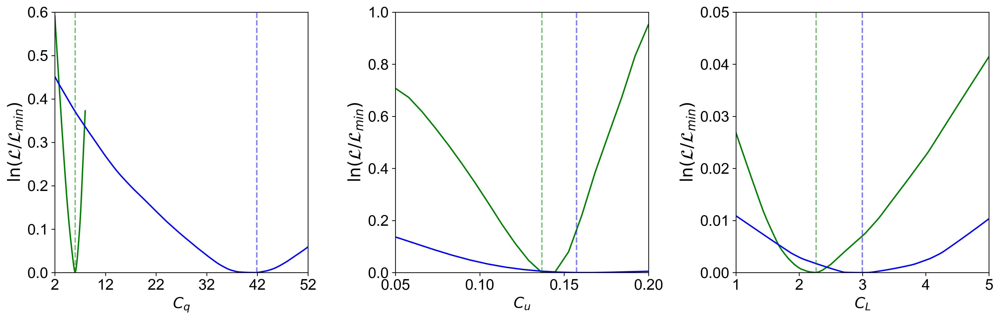

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

x1 = Cq_vals_tk_forCq
x12 = Cq_vals_tk_forCq2
y1 = np.log(loss_gridCq_tk / np.min(loss_gridCq_tk))
y2 = np.log(loss_gridCq_tk2 / np.min(loss_gridCq_tk2))
axes[0].plot(x1, y1, 'g-', label='Period 1')
axes[0].plot(x12, y2, 'b-', label='Period 2')
min_idx1 = np.argmin(y1)
min_idx2 = np.argmin(y2)
Cq2tk=x1[min_idx1]
Cq1tk=x12[min_idx2]
axes[0].axvline(x1[min_idx1], color='g', linestyle='--', alpha=0.5)
axes[0].axvline(x12[min_idx2], color='b', linestyle='--', alpha=0.5)
axes[0].set_xlabel('$C_q$')
axes[0].set_xlim([2,52])
axes[0].set_ylim([0,0.6])
axes[0].set_xticks([2, 12, 22, 32, 42, 52])
axes[0].set_xticklabels(['2', '12', '22', '32', '42', '52'])
axes[0].set_ylabel('$\\ln(\\mathcal{L}/\\mathcal{L}_{min})$',fontsize=18)

x21 = uth_vals_tkforCu * np.sqrt(rhof / (rhos_tk * grav * d_tk))
x22 = uth_vals_tkforCu2 * np.sqrt(rhof / (rhos_tk * grav * d_tk))-0.04
y1 = gaussian_filter1d(np.log(loss_griduth_tk / np.min(loss_griduth_tk)),1)
y2 = gaussian_filter1d(np.log(loss_griduth_tk2 / np.min(loss_griduth_tk2)),3)
axes[1].plot(x21, y1-np.min(y1), 'g-', label='Period 1')
axes[1].plot(x22, y2-np.min(y2), 'b-', label='Period 2')
min_idx1 = np.argmin(y1)
min_idx2 = np.argmin(y2)
Cu2tk=x21[min_idx1]
Cu1tk=x22[min_idx2]
axes[1].axvline(x21[min_idx1], color='g', linestyle='--', alpha=0.5)
axes[1].axvline(x22[min_idx2], color='b', linestyle='--', alpha=0.5)
axes[1].set_xlabel('$C_u$')
axes[1].set_xlim([0.05,0.20])
axes[1].set_ylim([0,1])
axes[1].set_ylabel('$\\ln(\\mathcal{L}/\\mathcal{L}_{min})$',fontsize=18)

x3 = lsat_vals_tkforCl * (rhof / (rhos_tk * d_tk ))/6
y1 = np.log(loss_gridlsat_tk / np.min(loss_gridlsat_tk))
y2 = np.log(loss_gridlsat_tk2 / np.min(loss_gridlsat_tk2))
axes[2].plot(x3, y1, 'g-', label='Period 1')
axes[2].plot(x3, y2, 'b-', label='Period 2')
min_idx1 = np.argmin(y1)
min_idx2 = np.argmin(y2)
axes[2].axvline(x3[min_idx1], color='g', linestyle='--', alpha=0.5)
axes[2].axvline(x3[min_idx2], color='b', linestyle='--', alpha=0.5)
axes[2].set_xlabel('$C_L$')
axes[2].set_xlim([1,5])
axes[2].set_ylim([0,0.05])
axes[2].set_ylabel('$\\ln(\\mathcal{L}/\\mathcal{L}_{min})$',fontsize=18)

plt.tight_layout()
plt.show()

## Figure S4 A&B

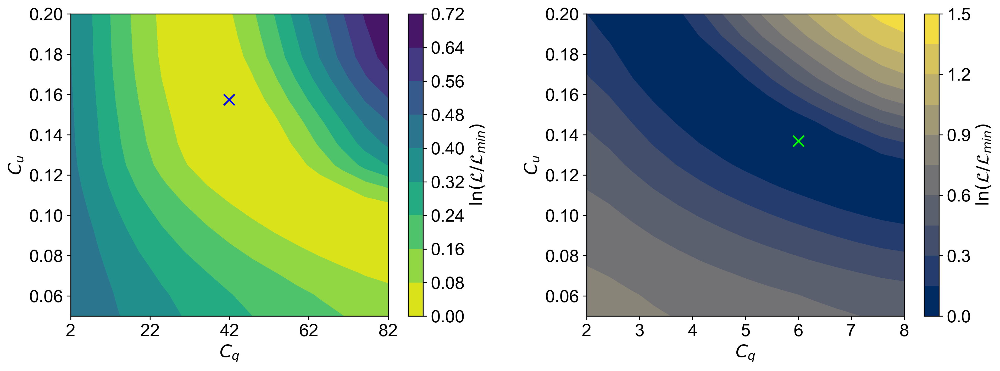

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plt.subplots_adjust(wspace=0.3)

ax1 = axes[1]
cf1 = ax1.contourf(Cq_vals_tk_2d, Cut_vals_tk_2d, 
                   np.log(loss_grid_tk2d_1 / np.min(loss_grid_tk2d_1)), 
                   levels=10, cmap='cividis')
ax1.scatter(Cq2tk, Cu2tk , 
            color='#00FF00', marker='x', s=100, label="Min Loss")
ax1.set_xlabel('$C_q$')
ax1.set_ylabel('$C_u$')
plt.colorbar(cf1, ax=ax1, label='$\\ln(\\mathcal{L}/\\mathcal{L}_{min})$')

ax2 = axes[0]
cf2 = ax2.contourf(Cq_vals_tk_2d2, Cut_vals_tk_2d, 
                   np.log(loss_grid_tk2d_2 / np.min(loss_grid_tk2d_2)), 
                   levels=10, cmap='viridis_r')
ax2.scatter(Cq1tk, Cu1tk , 
            color='b', marker='x', s=100, label="Min Loss")
ax2.set_xlabel('$C_q$')
ax2.set_ylabel('$C_u$')
ax2.set_xticks([2, 22, 42, 62, 82])
plt.colorbar(cf2, ax=ax2, label='$\\ln(\\mathcal{L}/\\mathcal{L}_{min})$')

## For the White Sands Dune Field Period 1

In [ ]:
def fromfactor_tolossfunction_ws(ut,Cq,lsat,dt,dw,start_time,end_time):

    dw_period1 = dw.where((dw.time >= start_time) & (dw.time <= end_time) & (dw.speed_proj*kap/np.log(10/z00) >=ut), drop=True)
    # dw_period1 = dw.where((dw.time >= start_time) & (dw.time <= end_time) & (dw.speed!=0) , drop=True)
    dw_period1['stree_velocity'] = dw_period1['speed_proj']*kap/np.log(10/z00)

    us=dw_period1['stree_velocity'].mean().item()#representative value
    dt['uxs'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dt.x.data,dt.y.data,dt.zb.where(~dt.zb.isnull(),dt.zp).data,d,us,nu),us).real)
    dt['uxs'] = dt.uxs.where(dt.zb.isnull(),0).clip(0,None)


    dt = dt.assign_coords(time=dw_period1.time.data)
    dt['ux'] = (('time'),dw_period1['stree_velocity'].data)
    dt['uxt'] = dt.ux/us*dt.uxs

    dt['uxspt'] = dt.uxt.mean('time')

    dt['qs'] = (dt.uxt**2-ut**2)*Cq*ut*rhof/rhos_ws*grav
    dt['qs'] = dt.qs.where(dt.qs>0,0)
    dt['qs'] = dt.qs.where(dt.qdem > 2, other=0)
    dt['qs'] = dt.qs.fillna(0)


    dx = dt.x.isel(x=slice(None,2)).diff('x').data[0]
    q = np.zeros(dt.qs.shape) # true flux array initialised
    q[:,0] = 0 # input true flux at x=0, here just arbitrary
    dx=dt.x.isel(x=slice(None,2)).diff('x').data[0]
    for i in range(1,q.shape[1]):
        q[:,i] = (q[:,i-1]+dx*dt.qs.data[:,i]/lsat)/(1+dx/lsat) # loop through and make true flux
    dt['q'] = (('time','x','y'),q)
    dt['qspt'] = dt.q.mean('time') * 365.25 * 24
    # dt['qspt'] = dt.q.mean('time').where(dt.qdem>2,other=0) * 365.25 * 24

    q_spt=[]
    q_dem=[]

    spatial_factor = 2

    for y_disp in range((dt.y.size-501//spatial_factor)//2, (dt.y.size-501//spatial_factor)//2+501//spatial_factor):
        z_y=dt.z[(dt.x.size-1500//spatial_factor)//2:(dt.x.size-1500//spatial_factor)//2+1500//spatial_factor,y_disp]
        qspt_y=dt.qspt[(dt.x.size-1500//spatial_factor)//2:(dt.x.size-1500//spatial_factor)//2+1500//spatial_factor,y_disp]
        qdem_y=dt.qdem[(dt.x.size-1500//spatial_factor)//2:(dt.x.size-1500//spatial_factor)//2+1500//spatial_factor,y_disp]

        #find valleys to divide 2D dune profile into segments 
        peaks, properties = find_peaks(-z_y, prominence=0.5, distance=80)
        del properties
        valley_pos = peaks[z_y[peaks] < 3]
        del peaks

        # find qcrest of dem and spt(fft)
        for x_disp in range(1,len(valley_pos)):
            startIDx=valley_pos[x_disp-1]
            endIDx=valley_pos[x_disp]
            segment_z=z_y[startIDx:endIDx]
            segment_qspt=qspt_y[startIDx:endIDx]
            segment_qdem=qdem_y[startIDx:endIDx]

            q_spt.append(segment_qspt[segment_z.values ==segment_z.max().values])
            q_dem.append(segment_qdem[segment_z.values ==segment_z.max().values])




    q_spt = np.array(q_spt, dtype=np.float64).flatten()
    q_dem = np.array(q_dem, dtype=np.float64).flatten()
    mask = q_dem != 0
    
    return np.mean(np.abs(q_dem[mask] - q_spt[mask]) / q_dem[mask])

In [51]:
padsl = -1/6
recth = np.tan(-18*np.pi/180)
recsl = -1/6

start_time = pd.Timestamp(dfws.t[0].item()).tz_localize('UTC')
end_time = pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')

zdata=dfws.zre[0].values[3000:4500,:]
dt = xr.Dataset(data_vars=dict(z=(['x','y'],zdata)),
                coords=dict(x=(['x'],np.arange(zdata.shape[0])),
                            y=(['y'],np.arange(zdata.shape[1]))))

dt = make_pad(dt,'z','zp',padsl)
dt = make_bubble(dt,'zp','zb',recth,recsl)
qdata=dfws.qre[0].values[3000:4500,:]
qdem = np.zeros(dt.z.shape)
x_offset = (dt.x.size- qdata.shape[0]) // 2
y_offset = (dt.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dt['qdem'] = (('x','y'),qdem)

dt = dt.coarsen(x=2, y=2, boundary='pad').mean()


zdata=dfws.zre[0].values[3000:4500,:]
dtup = xr.Dataset(data_vars=dict(z=(['x','y'],zdata)),
                coords=dict(x=(['x'],np.arange(zdata.shape[0])),
                            y=(['y'],np.arange(zdata.shape[1]))))

dtup = make_pad(dtup,'z','zp',padsl)
dtup = make_bubble(dtup,'zp','zb',recth,recsl)
qdata=dfws.qre_upper[0].values[3000:4500,:]
qdem = np.zeros(dtup.z.shape)
x_offset = (dtup.x.size- qdata.shape[0]) // 2
y_offset = (dtup.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dtup['qdem'] = (('x','y'),qdem)

dtup = dtup.coarsen(x=2, y=2, boundary='pad').mean()


zdata=dfws.zre[0].values[3000:4500,:]
dtdown = xr.Dataset(data_vars=dict(z=(['x','y'],zdata)),
                coords=dict(x=(['x'],np.arange(zdata.shape[0])),
                            y=(['y'],np.arange(zdata.shape[1]))))

dtdown = make_pad(dtdown,'z','zp',padsl)
dtdown = make_bubble(dtdown,'zp','zb',recth,recsl)
qdata=dfws.qre_lower[0].values[3000:4500,:]
qdem = np.zeros(dtdown.z.shape)
x_offset = (dtdown.x.size- qdata.shape[0]) // 2
y_offset = (dtdown.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dtdown['qdem'] = (('x','y'),qdem)

dtdown = dtdown.coarsen(x=2, y=2, boundary='pad').mean()

In [ ]:
# This block will cost more than 30 minutes to run using Apple M4, so we save the results and use/load it directly. 
# def objective(params):
#     ut, Cq,lsat = params
#     return fromfactor_tolossfunction_ws(ut,Cq,lsat,dt,dwws_period1,start_time,end_time)


# # x0 = [0.32,6,1.7]

# x0 = [0.35,5,2]

# # bounds
# bounds = [(0.2, 0.4),  # uth range
#         (2, 8), # Cq range
#         (0.1,3)]  # Clsat range

# res0 = minimize(objective, x0, method='L-BFGS-B',bounds=bounds)


np.savez('/Users/ylin0188/Desktop/code box/dfsframework code/1streview/optimazation_WS_P0.npz',res0)

data = np.load('/Users/ylin0188/Desktop/code box/dfsframework code/1streview/optimazation_WS_P0.npz', allow_pickle=True)
res0= data['arr_0'].item()
del data

print("Optimazation Results:")
print("uth =", res0.x[0])
print("Cq   =", res0.x[1])
print("lsat   =", res0.x[2])

Optimazation Results:
uth = 0.3395920017977553
Cq   = 4.999963729410683
lsat   = 2.0011373747822647


In [ ]:
lsat_vals_ws0 = np.linspace(1, 5, 48)/(rhof/(rhos_ws*d_ws))
loss_gridlsat_ws0 = np.zeros(len(lsat_vals_ws0))
loss_gridlsat_ws0up = np.zeros(len(lsat_vals_ws0))
loss_gridlsat_ws0down = np.zeros(len(lsat_vals_ws0))

for j, lsat in enumerate(lsat_vals_ws0):
    loss_gridlsat_ws0[j] = fromfactor_tolossfunction_ws(res0.x[0],res0.x[1],lsat,dt,dwws_period1,start_time,end_time)
    loss_gridlsat_ws0up[j] = fromfactor_tolossfunction_ws(res0.x[0],res0.x[1],lsat,dtup,dwws_period1,start_time,end_time)
    loss_gridlsat_ws0down[j] = fromfactor_tolossfunction_ws(res0.x[0],res0.x[1],lsat,dtdown,dwws_period1,start_time,end_time)
    print(f"lsat: {lsat:.2f}", end='\r')

In [ ]:
loss_norm = loss_gridlsat_ws0 / np.min(loss_gridlsat_ws0)
loss_norm_up = loss_gridlsat_ws0up / np.min(loss_gridlsat_ws0up)
loss_norm_down = loss_gridlsat_ws0down / np.min(loss_gridlsat_ws0down)

min_idx = np.argmin(loss_norm)
min_idx_up = np.argmin(loss_norm_up)
min_idx_down = np.argmin(loss_norm_down)

Clws01=lsat_vals_ws0[min_idx]*(rhof/(rhos_ws*d_ws))
Clws01up=lsat_vals_ws0[min_idx_up]*(rhof/(rhos_ws*d_ws))
Clws01down=lsat_vals_ws0[min_idx_down]*(rhof/(rhos_ws*d_ws))
print(Clws01,Clws01up,Clws01down)

In [ ]:
uth_val_ws0 = np.linspace(0.05, 0.2, 20)/np.sqrt(rhof/(rhos_ws*grav*d_ws))
loss_griduth_ws0 = np.zeros(len(uth_val_ws0))
lsat_ws0 =lsat_vals_ws0[np.log(loss_gridlsat_ws0/np.min(loss_gridlsat_ws0))==0]

loss_griduth_ws0up = np.zeros(len(uth_val_ws0))
loss_griduth_ws0down = np.zeros(len(uth_val_ws0))


for j, uth in enumerate(uth_val_ws0):
    loss_griduth_ws0[j] = fromfactor_tolossfunction_ws(uth,res0.x[1],lsat_ws0,dt,dwws_period1,start_time,end_time)
    loss_griduth_ws0up[j] = fromfactor_tolossfunction_ws(uth,res0.x[1],lsat_ws0,dtup,dwws_period1,start_time,end_time)
    loss_griduth_ws0down[j] = fromfactor_tolossfunction_ws(uth,res0.x[1],lsat_ws0,dtdown,dwws_period1,start_time,end_time)
    print(f"uth: {uth:.2f}", end='\r')

In [ ]:
loss_norm = loss_griduth_ws0 / np.min(loss_gridlsat_ws0)
loss_norm_up = loss_griduth_ws0up / np.min(loss_gridlsat_ws0up)
loss_norm_down = loss_griduth_ws0down / np.min(loss_gridlsat_ws0down)

min_idx = np.argmin(loss_norm)
min_idx_up = np.argmin(loss_norm_up)
min_idx_down = np.argmin(loss_norm_down)

Cuws01=uth_val_ws0 [min_idx]*np.sqrt(rhof/(rhos_ws*grav*d_ws))
Cuws01up=uth_val_ws0 [min_idx_up]*np.sqrt(rhof/(rhos_ws*grav*d_ws))
Cuws01down=uth_val_ws0[min_idx_down]*np.sqrt(rhof/(rhos_ws*grav*d_ws))
print(Cuws01,Cuws01up,Cuws01down)

In [ ]:
Cq_vals_ws0 = np.linspace(2,8,50)
loss_gridCq_ws0 = np.zeros(len(Cq_vals_ws0))
loss_gridCq_ws0up = np.zeros(len(Cq_vals_ws0))
loss_gridCq_ws0down = np.zeros(len(Cq_vals_ws0))

for i, Cq in enumerate(Cq_vals_ws0):
    loss_gridCq_ws0[i] = fromfactor_tolossfunction_ws(res0.x[0],Cq,res0.x[2],dt,dwws_period1,start_time,end_time)
    loss_gridCq_ws0up[i] = fromfactor_tolossfunction_ws(res0.x[0],Cq,res0.x[2],dtup,dwws_period1,start_time,end_time)
    loss_gridCq_ws0down[i] = fromfactor_tolossfunction_ws(res0.x[0],Cq,res0.x[2],dtdown,dwws_period1,start_time,end_time)
    print(f"Cq: {Cq:.2f}", end='\r')

In [63]:
loss_norm = loss_gridCq_ws0 / np.min(loss_gridCq_ws0)
loss_norm_up = loss_gridCq_ws0up / np.min(loss_gridCq_ws0up)
loss_norm_down = loss_gridCq_ws0down / np.min(loss_gridCq_ws0down)

min_idx = np.argmin(loss_norm)
min_idx_up = np.argmin(loss_norm_up)
min_idx_down = np.argmin(loss_norm_down)

Cqws01=Cq_vals_ws0[min_idx]
Cqws01up=Cq_vals_ws0[min_idx_up]
Cqws01down=Cq_vals_ws0[min_idx_down]
print(Cqws01,Cqws01up,Cqws01down)

4.938775510204081 4.816326530612245 5.428571428571429


In [ ]:
Cut_vals_ws2D = np.linspace(0.05,0.2,10)  
Cq_vals_ws2D = np.linspace(2, 8, 15) 
loss_grid2D_ws0 = np.zeros((len(Cut_vals_ws2D), len(Cq_vals_ws2D)))

for i, Cut in enumerate(Cut_vals_ws2D):
    for j, Cq in enumerate(Cq_vals_ws2D):
        loss_grid2D_ws0[i, j] = fromfactor_tolossfunction_ws(Cut/np.sqrt(rhof/(rhos_ws*grav*d_ws)),Cq,2,dt,dwws_period1,start_time,end_time)
        print(f"Cut: {Cut:.2f}, Cq: {Cq:.2f}", end='\r')

In [ ]:
# # it will take more than 2 hours (apple M4) to run the 3D grid of loss function values of two WS cases, so i save the results to a .npz file
# Cq_vals_ws = np.linspace(2, 8, 10)
# Cut_vals_ws = np.linspace(0.05,0.2,10)
# Clsat_vals_ws = np.linspace(1,5,10)


# loss_grid_ws03d = np.zeros((len(Cut_vals_ws), len(Cq_vals_ws),len(Clsat_vals_ws)))
# for i in range(len(Cut_vals_ws)):
#     for j in range(len(Cq_vals_ws)):
#         for k in range(len(Clsat_vals_ws)):
#             loss_grid_ws03d[i,j,k] = fromfactor_tolossfunction_ws(Cut_vals_ws[i]/np.sqrt(rhof/(rhos_ws*grav*d_ws)),Cq_vals_ws[j],Clsat_vals_ws[k],dt,dwws_period1,start_time,end_time)
            

## For the White Sands Dune Field Period 2

In [54]:
start_time = pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')
end_time = pd.Timestamp(dfws.t[2].item()).tz_localize('UTC')

zdata=dfws.zre[1].values[3000:4500,:]
dt = xr.Dataset(data_vars=dict(z=(['x','y'],zdata)),
                coords=dict(x=(['x'],np.arange(zdata.shape[0])),
                            y=(['y'],np.arange(zdata.shape[1]))))

dt = make_pad(dt,'z','zp',padsl)
dt = make_bubble(dt,'zp','zb',recth,recsl)
qdata=dfws.qre[1].values[3000:4500,:]
qdem = np.zeros(dt.z.shape)
x_offset = (dt.x.size- qdata.shape[0]) // 2
y_offset = (dt.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dt['qdem'] = (('x','y'),qdem)

dt = dt.coarsen(x=2, y=2, boundary='pad').mean()


zdata=dfws.zre[1].values[3000:4500,:]
dtup = xr.Dataset(data_vars=dict(z=(['x','y'],zdata)),
                coords=dict(x=(['x'],np.arange(zdata.shape[0])),
                            y=(['y'],np.arange(zdata.shape[1]))))

dtup = make_pad(dtup,'z','zp',padsl)
dtup = make_bubble(dtup,'zp','zb',recth,recsl)
qdata=dfws.qre_upper[1].values[3000:4500,:]
qdem = np.zeros(dtup.z.shape)
x_offset = (dtup.x.size- qdata.shape[0]) // 2
y_offset = (dtup.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dtup['qdem'] = (('x','y'),qdem)

dtup = dtup.coarsen(x=2, y=2, boundary='pad').mean()


zdata=dfws.zre[1].values[3000:4500,:]
dtdown = xr.Dataset(data_vars=dict(z=(['x','y'],zdata)),
                coords=dict(x=(['x'],np.arange(zdata.shape[0])),
                            y=(['y'],np.arange(zdata.shape[1]))))

dtdown = make_pad(dtdown,'z','zp',padsl)
dtdown = make_bubble(dtdown,'zp','zb',recth,recsl)
qdata=dfws.qre_lower[1].values[3000:4500,:]
qdem = np.zeros(dtdown.z.shape)
x_offset = (dtdown.x.size- qdata.shape[0]) // 2
y_offset = (dtdown.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dtdown['qdem'] = (('x','y'),qdem)

dtdown = dtdown.coarsen(x=2, y=2, boundary='pad').mean()

In [ ]:
# # This block will cost ~20 minutes to run using Apple M4, so we save the results and use/load it directly. 
# def objective(params):
#     ut, Cq ,lsat= params
#     return fromfactor_tolossfunction_ws(ut,Cq,lsat,dt,dwws_period2,start_time,end_time)


# x0 = [0.35,4.5,2]  

# # bounds
# bounds = [(0.2, 0.4),  # uth range
#         (2, 8),
#         (1,3)]  # Klsat range



# res1 = minimize(objective, x0, method='L-BFGS-B',bounds=bounds)

# np.savez('/Users/ylin0188/Desktop/code box/dfsframework code/1streview/optimazation_WS_P1.npz',res1)

data = np.load('/Users/ylin0188/Desktop/code box/dfsframework code/1streview/optimazation_WS_P1.npz', allow_pickle=True)
res1= data['arr_0'].item()
del data

print("Optimazation Results:")
print("uth =", res1.x[0])
print("Cq   =", res1.x[1])
print("lsat   =", res1.x[2])

Optimazation Results:
uth = 0.34339496587021345
Cq   = 4.655882507458344
lsat   = 2.007609462397844


In [ ]:
lsat_vals_ws1 =  np.linspace(1, 5, 48)/(rhof/(rhos_ws*d_ws))     
loss_gridlsat_ws1 = np.zeros(len(lsat_vals_ws1))
loss_gridlsat_ws1up = np.zeros(len(lsat_vals_ws1))
loss_gridlsat_ws1down = np.zeros(len(lsat_vals_ws1))

for j, lsat in enumerate(lsat_vals_ws1):
    loss_gridlsat_ws1[j] = fromfactor_tolossfunction_ws(res1.x[0],res1.x[1],lsat,dt,dwws_period2,start_time,end_time)
    loss_gridlsat_ws1up[j] = fromfactor_tolossfunction_ws(res1.x[0],res1.x[1],lsat,dtup,dwws_period2,start_time,end_time)
    loss_gridlsat_ws1down[j] = fromfactor_tolossfunction_ws(res1.x[0],res1.x[1],lsat,dtdown,dwws_period2,start_time,end_time)
    print(f"lsat: {lsat:.2f}", end='\r')

In [ ]:
loss_norm = loss_gridlsat_ws1 / np.min(loss_gridlsat_ws1)
loss_norm_up = loss_gridlsat_ws1up / np.min(loss_gridlsat_ws1up)
loss_norm_down = loss_gridlsat_ws1down / np.min(loss_gridlsat_ws1down)

min_idx = np.argmin(loss_norm)
min_idx_up = np.argmin(loss_norm_up)
min_idx_down = np.argmin(loss_norm_down)

Clws02=lsat_vals_ws1[min_idx]*(rhof/(rhos_ws*d_ws))    
Clws02up=lsat_vals_ws1[min_idx_up]*(rhof/(rhos_ws*d_ws))    
Clws02down=lsat_vals_ws1[min_idx_down]*(rhof/(rhos_ws*d_ws))    
print(Clws02,Clws02up,Clws02down)

2.276595744680851 1.9361702127659575 2.5319148936170213


In [ ]:
Cq_vals_ws1 = np.linspace(2, 8, 45)
loss_gridCq_ws1 = np.zeros(len(Cq_vals_ws1))
loss_gridCq_ws1up = np.zeros(len(Cq_vals_ws1))
loss_gridCq_ws1down = np.zeros(len(Cq_vals_ws1))

for i, Cq in enumerate(Cq_vals_ws1):
    loss_gridCq_ws1[i] = fromfactor_tolossfunction_ws(res1.x[0],Cq,res1.x[2],dt,dwws_period2,start_time,end_time)
    loss_gridCq_ws1up[i] = fromfactor_tolossfunction_ws(res1.x[0],Cq,res1.x[2],dtup,dwws_period2,start_time,end_time)
    loss_gridCq_ws1down[i] = fromfactor_tolossfunction_ws(res1.x[0],Cq,res1.x[2],dtdown,dwws_period2,start_time,end_time)
    print(f"Cq: {Cq:.2f}", end='\r')

# plt.plot(Cq_vals_ws1, loss_gridCq_ws1)

In [ ]:
loss_norm = loss_gridCq_ws1 / np.min(loss_gridCq_ws1)
loss_norm_up = loss_gridCq_ws1up / np.min(loss_gridCq_ws1up)
loss_norm_down = loss_gridCq_ws1down / np.min(loss_gridCq_ws1down)

min_idx = np.argmin(loss_norm)
min_idx_up = np.argmin(loss_norm_up)
min_idx_down = np.argmin(loss_norm_down)

Cqws02=Cq_vals_ws1[min_idx]
Cqws02up=Cq_vals_ws1[min_idx_up]
Cqws02down=Cq_vals_ws1[min_idx_down]
print(Cqws02,Cqws02up,Cqws02down)

4.5636363636363635 4.427272727272727 4.836363636363637


In [ ]:
uth_val_ws1 = np.linspace(0.05, 0.20, 40)/np.sqrt(rhof/(rhos_ws*grav*d_ws))   
loss_griduth_ws1 = np.zeros(len(uth_val_ws1))
loss_griduth_ws1up = np.zeros(len(uth_val_ws1))
loss_griduth_ws1down = np.zeros(len(uth_val_ws1))
lsat_ws1 =lsat_vals_ws1[np.log(loss_gridlsat_ws1/np.min(loss_gridlsat_ws1))==0]

for j, uth in enumerate(uth_val_ws1):
    loss_griduth_ws1[j] = fromfactor_tolossfunction_ws(uth,res1.x[1],lsat_ws1,dt,dwws_period2,start_time,end_time)
    loss_griduth_ws1up[j] = fromfactor_tolossfunction_ws(uth,res1.x[1],lsat_ws1,dtup,dwws_period2,start_time,end_time)
    loss_griduth_ws1down[j] = fromfactor_tolossfunction_ws(uth,res1.x[1],lsat_ws1,dtdown,dwws_period2,start_time,end_time)
    print(f"uth: {uth:.2f}", end='\r')

In [ ]:
loss_norm = loss_griduth_ws1 / np.min(loss_griduth_ws1)
loss_norm_up = loss_griduth_ws1up / np.min(loss_griduth_ws1up)
loss_norm_down = loss_griduth_ws1down / np.min(loss_griduth_ws1down)

min_idx = np.argmin(loss_norm)
min_idx_up = np.argmin(loss_norm_up)
min_idx_down = np.argmin(loss_norm_down)

Cuws02=uth_val_ws1[min_idx]*np.sqrt(rhof/(rhos_ws*grav*d_ws))      
Cuws02up=uth_val_ws1[min_idx_up]*np.sqrt(rhof/(rhos_ws*grav*d_ws))   
Cuws02down=uth_val_ws1[min_idx_down]*np.sqrt(rhof/(rhos_ws*grav*d_ws))   
print(Cuws02,Cuws02up,Cuws02down)

0.13461538461538464 0.12692307692307694 0.13846153846153847


In [ ]:
Cut_vals_ws2D = np.linspace(0.05,0.2,10)  
Cq_vals_ws2D = np.linspace(2, 8, 15) 
loss_grid2D_ws1 = np.zeros((len(Cut_vals_ws2D), len(Cq_vals_ws2D)))

for i, Cut in enumerate(Cut_vals_ws2D):
    for j, Cq in enumerate(Cq_vals_ws2D):
        loss_grid2D_ws1[i, j] = fromfactor_tolossfunction_ws(Cut/np.sqrt(rhof/(rhos_ws*grav*d_ws)),Cq,res1.x[2],dt,dwws_period2,start_time,end_time)
        print(f"Csat: {Cut:.2f}, Cq: {Cq:.2f}", end='\r')

In [ ]:
# # it will take more than 2 hours (apple M4) to run the 3D grid of loss function values of two WS cases, so i save the results to a .npz file
# Cq_vals_ws = np.linspace(2, 8, 10)
# Cut_vals_ws = np.linspace(0.05,0.2,10)
# Clsat_vals_ws = np.linspace(1,5,10)
# # loss_data = np.load('/Users/ylin0188/Desktop/code box/dfsframework code/White Sands/loss_grid_3D_forWS.npz', allow_pickle=True)
# # loss_grid_ws13d= loss_data['loss_grid_ws13d']
# # loss_grid_ws03d= loss_data['loss_grid_ws03d']


# loss_grid_ws13d = np.zeros((len(Cut_vals_ws), len(Cq_vals_ws),len(Clsat_vals_ws)))
# for i in range(len(Cut_vals_ws)):
#     for j in range(len(Cq_vals_ws)):
#         for k in range(len(Clsat_vals_ws)):
#             loss_grid_ws13d[i,j,k] = fromfactor_tolossfunction_ws(Cut_vals_ws[i]/np.sqrt(rhof/(rhos_ws*grav*d_ws)),Cq_vals_ws[j],Clsat_vals_ws[k],dt,dwws_period2,start_time,end_time)
            

In [ ]:
# np.savez('/Users/ylin0188/Desktop/code box/dfsframework code/new_3dlossdata3.npz', 
#          loss_grid_ws03d=loss_grid_ws03d, 
#          loss_grid_ws13d=loss_grid_ws13d)

data = np.load('/Users/ylin0188/Desktop/code box/dfsframework code/new_3dlossdata3.npz')
loss_grid_ws03d = data['loss_grid_ws03d']
loss_grid_ws13d = data['loss_grid_ws13d']

Cq_vals_ws = np.linspace(2, 8, 10)
Cut_vals_ws = np.linspace(0.05,0.2,10)
Clsat_vals_ws = np.linspace(1,5,10)

## Figure S4 F

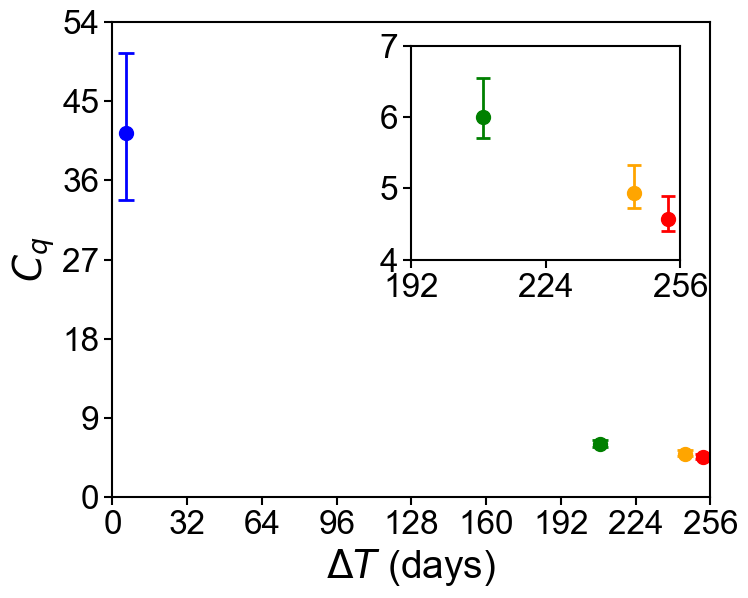

In [2]:
def exp_func(x, a, b, c):
    return a * np.exp(-b * x) + c

x_data = np.array([
    (pd.Timestamp(dfws.t[1].item()).tz_localize('UTC') - 
     pd.Timestamp(dfws.t[0].item()).tz_localize('UTC')).total_seconds() / (24 * 3600),
    
    (pd.Timestamp(dfws.t[2].item()).tz_localize('UTC') - 
     pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')).total_seconds() / (24 * 3600),
    
    (pd.Timestamp(dftk.time[1].item()).tz_localize('UTC') - 
     pd.Timestamp(dftk.time[0].item()).tz_localize('UTC')).total_seconds() / (24 * 3600),
    
    (pd.Timestamp(dftk.time[2].item()).tz_localize('UTC') - 
     pd.Timestamp(dftk.time[1].item()).tz_localize('UTC')).total_seconds() / (24 * 3600)
])

y_data = np.array([Cqws01, Cqws02, Cqtk02, Cqtk01])
y_data_down = np.array([Cqws01down, Cqws02down, Cqtk02down, Cqtk01down])
y_data_up = np.array([Cqws01up, Cqws02up, Cqtk02up, Cqtk01up]) 

popt, pcov = curve_fit(exp_func, x_data, y_data, p0=[10, 0.01, 5])
a, b, c = popt



fig, ax = plt.subplots(figsize=(6, 4.5))

ax.errorbar([x_data[0]], [y_data[0]],
    yerr=[[np.abs(Cqws01 - Cqws01down)], [np.abs(Cqws01up - Cqws01)]],
    fmt='o', color='orange', capsize=5)
ax.errorbar([x_data[1]], [y_data[1]],
    yerr=[[np.abs(Cqws02 - Cqws02down)], [np.abs(Cqws02up - Cqws02)]],
    fmt='ro', capsize=5)
ax.errorbar([x_data[2]], [y_data[2]],
    yerr=[[np.abs(Cqtk02 - Cqtk02down)], [np.abs(Cqtk02up - Cqtk02)]],
    fmt='bo', capsize=5)
ax.errorbar([x_data[3]], [y_data[3]],
    yerr=[[np.abs(Cqtk01 - Cqtk01down)], [np.abs(Cqtk01up - Cqtk01)]],
    fmt='go', capsize=5)


ax.set_xlim([0, 256])
ax.set_xticks(np.arange(0, 257, 32))
ax.set_ylim([0, 54])
ax.set_yticks(np.arange(0, 55, 9))
ax.set_xlabel('$\Delta T$ (days)')
ax.set_ylabel('$C_q$')

axins = inset_axes(ax, width="150%", height="150%", loc='upper right',
                   bbox_to_anchor=(0.65, 0.65, 0.3, 0.3),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

x_zoom = x_data[(x_data >= 192) & (x_data <= 256)]
y_zoom = y_data[(x_data >= 192) & (x_data <= 256)]
y_zoomup = y_data_up[(x_data >= 192) & (x_data <= 256)]
y_zoomdown= y_data_down[(x_data >= 192) & (x_data <= 256)]

axins.errorbar([x_zoom[0]], [y_zoom[0]],
    yerr=[[np.abs(y_zoomup[0] - y_zoom[0])], [np.abs(y_zoomdown[0] - y_zoom[0])]],
    fmt='o', color='orange', capsize=3)

axins.errorbar([x_zoom[1]], [y_zoom[1]],
    yerr=[[np.abs(y_zoomup[1] - y_zoom[1])], [np.abs(y_zoomdown[1] - y_zoom[1])]],
    fmt='ro', capsize=3)

axins.errorbar([x_zoom[2]], [y_zoom[2]],
    yerr=[[np.abs(y_zoomup[2] - y_zoom[2])],[np.abs(y_zoomdown[2] - y_zoom[2])] ],
    fmt='go', capsize=3)


axins.set_xlim(192, 256)
axins.set_ylim(4, 7)
axins.set_xticks([192, 224, 256])
# axins.set_yticks([27, 33, 40])

plt.subplots_adjust(left=0.1, right=0.85, top=0.92, bottom=0.1)
plt.show()

In [ ]:
def compute_loss_stats(loss, loss_up, loss_down):
    log_loss = np.log(loss / np.min(loss))
    log_loss_up = np.log(loss_up / np.min(loss_up))
    log_loss_down = np.log(loss_down / np.min(loss_down))
    
    loss_mean = log_loss
    loss_min = np.minimum.reduce([log_loss, log_loss_up, log_loss_down])
    loss_max = np.maximum.reduce([log_loss, log_loss_up, log_loss_down])
    
    return loss_mean, loss_min, loss_max

sigma = 1
loss_mean_Cq0, loss_min_Cq0, loss_max_Cq0 = compute_loss_stats(
    loss_gridCq_ws0, loss_gridCq_ws0up, loss_gridCq_ws0down
)

loss_mean_Lsat0, loss_min_Lsat0, loss_max_Lsat0 = compute_loss_stats(
    loss_gridlsat_ws0, loss_gridlsat_ws0up, loss_gridlsat_ws0down
)

loss_mean_uth0, loss_min_uth0, loss_max_uth0 = compute_loss_stats(
    gaussian_filter1d(loss_griduth_ws0, sigma=sigma), gaussian_filter1d(loss_griduth_ws0up, sigma=sigma), gaussian_filter1d(loss_griduth_ws0down, sigma=sigma)
)

x_smooth = np.linspace(uth_val_ws0.min(), uth_val_ws0.max(), 300)
cs_mean0 = CubicSpline(uth_val_ws0, loss_mean_uth0)
cs_up0 = CubicSpline(uth_val_ws0, loss_min_uth0)
cs_down0 = CubicSpline(uth_val_ws0, loss_max_uth0)


loss_mean_Cq1, loss_min_Cq1, loss_max_Cq1 = compute_loss_stats(
    loss_gridCq_ws1, loss_gridCq_ws1up, loss_gridCq_ws1down
)

loss_mean_Lsat1, loss_min_Lsat1, loss_max_Lsat1 = compute_loss_stats(
    loss_gridlsat_ws1, loss_gridlsat_ws1up, loss_gridlsat_ws1down
)

loss_mean_uth1, loss_min_uth1, loss_max_uth1 = compute_loss_stats(
    gaussian_filter1d(loss_griduth_ws1, sigma=sigma), gaussian_filter1d(loss_griduth_ws1up, sigma=sigma), gaussian_filter1d(loss_griduth_ws1down, sigma=sigma)
)


cs_mean1 = CubicSpline(uth_val_ws1, loss_mean_uth1)
cs_up1 = CubicSpline(uth_val_ws1,  loss_min_uth1)
cs_down1 = CubicSpline(uth_val_ws1, loss_max_uth1)


loss_mean_Cqtk, loss_min_Cqtk, loss_max_Cqtk = compute_loss_stats(
    loss_gridCq_tk, loss_gridCq_tkup, loss_gridCq_tkdown
)

loss_mean_Lsattk, loss_min_Lsattk, loss_max_Lsattk = compute_loss_stats(
    loss_gridlsat_tk, loss_gridlsat_tkup, loss_gridlsat_tkdown
)

loss_mean_uthtk, loss_min_uthtk, loss_max_uthtk = compute_loss_stats(
    gaussian_filter1d(loss_griduth_tk, sigma=sigma), gaussian_filter1d(loss_griduth_tkup, sigma=sigma), gaussian_filter1d(loss_griduth_tkdown, sigma=sigma)
)

## Figure 4 E-G

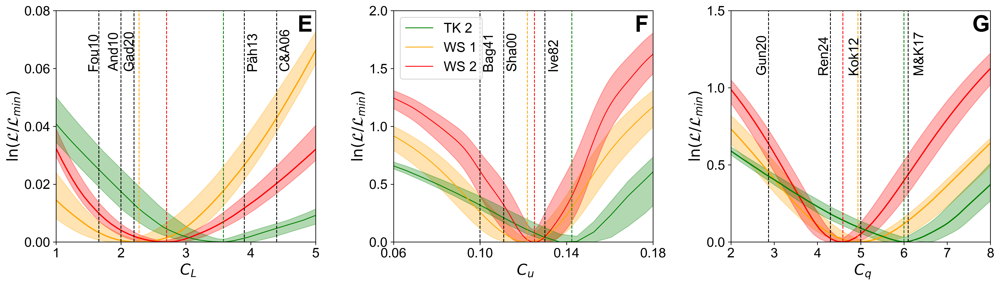

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(20, 5))
fs=9
plt.rcParams['font.size'] = 16 # standard font size


Cqo_mf = Cq_vals_tk_forCq[np.log(loss_gridCq_tk/np.min(loss_gridCq_tk))==0]
Cqo_ws1 =Cq_vals_ws1[np.log(loss_gridCq_ws1/np.min(loss_gridCq_ws1))==0]
Cqo_ws0 = Cq_vals_ws0[np.log(loss_gridCq_ws0/np.min(loss_gridCq_ws0))==0]

ax[2].plot(Cq_vals_ws0,np.log(loss_gridCq_ws0/np.min(loss_gridCq_ws0)),color='orange')
ax[2].fill_between(Cq_vals_ws0, loss_min_Cq0, loss_max_Cq0, color='orange', alpha=0.3)
ax[2].plot(Cq_vals_ws1,np.log(loss_gridCq_ws1/np.min(loss_gridCq_ws1)),color='red')
ax[2].fill_between(Cq_vals_ws1, loss_min_Cq1, loss_max_Cq1, color='red', alpha=0.3)
ax[2].plot(Cq_vals_tk_forCq,np.log(loss_gridCq_tk/np.min(loss_gridCq_tk)),color='green')
ax[2].fill_between(Cq_vals_tk_forCq, loss_min_Cqtk, loss_max_Cqtk, color='green', alpha=0.3)
ax[2].plot(Cqo_mf*np.ones(100), np.linspace(0,10,100),'g--', linewidth=1)
ax[2].plot(Cqo_ws1*np.ones(100), np.linspace(0,10,100),'r--', linewidth=1)
ax[2].plot(Cqo_ws0*np.ones(100), np.linspace(0,10,100),'--', color='orange',linewidth=1)

ax[2].set_xlim(2,8)
ax[2].set_xticks(np.linspace(2,8,7))
ax[2].set_ylim(0,1.5)
ax[2].set_yticks(np.linspace(0,1.5,4))
ax[2].set_xlabel(r" $C_{q}$",fontsize=18)
ax[2].set_ylabel('$\\ln(\\mathcal{L}/\\mathcal{L}_{min})$',fontsize=18)


ax[2].plot(5*np.ones(100), np.linspace(0,2,100),'k--', linewidth=1)
ax[2].text(5-0.3, 1.1, "Kok12", color="black", fontsize=fs*1.8,rotation=90)

ax[2].plot(2.87*np.ones(100), np.linspace(0,2,100),'k--', linewidth=1)
ax[2].text(2.87-0.3, 1.1, "Gun20", color="black", fontsize=fs*1.8,rotation=90)

ax[2].plot(4.3*np.ones(100), np.linspace(0,2,100),'k--', linewidth=1)
ax[2].text(4.3-0.3, 1.1, "Ren24", color="black", fontsize=fs*1.8,rotation=90)

ax[2].plot(6.1*np.ones(100), np.linspace(0,2,100),'k--', linewidth=1)
ax[2].text(6.1+0.1, 1.1, "M&K17", color="black", fontsize=fs*1.8,rotation=90)

x1 = uth_vals_tkforCu * np.sqrt(rhof/(rhos_tk*grav*d_tk))
y1 = np.log(loss_griduth_tk/np.min(loss_griduth_tk))
cs1 = CubicSpline(x1, y1, bc_type='natural')
x1_smooth = np.linspace(x1.min(), x1.max(), 100)

ax[1].plot(uth_vals_tkforCu*np.sqrt(rhof/(rhos_tk*grav*d_tk))   , loss_mean_uthtk, 'g-', linewidth=1)
ax[1].plot(x_smooth*np.sqrt(rhof/(rhos_tk*grav*d_ws))   , cs_mean0(x_smooth), '-', color='orange',linewidth=1)
ax[1].plot(x_smooth*np.sqrt(rhof/(rhos_tk*grav*d_ws))   , cs_mean1(x_smooth), 'r-', linewidth=1)

ax[1].fill_between(x_smooth*np.sqrt(rhof/(rhos_tk*grav*d_ws))   , cs_up0(x_smooth), cs_down0(x_smooth), color='orange', alpha=0.3)
ax[1].fill_between(x_smooth*np.sqrt(rhof/(rhos_tk*grav*d_ws))   , cs_up1(x_smooth), cs_down1(x_smooth), color='r', alpha=0.3)
ax[1].fill_between(uth_vals_tkforCu*np.sqrt(rhof/(rhos_tk*grav*d_tk))   , loss_min_uthtk, loss_max_uthtk, color='g', alpha=0.3)

ax[1].legend(['TK 2','WS 1','WS 2'], fontsize=fs*1.8, loc='upper left')

utho_tk = x1_smooth[cs1(x1_smooth)==np.min(cs1(x1_smooth))]
utho_ws0 = x_smooth[cs_mean0(x_smooth)==np.min(cs_mean0(x_smooth))]*np.sqrt(rhof/(rhos_tk*grav*d_ws))
utho_ws1 =x_smooth[cs_mean1(x_smooth)==np.min(cs_mean1(x_smooth))]*np.sqrt(rhof/(rhos_tk*grav*d_ws)) 



ax[1].plot(utho_tk*np.ones(100), np.linspace(0,10,100),'g--', linewidth=1)
ax[1].plot(utho_ws0*np.ones(100), np.linspace(0,10,100),'--',color='orange', linewidth=1)
ax[1].plot(utho_ws1*np.ones(100), np.linspace(0,10,100),'--', color='red',linewidth=1)

ax[1].plot(0.1*np.ones(100), np.linspace(0,10,100),'k--',linewidth=1)
ax[1].text(0.1+0.001, 1.5, "Bag41", color="k", fontsize=fs*1.8,rotation=90)
ax[1].plot(0.111*np.ones(100), np.linspace(0,10,100),'k--',linewidth=1)
ax[1].text(0.111+0.001, 1.5, "Sha00", color="k", fontsize=fs*1.8,rotation=90)
ax[1].plot(0.13*np.ones(100), np.linspace(0,10,100),'k--',linewidth=1)
ax[1].text(0.13+0.001, 1.5, "Ive82", color="k", fontsize=fs*1.8,rotation=90)

ax[1].set_xlim(0.06,0.18)
ax[1].set_xticks(np.linspace(0.06,0.18,4))
ax[1].set_ylim(0,2)
ax[1].set_yticks(np.linspace(0,2,5))
ax[1].set_xlabel(r" $C_{u}$",fontsize=18)
ax[1].set_ylabel('$\\ln(\\mathcal{L}/\\mathcal{L}_{min})$',fontsize=18)


ax[0].plot(rhof*lsat_vals_ws1/(rhos_ws*d_ws),np.log(loss_gridlsat_ws1/np.min(loss_gridlsat_ws1)),color='orange')
ax[0].fill_between(lsat_vals_ws1*(rhof/(rhos_ws*d_ws)), loss_min_Lsat1, loss_max_Lsat1, color='orange', alpha=0.3)
ax[0].plot(rhof*lsat_vals_ws0/(rhos_ws*d_ws),np.log(loss_gridlsat_ws0/np.min(loss_gridlsat_ws0)),color='red')
ax[0].fill_between(lsat_vals_ws0*(rhof/(rhos_ws*d_ws)), loss_min_Lsat0, loss_max_Lsat0, color='red', alpha=0.3)
ax[0].plot(lsat_vals_tkforCl*(rhof/(rhos_tk*d_tk))/3.8, loss_mean_Lsattk, 'g-', linewidth=1)
ax[0].fill_between(lsat_vals_tkforCl*(rhof/(rhos_tk*d_tk))/3.8   , loss_min_Lsattk, loss_max_Lsattk, color='g', alpha=0.3)

lsat_mf = lsat_vals_tkforCl[np.log(loss_gridlsat_tk/np.min(loss_gridlsat_tk))==0]
lsat_ws1 =lsat_vals_ws1[np.log(loss_gridlsat_ws1/np.min(loss_gridlsat_ws1))==0]
lsat_ws0 = lsat_vals_ws0[np.log(loss_gridlsat_ws0/np.min(loss_gridlsat_ws0))==0]

ax[0].plot(rhof/(rhos_tk*d_tk)*lsat_mf*np.ones(100)/3.8, np.linspace(0,1,100),'g--', linewidth=1)
ax[0].plot(rhof/(rhos_ws*d_ws)*lsat_ws0*np.ones(100), np.linspace(0,1,100),'r--', linewidth=1)
ax[0].plot(rhof/(rhos_ws*d_ws)*lsat_ws1*np.ones(100), np.linspace(0,1,100),'--', color='orange',linewidth=1)

ax[0].plot(2.2*np.ones(100), np.linspace(0,1,100),'k--',linewidth=1)
ax[0].text(2.03, 0.06, "Gad20", color="k", fontsize=fs*1.8,rotation=90)

ax[0].plot(2*np.ones(100), np.linspace(0,1,100),'k--',linewidth=1)
ax[0].text(1.8, 0.06, "And10", color="k", fontsize=fs*1.8,rotation=90)

ax[0].plot(3.9*np.ones(100), np.linspace(0,1,100),'k--',linewidth=1)
ax[0].text(3.93, 0.06, "Päh13", color="k", fontsize=fs*1.8,rotation=90)

ax[0].plot(4.4*np.ones(100), np.linspace(0,1,100),'k--',linewidth=1)
ax[0].text(4.43, 0.06, "C&A06", color="k", fontsize=fs*1.8,rotation=90)

ax[0].plot(1.66*np.ones(100), np.linspace(0,1,100),'k--',linewidth=1)
ax[0].text(1.48, 0.06, "Fou10", color="k", fontsize=fs*1.8,rotation=90)

ax[0].set_xlim(1,5)
ax[0].set_xticks(np.arange(1,5.0001,1))
ax[0].set_ylim(0,0.08)
ax[0].set_yticks(np.arange(0,0.08+0.00001,0.02))

ax[0].set_xlabel(r" $C_{L}$",fontsize=18)
ax[0].set_ylabel('$\\ln(\\mathcal{L}/\\mathcal{L}_{min})$',fontsize=18)


ax[2].text(0.93, 0.98, "G", transform=ax[2].transAxes, fontsize=fs * 3, fontweight='bold', va='top',color='k')
ax[1].text(0.93, 0.98, "F", transform=ax[1].transAxes, fontsize=fs * 3, fontweight='bold', va='top',color='k')
ax[0].text(0.93, 0.98, "E", transform=ax[0].transAxes, fontsize=fs * 3, fontweight='bold', va='top',color='k')

plt.subplots_adjust(wspace=0.3)

## Figure 4 A-B

Text(0.05, 0.95, 'D')

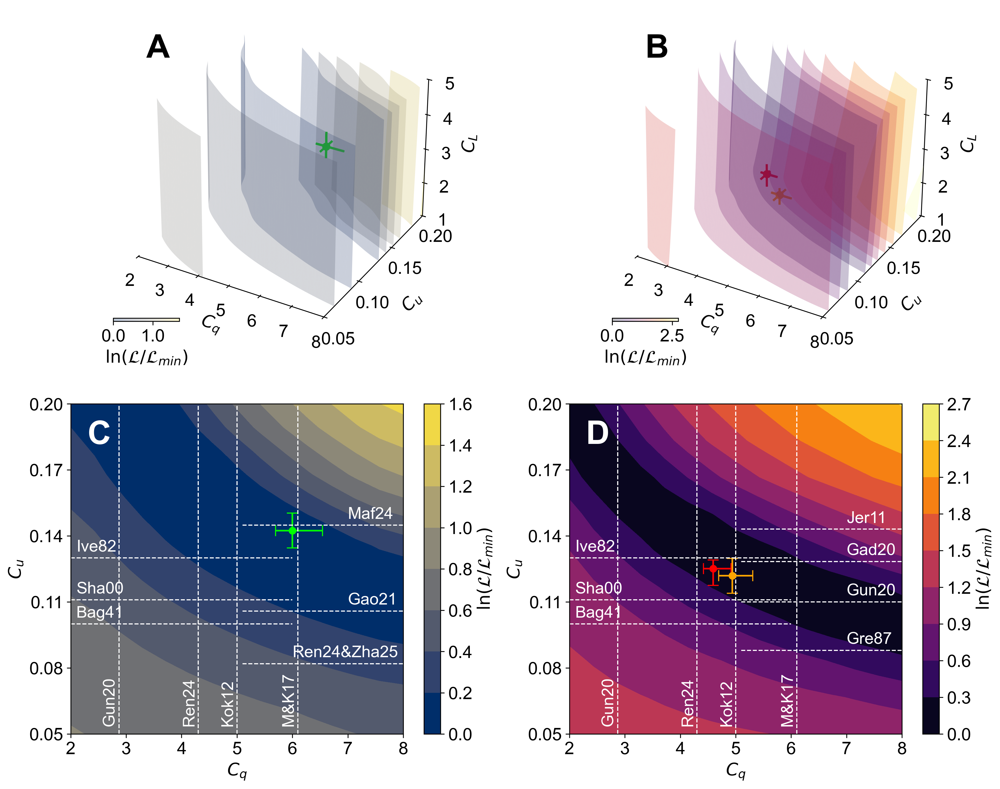

In [ ]:
fs=10
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(15, 12))
plt.rcParams['font.size'] = 16 # standard font size

ngrid = 100 # higher resolution interpolation of normalised loss
nlevels = 7
lossinterp = RegularGridInterpolator((Cq_vals_tk,Cut_vals_tk,Clsat_vals_tk),np.log(loss_grid_tk3d/np.min(loss_grid_tk3d)),method='cubic') # make interpolator function
Clinterp,Cuinterp,Ckinterp = np.linspace(Cq_vals_tk[0],Cq_vals_tk[-1],ngrid),np.linspace(Cut_vals_tk[0],Cut_vals_tk[-1],ngrid),np.linspace(Clsat_vals_tk[0],Clsat_vals_tk[-1],ngrid) # make higher resolution axes
lossinterp = lossinterp(np.meshgrid(Clinterp,Cuinterp,Ckinterp,indexing='ij')) # overwrite function with higher resolution interpolated normalised loss array
lossinterp -= lossinterp.min() # because of cubic interpolation, the minimum will no longer be 'zero', offset it


levels = np.linspace(0,np.floor(lossinterp.max()*(nlevels-1))/(nlevels-1),nlevels)
cmapname = 'cividis'
cmap = mpl.colormaps[cmapname]
colors = cmap(np.linspace(0,1,nlevels))

ax[0,0].remove()
ax[0,0] = fig.add_subplot(2, 2, 1, projection='3d')
for i in range(nlevels):
    verts,faces,_,_ = marching_cubes(lossinterp,spacing=(Clinterp[1]-Clinterp[0],Cuinterp[1]-Cuinterp[0],Ckinterp[1]-Ckinterp[0]),level=levels[i])
    verts[:, 0] = Clinterp[0] + verts[:, 0]
    verts[:, 1] = Cuinterp[0] + verts[:, 1]
    verts[:, 2] = Ckinterp[0] + verts[:, 2]
    mesh = Poly3DCollection(verts[faces],linewidth=0,color=colors[i],alpha=.25)
    ax[0,0].add_collection3d(mesh)
ax[0,0].set_xlabel('$C_{q}$')
ax[0,0].set_ylabel('$C_{u}$',labelpad=10)
ax[0,0].set_zlabel('$C_{L}$')
ax[0,0].set_xlim(Clinterp[0], Clinterp[-1])
ax[0,0].set_ylim(Cuinterp[0], Cuinterp[-1])
ax[0,0].set_zlim(Ckinterp[0], Ckinterp[-1])
ax[0,0].set_yticks(np.linspace(Cuinterp[0], Cuinterp[-1],4))
ax[0,0].set_zticks(np.linspace(Ckinterp[0], Ckinterp[-1],5))


# ax[0,0].set_yticklabels([0.08,0.13,0.18])
ax[0,0].xaxis.pane.fill = False
ax[0,0].yaxis.pane.fill = False
ax[0,0].zaxis.pane.fill = False
ax[0,0].xaxis.pane.set_edgecolor('w')
ax[0,0].yaxis.pane.set_edgecolor('w')
ax[0,0].zaxis.pane.set_edgecolor('w')
ax[0,0].grid(False)
pcm = ax[0,0].scatter(0,0,s=0,c=0,vmin=levels[0],vmax=levels[-1],cmap=cmapname)
cax = ax[0,0].inset_axes([0,0.05,0.2,0.01], transform=ax[0,0].transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal',shrink=.05)
cbar.solids.set_alpha(0.25)
cbar.ax.xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
cbar.ax.set_xlabel('$\\ln(\\mathcal{L}/\\mathcal{L}_{min})$')
ax[0,0].scatter(res_tk1.x[1], utho_tk , Cltk01, color='#00FF00',marker='o', s=30,linewidth=2)

x = res_tk1.x[1]
y = utho_tk
z = Cltk01
xerr1 = Cqtk01-Cqtk01up
xerr2 = Cqtk01down-Cqtk01
yerr1 = Cutk01-Cutk01up
yerr2 = Cutk01down-Cutk01
zerr1 = Cltk01-Cltk01up
zerr2 = Cltk01down-Cltk01
ax[0,0].plot([x - xerr1, x + xerr2],[y, y],[z, z],color='#00FF00',linewidth=2)
ax[0,0].plot([x, x],[y - yerr1, y + yerr2],[z, z],color='#00FF00',linewidth=2)
ax[0,0].plot([x, x],[y, y],[z - zerr1, z + zerr2],color='#00FF00',linewidth=2)



ngrid = 100 # higher resolution interpolation of normalised loss
nlevels = 8
smoothed_loss = 0.5*(loss_grid_ws03d+loss_grid_ws13d)
smoothed_loss = np.swapaxes(smoothed_loss, 0, 1)
lossinterp = RegularGridInterpolator((Cq_vals_ws,Cut_vals_ws,Clsat_vals_ws),np.log(smoothed_loss/smoothed_loss.min()),method='cubic') # make interpolator function

Clinterp,Cuinterp,Ckinterp = np.linspace(Cq_vals_ws[0],Cq_vals_ws[-1],ngrid),np.linspace(Cut_vals_ws[0],Cut_vals_ws[-1],ngrid),np.linspace(Clsat_vals_ws[0],Clsat_vals_ws[-1],ngrid) # make higher resolution axes
lossinterp = lossinterp(np.meshgrid(Clinterp,Cuinterp,Ckinterp,indexing='ij')) # overwrite function with higher resolution interpolated normalised loss array
lossinterp -= lossinterp.min() # because of cubic interpolation, the minimum will no longer be 'zero', offset it
levels = np.linspace(0,np.floor(lossinterp.max()*(nlevels-1))/(nlevels-1),nlevels)
cmapname = 'inferno'
cmap = mpl.colormaps[cmapname]
colors = cmap(np.linspace(0,1,nlevels))

ax[0,1].remove()
ax[0,1] = fig.add_subplot(2, 2, 2, projection='3d')
for i in range(nlevels):
    verts,faces,_,_ = marching_cubes(lossinterp,spacing=(Clinterp[1]-Clinterp[0],Cuinterp[1]-Cuinterp[0],Ckinterp[1]-Ckinterp[0]),level=levels[i])
    verts[:, 0] = Clinterp[0] + verts[:, 0]
    verts[:, 1] = Cuinterp[0] + verts[:, 1]
    verts[:, 2] = Ckinterp[0] + verts[:, 2]
    mesh = Poly3DCollection(verts[faces],linewidth=0,color=colors[i],alpha=.25)
    ax[0,1].add_collection3d(mesh)
ax[0,1].set_xlabel('$C_{q}$')
ax[0,1].set_ylabel('$C_{u}$',labelpad=10)
ax[0,1].set_zlabel('$C_{L}$')
ax[0,1].set_xlim(Clinterp[0], Clinterp[-1])
ax[0,1].set_ylim(Cuinterp[0], Cuinterp[-1])
ax[0,1].set_zlim(Ckinterp[0], Ckinterp[-1])
ax[0,1].set_yticks(np.linspace(Cuinterp[0], Cuinterp[-1],4))
ax[0,1].set_zticks(np.linspace(Ckinterp[0], Ckinterp[-1],5))


ax[0,1].xaxis.pane.fill = False
ax[0,1].yaxis.pane.fill = False
ax[0,1].zaxis.pane.fill = False
ax[0,1].xaxis.pane.set_edgecolor('w')
ax[0,1].yaxis.pane.set_edgecolor('w')
ax[0,1].zaxis.pane.set_edgecolor('w')
ax[0,1].grid(False)
pcm = ax[0,1].scatter(0,0,s=0,c=0,vmin=levels[0],vmax=2.75,cmap=cmapname)
cax = ax[0,1].inset_axes([0,0.05,0.2,0.01], transform=ax[0,1].transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal',shrink=.05)
cbar.solids.set_alpha(0.25)
cbar.ax.set_xlabel('$\\ln(\\mathcal{L}/\\mathcal{L}_{min})$')

ax[0,1].scatter(res0.x[1], utho_ws0, lsat_ws1*(rhof/(rhos_ws*d_ws)), color='orange',marker='o', s=30,linewidth=2)
ax[0,1].scatter(res1.x[1], utho_ws1, lsat_ws0*(rhof/(rhos_ws*d_ws)), color='red',marker='o', s=30,linewidth=2)


x = res0.x[1]
y = utho_ws0
z = lsat_ws1*(rhof/(rhos_ws*d_ws))
xerr1 = Cqws01-Cqws01up
xerr2 = Cqws01down-Cqws01
yerr1 = Cuws01-Cuws01up
yerr2 = Cuws01down-Cuws01
zerr1 = Clws01-Clws01up
zerr2 = Clws01down-Clws01
ax[0,1].plot([x - xerr1, x + xerr2],[y, y],[z, z],color='orange',linewidth=2)
ax[0,1].plot([x, x],[y - yerr1, y + yerr2],[z, z],color='orange',linewidth=2)
ax[0,1].plot([x, x],[y, y],[z - zerr1, z + zerr2],color='orange',linewidth=2)

x = res1.x[1]
y = utho_ws1
z = lsat_ws0*(rhof/(rhos_ws*d_ws))
xerr1 = Cqws02-Cqws02up-0.1
xerr2 = Cqws02down-Cqws02+0.05
yerr1 = Cuws02-Cuws02up
yerr2 = Cuws02down-Cuws02
zerr1 = Clws02-Clws02up
zerr2 = Clws02down-Clws02
ax[0,1].plot([x - xerr1, x + xerr2],[y, y],[z, z],color='red',linewidth=2)
ax[0,1].plot([x, x],[y - yerr1, y + yerr2],[z, z],color='red',linewidth=2)
ax[0,1].plot([x, x],[y, y],[z - zerr1, z + zerr2],color='red',linewidth=2)

c=ax[1,0].contourf(Cq_vals_tk_2d, Cut_vals_tk_2d, np.log(loss_grid_tk2d_1 / np.min(loss_grid_tk2d_1)), levels=8, cmap='cividis')
plt.colorbar(c, label='$\\ln(\\mathcal{L}/\\mathcal{L}_{min})$')
ax[1,0].set_xlabel("$C_{q}$")
ax[1,0].set_ylabel('$C_{u}$')
ax[1,0].set_xticks(np.linspace(Cq_vals_tk_2d[0],Cq_vals_tk_2d[-1],7))
ax[1,0].set_yticks(np.linspace(Cut_vals_tk_2d[0],Cut_vals_tk_2d[-1],6))
ax[1,0].errorbar(res_tk1.x[1], utho_tk, xerr=[[Cqtk01-Cqtk01up],[Cqtk01down-Cqtk01]], yerr=[[Cutk01-Cutk01up],[Cutk01down-Cutk01]], fmt='o', color='#00FF00', capsize=5)

ax[1,0].plot(5*np.ones(100), np.linspace(Cut_vals_tk_2d[0],Cut_vals_tk_2d[-1],100),'w--', linewidth=1)
ax[1,0].text(5-0.3, 0.055, "Kok12", color="white", fontsize=fs*1.5,rotation=90)

ax[1,0].plot(2.87*np.ones(100), np.linspace(Cut_vals_tk_2d[0],Cut_vals_tk_2d[-1],100),'w--', linewidth=1)
ax[1,0].text(2.87-0.3, 0.055, "Gun20", color="white", fontsize=fs*1.5,rotation=90)

ax[1,0].plot(6.1*np.ones(100), np.linspace(Cut_vals_tk_2d[0],Cut_vals_tk_2d[-1],100),'w--', linewidth=1)
ax[1,0].text(6.1-0.3, 0.055, "M&K17", color="white", fontsize=fs*1.5,rotation=90)

ax[1,0].plot(4.3*np.ones(100), np.linspace(Cut_vals_tk_2d[0],Cut_vals_tk_2d[-1],100),'w--', linewidth=1)
ax[1,0].text(4.3-0.3, 0.055, "Ren24", color="white", fontsize=fs*1.5,rotation=90)

ax[1,0].plot(np.linspace(5.1,8,100),0.151*np.ones(100)*np.sqrt(rhof/(rhos_tk*grav*d_tk)), 'w--', linewidth=1)
ax[1,0].text(6, 0.151*np.sqrt(rhof/(rhos_tk*grav*d_tk))+0.003, "Ren24&Zha25", color="white", fontsize=fs*1.5)

ax[1,0].plot(np.linspace(5.1,8,100),0.195*np.ones(100)*np.sqrt(rhof/(rhos_tk*grav*d_tk)), 'w--', linewidth=1)
ax[1,0].text(7, 0.195*np.sqrt(rhof/(rhos_tk*grav*d_tk))+0.003, "Gao21", color="white", fontsize=fs*1.5)

ax[1,0].plot(np.linspace(5.1,8,100),0.267*np.ones(100)*np.sqrt(rhof/(rhos_tk*grav*d_tk)), 'w--', linewidth=1)
ax[1,0].text(7, 0.267*np.sqrt(rhof/(rhos_tk*grav*d_tk))+0.003, "Maf24", color="white", fontsize=fs*1.5)

ax[1,0].plot(np.linspace(2,6,100),0.1*np.ones(100), 'w--', linewidth=1)
ax[1,0].text(2.1, 0.1+0.003, "Bag41", color="white", fontsize=fs*1.5)

ax[1,0].plot(np.linspace(2,6,100),0.111*np.ones(100), 'w--', linewidth=1)
ax[1,0].text(2.1, 0.111+0.003, "Sha00", color="white", fontsize=fs*1.5)

ax[1,0].plot(np.linspace(2,6,100),0.13*np.ones(100), 'w--', linewidth=1)
ax[1,0].text(2.1, 0.13+0.003, "Ive82", color="white", fontsize=fs*1.5)

z = (loss_grid2D_ws0 + loss_grid2D_ws1) / 2
c=ax[1,1].contourf(Cq_vals_ws2D, Cut_vals_ws2D, np.log(z/np.min(z)), levels=8, cmap='inferno')
plt.colorbar(c, label='$\\ln(\\mathcal{L}/\\mathcal{L}_{min})$')
ax[1,1].set_xlabel("$C_{q}$")
ax[1,1].set_xticks(np.linspace(Cq_vals_tk_2d[0],Cq_vals_tk_2d[-1],7))
ax[1,1].set_ylabel('$C_{u}$')
ax[1,1].set_yticks(np.linspace(Cut_vals_tk_2d[0],Cut_vals_tk_2d[-1],6))
ax[1,1].errorbar(Cqo_ws1, utho_ws1, xerr=[[Cqws02-Cqws02up],[Cqws02down-Cqws02]], yerr=[[Cuws02-Cuws02up],[Cuws02down-Cuws02]], fmt='o',color='red', ecolor='red', capsize=5)
# ax[1,1].scatter(Cqo_ws0, utho_ws0, color='orange', marker='x', s=100, label="Min Loss")
ax[1,1].errorbar(Cqo_ws0, utho_ws0, xerr=[[Cqws01-Cqws01up],[Cqws01down-Cqws01]], yerr=[[Cuws01-Cuws01up],[Cuws01down-Cuws01]], fmt='o',color='orange', ecolor='orange', capsize=5)
# ax[1,1].scatter(Cqo_ws1, utho_ws1, color='red', marker='o', s=5, label="Min Loss")

ax[1,1].plot(np.linspace(5.1,8,100),0.39*np.sqrt(rhof/(rhos_ws*grav*d_ws))*np.ones(100), 'w--', linewidth=1)
ax[1,1].text(7, 0.39*np.sqrt(rhof/(rhos_ws*grav*d_ws))+0.003, "Jer11", color="white", fontsize=fs*1.5)

ax[1,1].plot(np.linspace(5.1,8,100),0.3*np.sqrt(rhof/(rhos_ws*grav*d_ws))*np.ones(100), 'w--', linewidth=1)
ax[1,1].text(7, 0.3*np.sqrt(rhof/(rhos_ws*grav*d_ws))+0.003, "Gun20", color="white", fontsize=fs*1.5)

ax[1,1].plot(np.linspace(5.1,8,100),0.35*np.sqrt(rhof/(rhos_ws*grav*d_ws))*np.ones(100), 'w--', linewidth=1)
ax[1,1].text(7, 0.35*np.sqrt(rhof/(rhos_ws*grav*d_ws))+0.003, "Gad20", color="white", fontsize=fs*1.5)

ax[1,1].plot(np.linspace(5.1,8,100),0.24*np.sqrt(rhof/(rhos_ws*grav*d_ws))*np.ones(100), 'w--', linewidth=1)
ax[1,1].text(7, 0.24*np.sqrt(rhof/(rhos_ws*grav*d_ws))+0.003, "Gre87", color="white", fontsize=fs*1.5)

ax[1,1].plot(np.linspace(2,6,100),0.1*np.ones(100), 'w--', linewidth=1)
ax[1,1].text(2.1, 0.1+0.003, "Bag41", color="white", fontsize=fs*1.5)

ax[1,1].plot(np.linspace(2,6,100),0.111*np.ones(100), 'w--', linewidth=1)
ax[1,1].text(2.1, 0.111+0.003, "Sha00", color="white", fontsize=fs*1.5)

ax[1,1].plot(np.linspace(2,6,100),0.13*np.ones(100), 'w--', linewidth=1)
ax[1,1].text(2.1, 0.13+0.003, "Ive82", color="white", fontsize=fs*1.5)

ax[1,1].plot(5*np.ones(100), np.linspace(Cut_vals_ws2D[0],Cut_vals_ws2D[-1],100),'w--', linewidth=1)
ax[1,1].text(5-0.3, 0.055, "Kok12", color="white", fontsize=fs*1.5,rotation=90)

ax[1,1].plot(2.87*np.ones(100), np.linspace(Cut_vals_ws2D[0],Cut_vals_ws2D[-1],100),'w--', linewidth=1)
ax[1,1].text(2.87-0.3, 0.055, "Gun20", color="white", fontsize=fs*1.5,rotation=90)

ax[1,1].plot(4.3*np.ones(100), np.linspace(Cut_vals_ws2D[0],Cut_vals_ws2D[-1],100),'w--', linewidth=1)
ax[1,1].text(4.3-0.3, 0.055, "Ren24", color="white", fontsize=fs*1.5,rotation=90)

ax[1,1].plot(6.1*np.ones(100), np.linspace(Cut_vals_ws2D[0],Cut_vals_ws2D[-1],100),'w--', linewidth=1)
ax[1,1].text(6.1-0.3, 0.055, "M&K17", color="white", fontsize=fs*1.5,rotation=90)


ax[0,0].text2D(0.1, 0.92,"A", transform=ax[0,0].transAxes, fontsize=fs * 3, fontweight='bold', va='top',color='k')
ax[0,1].text2D(0.1, 0.92, "B", transform=ax[0,1].transAxes, fontsize=fs * 3, fontweight='bold', va='top',color='k')
ax[1,0].text(0.05, 0.95, "C", transform=ax[1,0].transAxes, fontsize=fs * 3, fontweight='bold', va='top',color='w')
ax[1,1].text(0.05, 0.95,"D", transform=ax[1,1].transAxes, fontsize=fs * 3, fontweight='bold', va='top',color='w')

# Table S3 Comparation of different optimization methods

## TK

In [332]:
start_time = pd.Timestamp(dftk.time[1].item()).tz_localize('UTC')
end_time = pd.Timestamp(dftk.time[2].item()).tz_localize('UTC')
sigma = 1
dttk = xr.Dataset(
    {
        'z': (('x', 'y'),gaussian_filter((dftk.dunemask[1] - dftk.dunemask[1].min()).
                                         fillna(0).values.astype(float), sigma=sigma))
    },
    coords={
        'x': (('x'), dftk.x.values - dftk.x.min().item()),
        'y': (('y'), dftk.y.values - dftk.y.min().item()),
    },
)

dttk = make_pad(dttk,'z','zp',padsl)
dttk= make_bubble(dttk,'zp','zb',recth,recsl)
dttk['zpb'] = xr.where(dttk.zb.isnull(), dttk.zp, dttk.zb)
dttk['zpbro'] = dttk.zpb-dttk.zp+dttk.z

qdata=dftk.qmask[1].values
qdem = np.zeros(dttk.z.shape)
x_offset = (dttk.x.size- qdata.shape[0]) // 2
y_offset = (dttk.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dttk['qdem'] = (('x','y'),qdem)

In [ ]:
def objective(params):
    ut, Cq ,lsat= params
    return fromfactor_tolossfunction(ut,Cq,lsat,dttk,dwtk_hourly1,z01,start_time,end_time)

# bounds
bounds = [(0.2, 0.4),  # uth range
        (2, 8), # Cq range
        (0,3)]  # Clsat range

res_tk_LBFGSB = minimize(objective, [0.269,6,1.2], method='L-BFGS-B',bounds=bounds)

print("Results (L-BFGS-B TK):")
print("uth =", res_tk_LBFGSB.x[0])
print("Cq   =", res_tk_LBFGSB.x[1])
print("lsat   =", res_tk_LBFGSB.x[2])

Results (L-BFGS-B TK):
uth = 0.2693034601524084
Cq   = 6.022406707166715
lsat   = 1.2012074744989407


In [ ]:
# bounds
bounds = [(0.2, 0.4),  # uth range
        (2, 8), # Cq range
        (0,3)]  # Clsat range

res_tk_TNC = minimize(objective, [0.265,6.5,1.1] , method='TNC', bounds=bounds,
                  options={'maxiter': 1000, 'eps': 1e-8, 'disp': True})

print("Results (TNC TK):")
print("uth =", res_tk_TNC.x[0])
print("Cq   =", res_tk_TNC.x[1])
print("lsat   =", res_tk_TNC.x[2])

  NIT   NF   F                       GTG
    0    1  2.804900645869679E+00   2.04556704E+00
    1    5  2.415814436258668E+00   2.66311601E-01
    2   11  2.412728917973120E+00   1.33000587E-01
    3   36  2.412664040312355E+00   1.31336653E-01
tnc: |fn-fn-1] = 8.88178e-16 -> convergence
    4   39  2.412664040312354E+00   1.31336645E-01
tnc: Converged (|f_n-f_(n-1)| ~= 0)


Results (TNC TK):
uth = 0.2653611495580232
Cq   = 5.959108448120938
lsat   = 1.1447685821416724


In [ ]:
# bounds
bounds = [(0.2, 0.4),  # uth range
        (2, 8), # Cq range
        (0,5)]  # Clsat range


res_tk_SLSQP = minimize(objective, [0.265,6,0.7], method='SLSQP', bounds=bounds,
                  options={'maxiter': 10000, 'ftol': 1e-8, 'disp': True})


print("Results (SLSQP TK):")
print("uth =", res_tk_SLSQP.x[0])
print("Cq   =", res_tk_SLSQP.x[1])
print("lsat   =", res_tk_SLSQP.x[2])

Optimization terminated successfully    (Exit mode 0)
            Current function value: 2.3377512875031874
            Iterations: 44
            Function evaluations: 321
            Gradient evaluations: 42
Results (SLSQP TK):
uth = 0.2627735911767258
Cq   = 6.01174104498972
lsat   = 1.4495941029994532


In [ ]:
import warnings
warnings.filterwarnings('ignore')

x0 = [0.25, 6, 1.2]  

bounds = [(0.2, 0.4), (2, 8), (0, 5)]

res_tk_tc = minimize(objective, x0, method='trust-constr', bounds=bounds,
                  options={'verbose': 1, 'maxiter': 1000, 'gtol': 1e-8})

print("Results (trust-constr TK):")
print("uth =", res_tk_tc.x[0])
print("Cq   =", res_tk_tc.x[1])
print("lsat   =", res_tk_tc.x[2])

`xtol` termination condition is satisfied.
Number of iterations: 349, function evaluations: 1992, CG iterations: 461, optimality: 3.26e+01, constraint violation: 0.00e+00, execution time: 4.3e+02 s.
Results (trust-constr TK):
uth = 0.26525010951155076
Cq   = 6.040114081986375
lsat   = 1.3334768734952143


In [ ]:
constraints = [NonlinearConstraint(lambda x: 0.25, 0.2, 0.4),
               NonlinearConstraint(lambda x: 6.2, 2, 8),
               NonlinearConstraint(lambda x: 0.7, 0, 1)]

res_tk_nm = minimize(objective, [0.25,5.9,1.2]  , method='Nelder-Mead', 
                  options={'maxiter': 1000, 'xatol': 1e-8, 'fatol': 1e-8, 'disp': True})


print("Results (Nelder-Mead TK):")
print("uth =", res_tk_nm.x[0])
print("Cq   =", res_tk_nm.x[1])
print("lsat   =", res_tk_nm.x[2])

Optimization terminated successfully.
         Current function value: 2.332794
         Iterations: 241
         Function evaluations: 464
Results (Nelder-Mead TK):
uth = 0.26428579900889604
Cq   = 6.020613159386574
lsat   = 1.290715950301308


## WS1

In [347]:
padsl = -1/6
recth = np.tan(-18*np.pi/180)
recsl = -1/6

start_time = pd.Timestamp(dfws.t[0].item()).tz_localize('UTC')
end_time = pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')

zdata=dfws.zre[0].values[3000:4500,:]
dt = xr.Dataset(data_vars=dict(z=(['x','y'],zdata)),
                coords=dict(x=(['x'],np.arange(zdata.shape[0])),
                            y=(['y'],np.arange(zdata.shape[1]))))

dt = make_pad(dt,'z','zp',padsl)
dt = make_bubble(dt,'zp','zb',recth,recsl)
qdata=dfws.qre[0].values[3000:4500,:]
qdem = np.zeros(dt.z.shape)
x_offset = (dt.x.size- qdata.shape[0]) // 2
y_offset = (dt.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dt['qdem'] = (('x','y'),qdem)

dt = dt.coarsen(x=2, y=2, boundary='pad').mean()

In [311]:
def objective(params):
    ut, Cq,lsat = params
    return fromfactor_tolossfunction_ws(ut,Cq,lsat,dt,dwws_period1,start_time,end_time)


x0 = [0.33,5,1.7]  

# bounds
bounds = [(0.2, 0.4),  # uth range
        (2, 8),    # Cq range
        (1.5,5)]  # Clsat range

res0_LBFGSB = minimize(objective, x0, method='L-BFGS-B',bounds=bounds)

print("Results (L-BFGS-B WS1):")
print("uth =", res0_LBFGSB.x[0])
print("Cq   =", res0_LBFGSB.x[1])
print("lsat   =", res0_LBFGSB.x[2])

Results (L-BFGS-B WS1):
uth = 0.32842007613022467
Cq   = 5.00029613333845
lsat   = 1.7001165947604422


In [ ]:
res0_TNC = minimize(objective, [0.35,5,1.7] , method='TNC', bounds=bounds,
                  options={'maxiter': 2000, 'eps': 1e-8, 'disp': True})

print("Results (TNC WS1):")
print("uth =", res0_TNC.x[0])
print("Cq   =", res0_TNC.x[1])
print("lsat   =", res0_TNC.x[2])

  NIT   NF   F                       GTG
    0    1  2.916800151874180E-01   1.22825196E-01
    1   27  2.872939247720524E-01   8.42420432E-02
    2   53  2.864418316074594E-01   4.29434290E-02
tnc: |fn-fn-1] = 1.94289e-15 -> convergence
    3   56  2.864418316074575E-01   4.29434290E-02
tnc: Converged (|f_n-f_(n-1)| ~= 0)


Results (TNC WS1):
uth = 0.3315879750482625
Cq   = 5.0190785203133705
lsat   = 1.885242106679362


In [ ]:
res0_SLSQP = minimize(objective, [0.35,5.05,1.7]  , method='SLSQP', bounds=bounds,
                  options={'maxiter': 1000, 'ftol': 1e-8, 'disp': True})

print("Results (SLSQP WS1):")
print("uth =", res0_SLSQP.x[0])
print("Cq   =", res0_SLSQP.x[1])
print("lsat   =", res0_SLSQP.x[2])

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.2880559652109222
            Iterations: 29
            Function evaluations: 227
            Gradient evaluations: 29
Results (SLSQP WS1):
uth = 0.32929053281171994
Cq   = 5.072351532985606
lsat   = 1.7056431992214025


## WS2

In [346]:
start_time = pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')
end_time = pd.Timestamp(dfws.t[2].item()).tz_localize('UTC')

zdata=dfws.zre[0].values[3000:4500,:]
dt = xr.Dataset(data_vars=dict(z=(['x','y'],zdata)),
                coords=dict(x=(['x'],np.arange(zdata.shape[0])),
                            y=(['y'],np.arange(zdata.shape[1]))))

dt = make_pad(dt,'z','zp',padsl)
dt = make_bubble(dt,'zp','zb',recth,recsl)
qdata=dfws.qre[1].values[3000:4500,:]
qdem = np.zeros(dt.z.shape)
x_offset = (dt.x.size- qdata.shape[0]) // 2
y_offset = (dt.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dt['qdem'] = (('x','y'),qdem)

dt = dt.coarsen(x=2, y=2, boundary='pad').mean()

In [ ]:
def objective(params):
    ut, Cq ,lsat= params
    return fromfactor_tolossfunction_ws(ut,Cq,lsat,dt,dwws_period2,start_time,end_time)

x0 = [0.34,4.5,2]  

# bounds
bounds = [(0.2, 0.4),  # uth range
        (2, 8), # Cq range
        (1.5,5)]  # Clsat range

res1_LBFGSB = minimize(objective, x0, method='L-BFGS-B',bounds=bounds)

print("Results (L-BFGS-B WS2):")
print("uth =", res1_LBFGSB.x[0])
print("Cq   =", res1_LBFGSB.x[1])
print("lsat   =", res1_LBFGSB.x[2])

Results (L-BFGS-B WS2):
uth = 0.34305652958941735
Cq   = 4.498915071076995
lsat   = 1.9938014789300993


In [ ]:
def objective(params):
    ut, Cq ,lsat= params
    return fromfactor_tolossfunction_ws(ut,Cq,lsat,dt,dwws_period2,start_time,end_time)

bounds = [(0.2, 0.4),  # uth range
        (2, 8),     # Cq range
        (1.5,5)]  # Clsat range

res1_TNC = minimize(objective, [0.34,4.5,2]    , method='TNC', bounds=bounds,
                  options={'maxiter': 1000, 'eps': 1e-8, 'disp': True})

print("Results (TNC WS2):")
print("uth =", res1_TNC.x[0])
print("Cq   =", res1_TNC.x[1])
print("lsat   =", res1_TNC.x[2])

  NIT   NF   F                       GTG
    0    1  2.579189582285655E-01   9.08944946E-02
    1    5  2.112228560294276E-01   7.26224377E-02
    2   28  2.096436025269598E-01   8.34756742E-03


Results (TNC WS2):
uth = 0.34458290038191747
Cq   = 4.514503854083973
lsat   = 2.1255012817417445


tnc: |fn-fn-1] = 4.4334e-09 -> convergence
    3   77  2.096435980935562E-01   8.34755971E-03
tnc: Converged (|f_n-f_(n-1)| ~= 0)


# Several Figure Supp

## Figure S5

In [ ]:
res1_SLSQP = minimize(objective, [0.34,4.5,2]  , method='SLSQP', bounds=bounds,
                  options={'maxiter': 200, 'ftol': 1e-8, 'disp': True})

print("Results (SLSQP WS2):")
print("uth =", res1_SLSQP.x[0])
print("Cq   =", res1_SLSQP.x[1])
print("lsat   =", res1_SLSQP.x[2])

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.21552673579852816
            Iterations: 13
            Function evaluations: 118
            Gradient evaluations: 13
Results (SLSQP WS2):
uth = 0.3466862027001076
Cq   = 4.527819266401579
lsat   = 1.996867604311022


In [230]:
def read_dem(file_path):

    with rasterio.open(file_path) as src:
        dem_data = src.read(1) 
        x_coords = np.linspace(src.bounds.left, src.bounds.right, src.width)
        y_coords = np.linspace(src.bounds.top, src.bounds.bottom, src.height)
        return dem_data
    

dem_datamf = read_dem('/Users/ylin0188/Desktop/code box/dfsframework code/TKbarchan250225.tif')
dem_datamf[dem_datamf<=0]=np.nan

repose = np.tan(30*np.pi/180)
z = dem_datamf[1:30000:470, 1:-1:470]
dzdx = np.gradient(z,axis=1)
dzdy = np.gradient(z,axis=0)
dzdx[(dzdx**2+dzdy**2)**0.5<repose] = np.nan
dzdy[(dzdx**2+dzdy**2)**0.5<repose] = np.nan
aez=np.arctan2(-dzdy,-dzdx)*180/np.pi
mask = (aez > 80) | (aez < -100)
aez[mask] = np.nan

valid_mask = ~np.isnan(aez)

dem_datamf_d=dem_datamf[0:30000:50,0:-1:50]

# calculate upscaling factors
scale_y = dem_datamf_d.shape[0] / aez.shape[0]
scale_x = dem_datamf_d.shape[1] / aez.shape[1]

# upscaling mask using nearest neighbor
valid_mask_upscaled = ndimage.zoom(valid_mask.astype(float), 
                                   (scale_y, scale_x), 
                                   order=0) > 0.5


# apply to full DEM
dem_full_masked = dem_datamf_d.copy()
dem_full_masked[~valid_mask_upscaled] = np.nan

dzdx = np.gradient(dem_datamf_d,axis=1)
dzdy = np.gradient(dem_datamf_d,axis=0)
angles=np.arctan2(-dzdy,-dzdx)*180/np.pi

angle_mask = (angles >= -90) & (angles <= 90) & ((dzdx**2+dzdy**2)**0.5>=0.06)
angles = angles.copy()
angles[~angle_mask] = np.nan

binary_image = angle_mask

# label connected components
labeled_array, num_features = ndimage.label(binary_image, structure=np.ones((3, 3)))

if num_features > 0:
    # calculte sizes of connected components
    sizes = ndimage.sum(binary_image, labeled_array, range(1, num_features + 1))
    
    # find the label of the largest connected component
    largest_label = np.argmax(sizes) + 1
    largest_size = sizes[largest_label - 1]
    
    # mask for the largest connected component
    largest_mask = labeled_array == largest_label

angles = angles.copy()
angles[~largest_mask] = np.nan

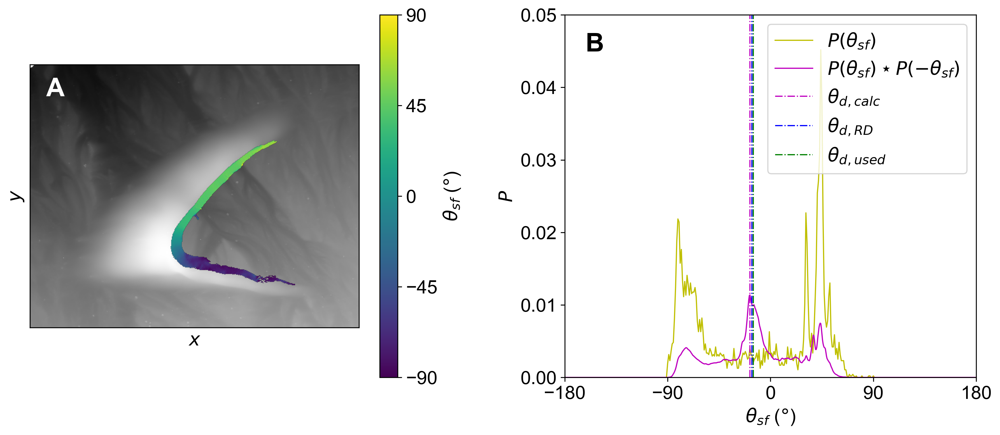

In [231]:
def ridspuriousangles(acnt,abinmids):
    ta = np.copy(acnt)
    for i in np.arange(-8,8)*45:
        ti = np.argwhere(abinmids==i)
        ta[ti] = (ta[ti-1]+ta[ti+1])/2
    ti = np.argwhere(abinmids==8*45)
    ta[-1] = (ta[-2]+ta[0])/2
    return ta

af0 = -15 # direction clockwise from east in degrees that the dunes move
d_flux = -16.228 # calculated flux dominant direction (shown in Figure 1)
da = 0.5
abins = np.arange(-360-da,360+2*da,2*da)
abinmids = abins[1:] - da


ae_ela_selected =angles
tempa = ae_ela_selected[~np.isnan(ae_ela_selected)]
acnt,_ = np.histogram(tempa,bins=abins)
tempc = ridspuriousangles(acnt,abinmids)
p = correlate(tempc,np.flip(tempc),mode='same')

tempdd = abinmids[np.argmax(p)]/2


plt.figure(figsize=(12, 5))

plt.subplot(1,2,1)
plt.imshow(dem_datamf_d, aspect='equal', cmap='gray')

plt.imshow(angles, aspect='equal')
cbar=plt.colorbar(label='$\\theta_{sf}$ ($\degree$)')
cbar.set_ticks([-90,-45,0,45,90])

plt.xlim(200,700)
plt.ylim(600,200)
plt.xticks([])
plt.yticks([])
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.tight_layout()
plt.text(0.05, 0.95, 'A', transform=plt.gca().transAxes,
         fontsize=22, fontweight='bold',color='w',
         verticalalignment='top')
# plt.legend()

plt.subplot(1,2,2)
plt.plot(abinmids,acnt/np.sum(acnt),c='y',lw=1,label='$P(\\theta_{sf})$')
plt.plot(abinmids/2,p/np.sum(p),c='m',lw=1,label='$P(\\theta_{sf})\\star P(-\\theta_{sf})$')
plt.plot([tempdd,tempdd],[0,1.2*np.max(acnt/np.sum(acnt))],'-.m',lw=1,label='$\\theta_{d,calc}$')
plt.plot([-16.228,-16.228],[0,1.2*np.max(acnt/np.sum(acnt))],'-.b',lw=1,label='$\\theta_{d,RD}$')
plt.plot([af0,af0],[0,1.2*np.max(acnt/np.sum(acnt))],'-.g',lw=1,label='$\\theta_{d,used}$')
plt.xlabel('$\\theta_{sf}$ ($\degree$)')
plt.ylabel('$P$')
plt.xlim(-180,180)
plt.xticks([-180,-90,0,90,180])
plt.ylim(0,0.05)
plt.legend()
plt.text(0.05, 0.95, 'B', transform=plt.gca().transAxes,
         fontsize=22, fontweight='bold',color='k',
         verticalalignment='top')

plt.subplots_adjust(wspace=0.3)


## Figure S2

/var/folders/hd/mh5dw4tx6516lkk5f82sfg481pk0nq/T/ipykernel_61406/757699085.py:44: RuntimeWarning: invalid value encountered in log10
  plt.pcolormesh(Re,Re_d,np.log10(abcd[i]*(-1 if i==2 else 1)).T,vmin=cbarticks[0],vmax=cbarticks[-1],cmap='summer')
/var/folders/hd/mh5dw4tx6516lkk5f82sfg481pk0nq/T/ipykernel_61406/757699085.py:46: RuntimeWarning: invalid value encountered in log10
  plt.pcolormesh(Re,Re_d,np.log10(abcd[i]*(-1 if i==2 else 1)).T,vmin=cbarticks[0],vmax=cbarticks[-1],cmap='autumn')


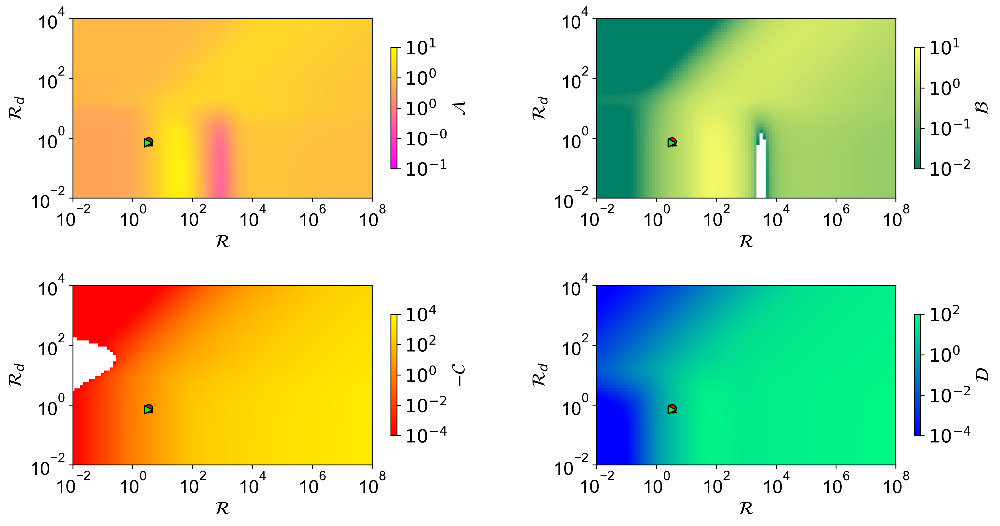

In [ ]:
Re_d = np.logspace(-2,4, 60+1) # Re for saved solutions
Re   = np.logspace(-2,8,100+1) # Re_d for saved solutions

with open('/Users/ylin0188/Desktop/code box/dfsframework code/abcd.txt','r') as f:
    lines = f.readlines()
    lines = [line.strip() for line in lines if line.strip() and not line.startswith('#')]
    abcd = np.array([list(map(float,line.split())) for line in lines]).reshape((4,len(Re),len(Re_d)))

cbartickss = [np.linspace(-1,1,4+1),
              np.linspace(-2,1,3+1),
              np.linspace(-4,4,4+1),
              np.linspace(-4,2,3+1)]
cbarlabels = ['$\\mathcal{A}$',
              '$\\mathcal{B}$',
              '$\\mathcal{-C}$',
              '$\\mathcal{D}$']

from scipy.fft import fftfreq
x=dtws.x.data
kx = 2*np.pi*fftfreq(len(x),d=x[1]-x[0])[:,None]
kx[kx==0] = 1e-10
us0=0.40
ab0=np.mean(get_ab(us0/nu/np.abs(kx),d_ws*1e-9*us0/nu),axis=1)
us1=0.42
ab1=np.mean(get_ab(us1/nu/np.abs(kx),d_ws*1e-9*us1/nu),axis=1)
x=dtws.x.data
kx = 2*np.pi*fftfreq(len(x),d=x[1]-x[0])[:,None]
kx[kx==0] = 1e-10
utk=0.32
abtk=np.mean(get_ab(utk/nu/np.abs(kx),d_tk*1e-9*utk/nu),axis=1)


# cbartickss = [np.linspace(-1,1,4+1),
#               np.linspace(-2,1,3+1)]
# cbarlabels = ['$\\mathcal{A}$',
#               '$\\mathcal{B}$']

plt.figure(figsize=(14,8),dpi=300)
for i,(cbarticks,cbarlabel) in enumerate(zip(cbartickss,cbarlabels)):
    plt.subplot(221+i)
    if i==0:
        plt.pcolormesh(Re,Re_d,np.log10(abcd[i]*(-1 if i==2 else 1)).T,vmin=cbarticks[0],vmax=cbarticks[-1],cmap='spring')
    if i==1:
        plt.pcolormesh(Re,Re_d,np.log10(abcd[i]*(-1 if i==2 else 1)).T,vmin=cbarticks[0],vmax=cbarticks[-1],cmap='summer')
    if i==2:
        plt.pcolormesh(Re,Re_d,np.log10(abcd[i]*(-1 if i==2 else 1)).T,vmin=cbarticks[0],vmax=cbarticks[-1],cmap='autumn')
    if i==3:
        plt.pcolormesh(Re,Re_d,np.log10(abcd[i]*(-1 if i==2 else 1)).T,vmin=cbarticks[0],vmax=cbarticks[-1],cmap='winter')
    cbar = plt.colorbar(label=cbarlabel,ticks=cbarticks,shrink=0.5)
    cbar.ax.set_yticklabels(['$10^{%.0f}$'%val for val in cbarticks])
    plt.xscale('log')
    plt.yscale('log')
    plt.axis('square')
    plt.xlim(Re[0],Re[-1])
    plt.ylim(Re_d[0],Re_d[-1])
    plt.xticks(np.logspace(-2,8,5+1))
    plt.yticks(np.logspace(-2,4,3+1))
    plt.xlabel('$\\mathcal{R}$')
    plt.ylabel('$\\mathcal{R}_d$')

    plt.scatter(ab0[0],ab0[1], s=50, marker='^', color='orange',edgecolors='k')
    plt.scatter(ab1[0],ab1[1],s=50, marker='o', color='r',edgecolors='k')
    plt.scatter(abtk[0],abtk[1],s=50,marker='>', color='#00FF00',edgecolors='k')


plt.subplots_adjust(wspace=0.4, hspace=0.1) 



## Figure S6 C-E

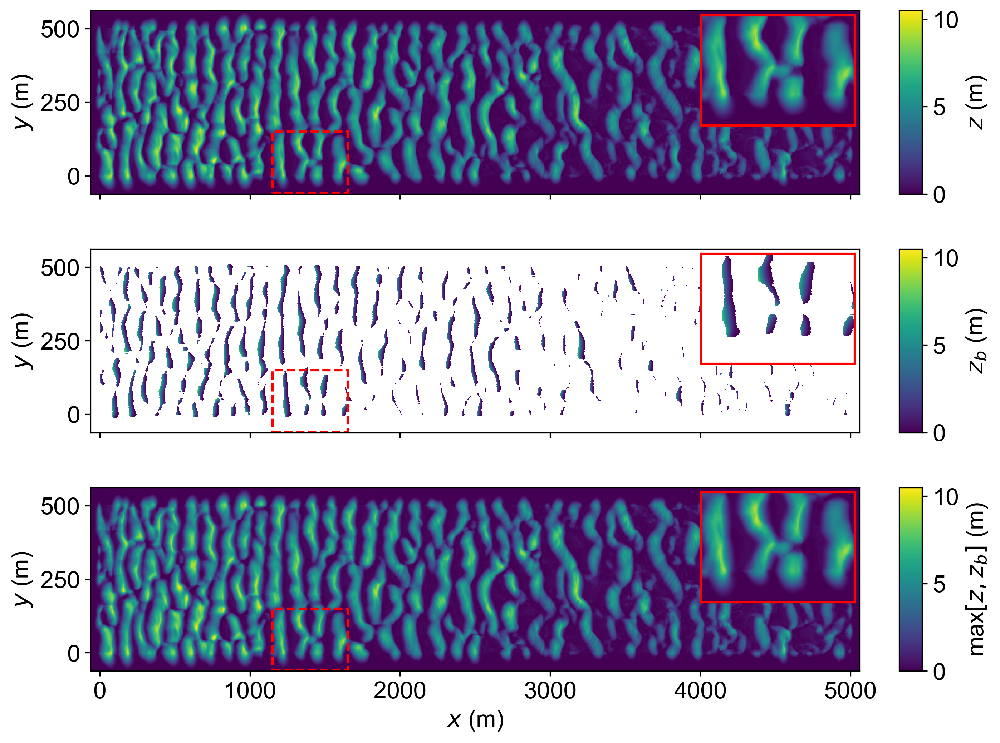

In [ ]:
plt.figure(figsize=(10, 8))

gs = gridspec.GridSpec(
    3, 2,                
    width_ratios=[10, 0.3], 
    height_ratios=[1, 1, 1],
    wspace=0.1, hspace=0.3 
)

ax0 = plt.subplot(gs[0, 0])
cx0 = plt.subplot(gs[0, 1])
im0 = ax0.pcolormesh(dtws.x, dtws.y, dtws.zp.T, vmin=0, vmax=10.5)
cbar0 = plt.colorbar(im0, cax=cx0, label='$z$ (m)')
ax0.set_yticks([0, 250, 500])
ax0.set_ylabel('$y$ (m)')
ax0.set_xticklabels([])

ax0_inset = inset_axes(ax0, width="20%", height="60%", loc='upper right', borderpad=0.2)
x_range = (1150, 1650)
y_range = (dtws.y.min()+1, 150)
x_mask = (dtws.x >= x_range[0]) & (dtws.x <= x_range[1])
y_mask = (dtws.y >= y_range[0]) & (dtws.y <= y_range[1])
ax0_inset.pcolormesh(dtws.x[x_mask], dtws.y[y_mask], dtws.zp[x_mask, :][:, y_mask].T, 
                     vmin=0, vmax=10.5)
ax0_inset.set_xlim(x_range)
ax0_inset.set_ylim(y_range)
ax0_inset.set_xticks([])
ax0_inset.set_yticks([])
ax0_inset.spines[:].set_color('red')
ax0_inset.spines[:].set_linewidth(1.5)

rect0 = plt.Rectangle((x_range[0], y_range[0]), 
                      x_range[1]-x_range[0], 
                      y_range[1]-y_range[0],
                      fill=False, edgecolor='red', linestyle='--', linewidth=1.5)
ax0.add_patch(rect0)


ax1 = plt.subplot(gs[1, 0])
cx1 = plt.subplot(gs[1, 1])
im1 = ax1.pcolormesh(dtws.x, dtws.y, dtws.zb.T, vmin=0, vmax=10.5)
cbar1 = plt.colorbar(im1, cax=cx1, label='$z_b$ (m)')
ax1.set_yticks([0, 250, 500])
ax1.set_xticklabels([])
ax1.set_ylabel('$y$ (m)')
ax1_inset = inset_axes(ax1, width="20%", height="60%", loc='upper right', borderpad=0.2)
ax1_inset.pcolormesh(dtws.x[x_mask], dtws.y[y_mask], dtws.zb[x_mask, :][:, y_mask].T, 
                     vmin=0, vmax=10.5)
ax1_inset.set_xlim(x_range)
ax1_inset.set_ylim(y_range)
ax1_inset.set_xticks([])
ax1_inset.set_yticks([])
ax1_inset.spines[:].set_color('red')
ax1_inset.spines[:].set_linewidth(1.5)

rect1 = plt.Rectangle((x_range[0], y_range[0]), 
                      x_range[1]-x_range[0], 
                      y_range[1]-y_range[0],
                      fill=False, edgecolor='red', linestyle='--', linewidth=1.5)
ax1.add_patch(rect1)


ax2 = plt.subplot(gs[2, 0])
cx2 = plt.subplot(gs[2, 1])
im2 = ax2.pcolormesh(dtws.x, dtws.y, dtws.zb.where(~dtws.zb.isnull(), dtws.zp).data.T, 
                     vmin=0, vmax=10.5)
cbar2 = plt.colorbar(im2, cax=cx2, label='max$[z,z_b]$ (m)')
ax2.set_yticks([0, 250, 500])
ax2.set_xlabel('$x$ (m)')
ax2.set_ylabel('$y$ (m)')

ax2_inset = inset_axes(ax2, width="20%", height="60%", loc='upper right', borderpad=0.2)
zb_combined = dtws.zb.where(~dtws.zb.isnull(), dtws.zp).data
ax2_inset.pcolormesh(dtws.x[x_mask], dtws.y[y_mask], zb_combined[x_mask, :][:, y_mask].T, 
                     vmin=0, vmax=10.5)
ax2_inset.set_xlim(x_range)
ax2_inset.set_ylim(y_range)
ax2_inset.set_xticks([])
ax2_inset.set_yticks([])
ax2_inset.spines[:].set_color('red')
ax2_inset.spines[:].set_linewidth(1.5)

rect2 = plt.Rectangle((x_range[0], y_range[0]), 
                      x_range[1]-x_range[0], 
                      y_range[1]-y_range[0],
                      fill=False, edgecolor='red', linestyle='--', linewidth=1.5)
ax2.add_patch(rect2)


plt.show()

In [368]:
ut = res0.x[0]
Cq = res0.x[1]
lsat =  res0.x[2] # saturation length

start_time = pd.Timestamp(dfws.t[0].item()).tz_localize('UTC')
end_time = pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')

zdata=dfws.zre[0].values[3000:4500,:]
dt = xr.Dataset(data_vars=dict(z=(['x','y'],zdata)),
                coords=dict(x=(['x'],np.arange(zdata.shape[0])),
                            y=(['y'],np.arange(zdata.shape[1]))))

dt = make_pad(dt,'z','zp',padsl)
dt = make_bubble(dt,'zp','zb',recth,recsl)
qdata=dfws.qre[0].values[3000:4500,:]
qdem = np.zeros(dt.z.shape)
x_offset = (dt.x.size- qdata.shape[0]) // 2
y_offset = (dt.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dt['qdem'] = (('x','y'),qdem)

dwws = dwws_period1
dw_period1 = dwws.where((dwws.time >= start_time) & (dwws.time <= end_time) & (dwws.speed_proj*kap/np.log(10/z00) >=ut), drop=True)
dw_period1['stree_velocity'] = dw_period1['speed_proj']*kap/np.log(10/z00)

us=dw_period1['stree_velocity'].mean().item()#representative value
dt['uxs'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dt.x.data,dt.y.data,dt.zb.where(~dt.zb.isnull(),dt.zp).data,d,us,nu),us).real)
dt['uxs'] = dt.uxs.where(dt.zb.isnull(),0).clip(0,None)


dt = dt.assign_coords(time=dw_period1.time.data)
dt['ux'] = (('time'),dw_period1['stree_velocity'].data)
dt['uxt'] = dt.ux/us*dt.uxs
dt['qs'] = (dt.uxt**2-ut**2)*Cq*ut*rhof/rhos_ws*grav
dt['qs'] = dt.qs.where(dt.qs>0,0)

dx = dt.x.isel(x=slice(None,2)).diff('x').data[0]

q = np.zeros(dt.qs.shape) # true flux array initialised
q[:,0] = 0 # input true flux at x=0, here just arbitrary
dx=dt.x.isel(x=slice(None,2)).diff('x').data[0]
for i in range(1,q.shape[1]):
    q[:,i] = (q[:,i-1]+dx*dt.qs.data[:,i]/lsat)/(1+dx/lsat) # loop through and make true flux
dt['q'] = (('time','x','y'),q)
dt['qspt'] = dt.q.mean('time') * 365.25 * 24


q_spt=[]
q_dem=[]


for y_disp in range((dt.y.size-501)//2, (dt.y.size-501)//2+501):
    z_y=dt.z[(dt.x.size-1500)//2:(dt.x.size-1500)//2+1500,y_disp]
    qspt_y=dt.qspt[(dt.x.size-1500)//2:(dt.x.size-1500)//2+1500,y_disp]
    qdem_y=dt.qdem[(dt.x.size-1500)//2:(dt.x.size-1500)//2+1500,y_disp]

    #find valleys to divide 2D dune profile into segments 
    peaks, properties = find_peaks(-z_y, prominence=0.5, distance=80)
    del properties
    valley_pos = peaks[z_y[peaks] < 3]
    del peaks

    # find qcrest of dem and spt(fft)
    for x_disp in range(1,len(valley_pos)):
        startIDx=valley_pos[x_disp-1]
        endIDx=valley_pos[x_disp]
        segment_z=z_y[startIDx:endIDx]
        segment_qspt=qspt_y[startIDx:endIDx]
        segment_qdem=qdem_y[startIDx:endIDx]

        q_spt.append(segment_qspt[segment_z.values ==segment_z.max().values])
        q_dem.append(segment_qdem[segment_z.values ==segment_z.max().values])

q_spt0 = np.array(q_spt, dtype=np.float64).flatten()
q_dem0 = np.array(q_dem, dtype=np.float64).flatten()

ut = res1.x[0]
Cq = res1.x[1]
lsat = res1.x[2] # saturation length

start_time = pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')
end_time = pd.Timestamp(dfws.t[2].item()).tz_localize('UTC')

zdata=dfws.zre[1].values[3000:4500,:]
dt = xr.Dataset(data_vars=dict(z=(['x','y'],zdata)),
                coords=dict(x=(['x'],np.arange(zdata.shape[0])),
                            y=(['y'],np.arange(zdata.shape[1]))))

dt = make_pad(dt,'z','zp',padsl)
dt = make_bubble(dt,'zp','zb',recth,recsl)
qdata=dfws.qre[1].values[3000:4500,:]
qdem = np.zeros(dt.z.shape)
x_offset = (dt.x.size- qdata.shape[0]) // 2
y_offset = (dt.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dt['qdem'] = (('x','y'),qdem)

dwws = dwws_period2
dw_period1 = dwws.where((dwws.time >= start_time) & (dwws.time <= end_time) & (dwws.speed_proj*kap/np.log(10/z00) >=ut), drop=True)
dw_period1['stree_velocity'] = dw_period1['speed_proj']*kap/np.log(10/z00)

us=dw_period1['stree_velocity'].mean().item()#representative value
dt['uxs'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dt.x.data,dt.y.data,dt.zb.where(~dt.zb.isnull(),dt.zp).data,d,us,nu),us).real)
dt['uxs'] = dt.uxs.where(dt.zb.isnull(),0).clip(0,None)


dt = dt.assign_coords(time=dw_period1.time.data)
dt['ux'] = (('time'),dw_period1['stree_velocity'].data)
dt['uxt'] = dt.ux/us*dt.uxs
dt['qs'] = (dt.uxt**2-ut**2)*Cq*ut*rhof/rhos_ws*grav
dt['qs'] = dt.qs.where(dt.qs>0,0)

dx = dt.x.isel(x=slice(None,2)).diff('x').data[0]

q = np.zeros(dt.qs.shape) # true flux array initialised
q[:,0] = 0 # input true flux at x=0, here just arbitrary
dx=dt.x.isel(x=slice(None,2)).diff('x').data[0]
for i in range(1,q.shape[1]):
    q[:,i] = (q[:,i-1]+dx*dt.qs.data[:,i]/lsat)/(1+dx/lsat) # loop through and make true flux
dt['q'] = (('time','x','y'),q)
dt['qspt'] = dt.q.mean('time') * 365.25 * 24


q_spt=[]
q_dem=[]

for y_disp in range((dt.y.size-501)//2, (dt.y.size-501)//2+501):
    z_y=dt.z[(dt.x.size-1500)//2:(dt.x.size-1500)//2+1500,y_disp]
    qspt_y=dt.qspt[(dt.x.size-1500)//2:(dt.x.size-1500)//2+1500,y_disp]
    qdem_y=dt.qdem[(dt.x.size-1500)//2:(dt.x.size-1500)//2+1500,y_disp]

    #find valleys to divide 2D dune profile into segments 
    peaks, properties = find_peaks(-z_y, prominence=0.5, distance=80)
    del properties
    valley_pos = peaks[z_y[peaks] < 3]
    del peaks

    # find qcrest of dem and spt(fft)
    for x_disp in range(1,len(valley_pos)):
        startIDx=valley_pos[x_disp-1]
        endIDx=valley_pos[x_disp]
        segment_z=z_y[startIDx:endIDx]
        segment_qspt=qspt_y[startIDx:endIDx]
        segment_qdem=qdem_y[startIDx:endIDx]

        q_spt.append(segment_qspt[segment_z.values ==segment_z.max().values])
        q_dem.append(segment_qdem[segment_z.values ==segment_z.max().values])

q_spt1 = np.array(q_spt, dtype=np.float64).flatten()
q_dem1 = np.array(q_dem, dtype=np.float64).flatten()

## Figure S8 A

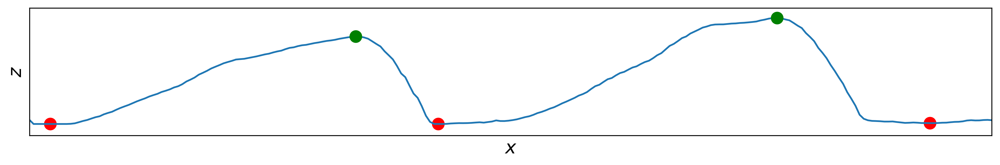

In [369]:
peakloc=[]
q_spt=[]
q_dem=[]
y_disp=300
z_y=dt.z[(dt.x.size-1500)//2:(dt.x.size-1500)//2+1500,y_disp]
qspt_y=dt.qspt[(dt.x.size-1500)//2:(dt.x.size-1500)//2+1500,y_disp]
qdem_y=dt.qdem[(dt.x.size-1500)//2:(dt.x.size-1500)//2+1500,y_disp]
x_example=dt.x[(dt.x.size-1500)//2:(dt.x.size-1500)//2+1500]

peaks, properties = find_peaks(-z_y, prominence=0.5, distance=80)
# del properties
valley_pos = peaks[z_y[peaks] < 3]
for x_disp in range(1,len(valley_pos)):
    startIDx=valley_pos[x_disp-1]
    endIDx=valley_pos[x_disp]
    segment_z=z_y[startIDx:endIDx]
    segment_qspt=qspt_y[startIDx:endIDx]
    segment_qdem=qdem_y[startIDx:endIDx]
    q_spt.append(segment_qspt[segment_z.values ==segment_z.max().values])
    q_dem.append(segment_qdem[segment_z.values ==segment_z.max().values])

qspt_y=qspt_y[6:-1]
qdem_y=qdem_y[6:-1]

plt.figure(figsize=(15,2))
plt.plot(z_y)
plt.scatter(valley_pos, z_y[valley_pos], s=100, color='red')

if hasattr(z_y, 'values'):
    z_y_values = z_y.values
else:
    z_y_values = z_y

for x_disp in range(1,len(valley_pos)):
    start_idx = valley_pos[x_disp-1]
    end_idx = valley_pos[x_disp]

    if start_idx < end_idx:
        z_y_segment = z_y_values[start_idx:end_idx+1]
        max_idx_in_segment = np.argmax(z_y_segment)
        max_idx = start_idx + max_idx_in_segment

        plt.scatter(max_idx, z_y_values[max_idx], color='green', s=100, 
                   zorder=5, marker='o', label=f'Max at {max_idx}')

plt.xlim(742,975)
plt.ylim(-0.8,8)
plt.xticks([])
plt.yticks([])
plt.xlabel('$x$')
plt.ylabel('$z$')
if 'label' in plt.gca().get_legend_handles_labels()[1]:
    plt.legend()
plt.show()

In [370]:
dt = xr.Dataset(
    {
        'z': (('x', 'y'),gaussian_filter((dftk.dunemask[1] - dftk.dunemask[1].min()).
                                         fillna(0).values.astype(float), sigma=8))
    },
    coords={
        'x': (('x'), dftk.x.values - dftk.x.min().item()),
        'y': (('y'), dftk.y.values - dftk.y.min().item()),
    },
)

dt = make_pad(dt,'z','zp',padsl)
dt= make_bubble(dt,'zp','zb',recth,recsl)
dt['zpb'] = xr.where(dt.zb.isnull(), dt.zp, dt.zb)
dt['zpbro'] = dt.zpb-dt.zp+dt.z

qdata=dftk.qmask[1].values
qdem = np.zeros(dt.z.shape)
x_offset = (dt.x.size- qdata.shape[0]) // 2
y_offset = (dt.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dt['qdem'] = (('x','y'),qdem)

start_time = pd.Timestamp(dftk.time[1].item()).tz_localize('UTC')
end_time = pd.Timestamp(dftk.time[2].item()).tz_localize('UTC')

ut = res_tk1.x[0]
Cq = res_tk1.x[1]
lsat = res_tk1.x[2]
dwtk=dwtk_hourly1
dw_period1 = dwtk.where((dwtk.time >= start_time) & (dwtk.time <= end_time) & (dwtk.speed_proj*kap/np.log(z01/z00) >=ut))
dw_period1['stree_velocity'] = dw_period1['speed_proj']*kap/np.log(z01/z00)
dw_period1 = dw_period1.dropna()

us=dw_period1['stree_velocity'].mean().item()#representative value
dt['uxs'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dt.x.data,dt.y.data,dt.zb.where(~dt.zb.isnull(),dt.zp).data,d,us,nu),us).real)
dt['uxs'] = dt.uxs.where(dt.zb.isnull(),0).clip(0,None)


dt = dt.assign_coords(time=dw_period1.time)
dt['ux'] = (('time'),dw_period1['stree_velocity'])
dt['uxt'] = dt.ux/us*dt.uxs
dt['qs'] = (dt.uxt**2-ut**2)*Cq*ut*rhof/rhos_ws*grav
dt['qs'] = dt.qs.where(dt.qs>0,0)

dx = dt.x.isel(x=slice(None,2)).diff('x').data[0]

q = np.zeros(dt.qs.shape) # true flux array initialised
q[:,0] = 0 # input true flux at x=0, here just arbitrary
dx=dt.x.isel(x=slice(None,2)).diff('x').data[0]
for i in range(1,q.shape[1]):
    q[:,i] = (q[:,i-1]+dx*dt.qs.data[:,i]/lsat)/(1+dx/lsat) # loop through and make true flux
dt['q'] = (('time','x','y'),q)
dt['qspt'] = dt.q.mean('time') * 365.25 * 24
dt['qspt']
dt['qspt'] = (('x', 'y'), np.nan_to_num(dftk.mask.values * dt.qspt.values, nan=0.0))

q_spt=[]
q_dem=[]

for y_disp in range(dftk.y.shape[0]):
    z_y=dt.z[:,y_disp]   
    qspt_y=dt.qspt[:,y_disp]
    qdem_y=dt.qdem[:,y_disp]

    if z_y.max()>0:

        q_spt.append(qspt_y[z_y ==z_y.max().values])
        q_dem.append(qdem_y[z_y ==z_y.max().values])
q_spt_mf = np.array(q_spt, dtype=np.float64).flatten()
q_dem_mf = np.array(q_dem, dtype=np.float64).flatten()
invalid_indices = (q_dem_mf<=2.5) | (q_spt_mf<=2.5)
q_dem_mf = q_dem_mf[~invalid_indices]
q_spt_mf = q_spt_mf[~invalid_indices]

## Figure used in response to Reviewer 3

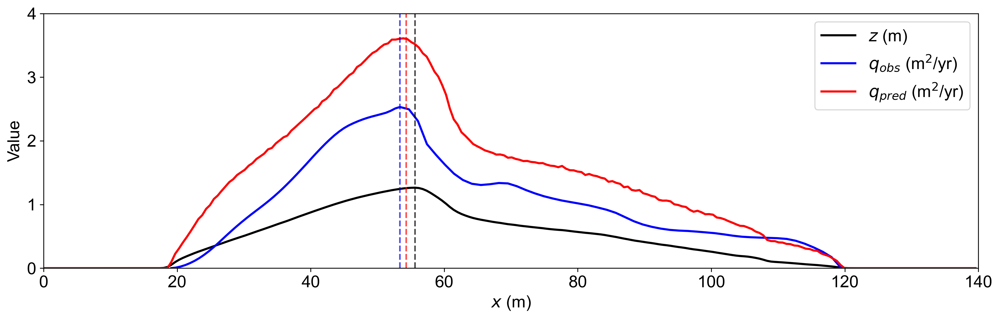

In [ ]:
dt['z'] = xr.DataArray(
    gaussian_filter((dftk.dunemask[1] - dftk.dunemask[1].min())
                    .fillna(0).values.astype(float), sigma=1),
    dims=dt.qdem.dims,
    coords={'x': dt.x, 'y': dt.y}
)

z_mean = dt.z.mean('y')
qdem_mean = dt.qdem.mean('y')
qspt_mean = dt.qspt.mean('y')

x_qdem_original = qdem_mean.x.values
y_qdem_original = qdem_mean.values

nonzero_mask = y_qdem_original != 0
x_nonzero = x_qdem_original[nonzero_mask]
x_left_cross = x_nonzero[0]
x_right_cross = x_nonzero[-1]

qdem_max_idx = np.argmax(y_qdem_original)
qdem_max_x_original = x_qdem_original[qdem_max_idx]
qdem_max_y = y_qdem_original[qdem_max_idx]

shift = -4
qdem_max_x_new = qdem_max_x_original + shift

x_left_part = np.linspace(x_left_cross, qdem_max_x_new, 50)
x_right_part = np.linspace(qdem_max_x_new, x_right_cross, 50)

x_left_original = np.linspace(x_left_cross, qdem_max_x_original, 50)
y_left_original = np.interp(x_left_original, x_qdem_original, y_qdem_original)

x_right_original = np.linspace(qdem_max_x_original, x_right_cross, 50)
y_right_original = np.interp(x_right_original, x_qdem_original, y_qdem_original)

t_left = np.linspace(0, 1, len(x_left_part))
x_left_mapped = x_left_cross + t_left * (qdem_max_x_new - x_left_cross)
y_left_mapped = np.interp(t_left, np.linspace(0, 1, len(x_left_original)), y_left_original)

t_right = np.linspace(0, 1, len(x_right_part))
x_right_mapped = qdem_max_x_new + t_right * (x_right_cross - qdem_max_x_new)
y_right_mapped = np.interp(t_right, np.linspace(0, 1, len(x_right_original)), y_right_original)

x_qdem_new = np.concatenate([x_left_mapped[:-1], x_right_mapped])
y_qdem_new = np.concatenate([y_left_mapped[:-1], y_right_mapped])

z_max_idx = np.argmax(z_mean.values)
z_max_x = z_mean.x[z_max_idx].values
z_max_y = z_mean[z_max_idx].values

qspt_max_idx = np.argmax(qspt_mean.values)
qspt_max_x = qspt_mean.x[qspt_max_idx].values
qspt_max_y = qspt_mean[qspt_max_idx].values

plt.figure(figsize=(9*1.5, 3*1.5))

plt.plot(z_mean.x, z_mean, 'k-', linewidth=2, label='$z$ (m)')
plt.plot(x_qdem_new, y_qdem_new, 'b-', linewidth=2, label='$q_{obs}$ (m$^2$/yr)')
plt.plot(qspt_mean.x, qspt_mean, 'r-', linewidth=2, label='$q_{pred}$ (m$^2$/yr)')

plt.axvline(z_max_x, color='k', linestyle='--', alpha=0.7, linewidth=1.5)
plt.axvline(qdem_max_x_new, color='b', linestyle='--', alpha=0.7, linewidth=1.5)
plt.axvline(qspt_max_x+0.4, color='r', linestyle='--', alpha=0.7, linewidth=1.5)

plt.xlabel('$x$ (m)')
plt.ylabel('Value')
plt.xlim(0, 140)
plt.ylim(0, 4)
plt.legend()
plt.tight_layout()
plt.show()

## Figure S8 B&C

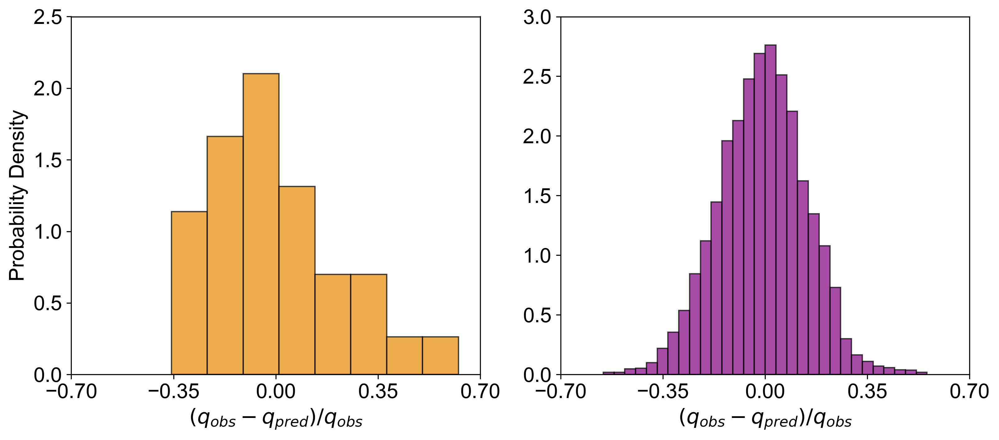

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))


diff0 = (q_dem0 - q_spt0)
diff1 = (q_dem1 - q_spt1)
data_left = np.concatenate([diff0, diff1])

axes[1].hist((data_left)/np.mean(np.concatenate([q_dem0, q_dem1])), bins=30, density=True, alpha=0.7, color='purple', edgecolor='black')
axes[1].set_ylim([0,3])
axes[1].set_xlim([-0.7,0.7])
axes[1].set_xticks([-0.7,-0.35,0,0.35,0.7])
axes[1].set_xlabel('$(q_{obs} - q_{pred})/q_{obs}$')


data_right = q_spt_mf - q_dem_mf

axes[0].hist(data_right/np.mean(q_dem_mf[(data_right < 5)]), bins=8, density=True, alpha=0.7, color='#E88B00', edgecolor='black')
axes[0].set_ylabel('Probability Density')
axes[0].set_ylim([0,2.5])
axes[0].set_xlim([-0.7,0.7])
axes[0].set_xticks([-0.7,-0.35,0,0.35,0.7])
axes[0].set_xlabel('$(q_{obs} - q_{pred})/q_{obs}$')


plt.tight_layout()
plt.show()

## Figure S7

In [ ]:
ut = res1.x[0]
Cq = res1.x[1]
lsat =  res1.x[2] # saturation length

start_time = pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')
end_time = pd.Timestamp(dfws.t[2].item()).tz_localize('UTC')

recsl_values = np.linspace(4, 6, 5)
qspt_profiles = []
zdata_profiles = []

for recsl in recsl_values:
    zdata = dfws.zre[1].values[3000:4500, :]
    dt = xr.Dataset(data_vars=dict(z=(['x', 'y'], zdata)),
                    coords=dict(x=(['x'], np.arange(zdata.shape[0])),
                                y=(['y'], np.arange(zdata.shape[1]))))
    
    # dt = dt.coarsen(x=2, y=2, boundary='pad').mean()
    dt = make_pad(dt, 'z', 'zp', padsl)
    dt = make_bubble(dt, 'zp', 'zb', recth, -1/recsl)
    
    qdata = dfws.qre[0].values[3000:4500, :]
    qdem = np.zeros(dt.z.shape)
    x_offset = (dt.x.size - qdata.shape[0]) // 2
    y_offset = (dt.y.size - qdata.shape[1]) // 2
    qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
    dt['qdem'] = (('x', 'y'), qdem)
    
    dwws = dwws_period2
    dw_period1 = dwws.where((dwws.time >= start_time) & (dwws.time <= end_time) & 
                            (dwws.speed_proj * kap / np.log(10 / z00) >= ut), drop=True)
    dw_period1['stree_velocity'] = dw_period1['speed_proj'] * kap / np.log(10 / z00)
    
    us = dw_period1['stree_velocity'].mean().item()
    dt['uxs'] = (('x', 'y'), get_usxy_xy(
        get_taupxy_xy(dt.x.data, dt.y.data, 
                      dt.zb.where(~dt.zb.isnull(), dt.zp).data, 
                      d, us, nu), us).real)
    dt['uxs'] = dt.uxs.where(dt.zb.isnull(), 0).clip(0, None)
    
    dt = dt.assign_coords(time=dw_period1.time.data)
    dt['ux'] = (('time'), dw_period1['stree_velocity'].data)
    dt['uxt'] = dt.ux / us * dt.uxs
    dt['qs'] = (dt.uxt**2 - ut**2) * Cq * ut * rhof / rhos_ws * grav
    dt['qs'] = dt.qs.where(dt.qs > 0, 0)
    
    dx = dt.x.isel(x=slice(None, 2)).diff('x').data[0]
    q = np.zeros(dt.qs.shape)
    q[:, 0] = 0
    for i in range(1, q.shape[1]):
        q[:, i] = (q[:, i-1] + dx * dt.qs.data[:, i] / lsat) / (1 + dx / lsat)
    dt['q'] = (('time', 'x', 'y'), q)
    dt['qspt'] = dt.q.mean('time') * 365.25 * 24
    
    y_mid_idx = dt.y.shape[0] // 2
    qspt_profile = dt.qspt.isel(y=y_mid_idx).values
    z_profile =dt.zb.where(~dt.zb.isnull(), dt.zp).isel(y=y_mid_idx).values
    qspt_profiles.append(qspt_profile)
    zdata_profiles.append(z_profile)
    print(f'recsl={recsl}')


recsl=4.0
recsl=4.5
recsl=5.0
recsl=5.5
recsl=6.0


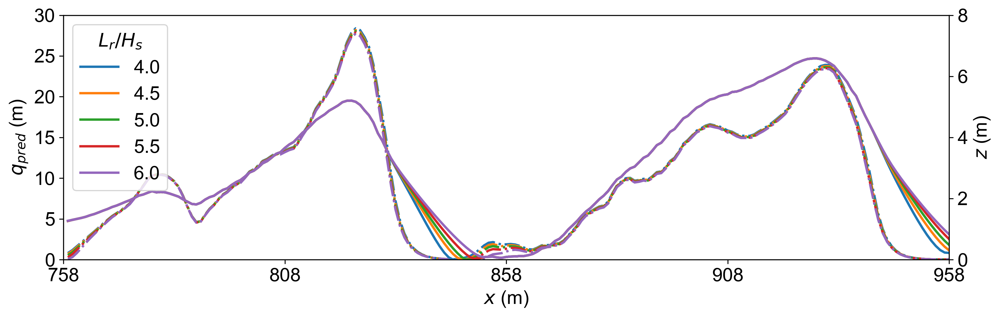

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 4))
ax2 = ax1.twinx()

colors = plt.cm.tab10(range(len(recsl_values)))

for i, recsl in enumerate(recsl_values):
    x_data = dt.x.values[820:1020]

    qspt_data = qspt_profiles[i][820:1020]
    qspt_smooth = gaussian_filter1d(qspt_data, sigma=1)

    ax1.plot(
        x_data,
        qspt_smooth,
        color=colors[i],
        linestyle='-.',
        linewidth=2,
        
    )

    ax2.plot(
        x_data,
        zdata_profiles[i][820:1020],
        color=colors[i],
        linestyle='-',
        linewidth=2,
        label=f'{recsl:.1f}'
    )

# 坐标轴
ax1.set_xlabel('$x$ (m)')
ax1.set_ylabel('$q_{pred}$ (m)')
ax2.set_ylabel('$z$ (m)')
ax1.set_ylim([0, 30])
ax2.set_ylim([0, 8])



ax2.legend(title='$L_r/H_s$')

plt.tight_layout()
plt.xlim(758,958+0.0001)
plt.xticks(np.arange(758, 958+1, 50))
plt.show()

## Figure S9

In [ ]:
lsat_vals_tkforCl = np.linspace(1, 30, 100) / (rhof / (rhos_tk * d_tk))

loss_all = {}

for scale_num in [ 4, 5, 6, 7, 10, 12, 15, 18, 20]:

    print(f'Running scale_num = {scale_num}')

    # coarsen
    dftk1 = dftk.coarsen(
        xg=scale_num,
        yg=scale_num,
        boundary='pad'
    ).mean()

    padsl = -1/6
    recth = np.tan(-18*np.pi/180)
    recsl = -1/6

    start_time = pd.Timestamp(dftk.time[1].item()).tz_localize('UTC')
    end_time = pd.Timestamp(dftk.time[2].item()).tz_localize('UTC')

    sigma = 3

    dttk = xr.Dataset(
        {
            'z': (
                ('x', 'y'),
                gaussian_filter(
                    (dftk1.dunemask[1] - dftk1.dunemask[1].min())
                    .fillna(0)
                    .values.astype(float),
                    sigma=sigma
                )
            )
        },
        coords={
            'x': dftk1.x.values - dftk1.x.min().item(),
            'y': dftk1.y.values - dftk1.y.min().item(),
        },
    )

    dttk = make_pad(dttk, 'z', 'zp', padsl)
    dttk = make_bubble(dttk, 'zp', 'zb', recth, recsl)

    dttk['zpb'] = xr.where(dttk.zb.isnull(), dttk.zp, dttk.zb)
    dttk['zpbro'] = dttk.zpb - dttk.zp + dttk.z

    qdata = dftk1.qmask[1].values
    qdem = np.zeros(dttk.z.shape)

    x_offset = (dttk.x.size - qdata.shape[0]) // 2
    y_offset = (dttk.y.size - qdata.shape[1]) // 2

    qdem[
        x_offset:x_offset + qdata.shape[0],
        y_offset:y_offset + qdata.shape[1]
    ] = qdata

    dttk['qdem'] = (('x', 'y'), qdem)

    # calculate loss
    loss_gridlsat_tk = np.zeros(len(lsat_vals_tkforCl))

    for j, lsat in enumerate(lsat_vals_tkforCl):
        loss_gridlsat_tk[j] = fromfactor_tolossfunction(
            res_tk1.x[0],
            res_tk1.x[1] + 0.48,
            lsat,
            dttk,
            dwtk_hourly1,
            z01,
            start_time,
            end_time,
        )

    loss_all[scale_num] = loss_gridlsat_tk

Running scale_num = 4
Running scale_num = 5
Running scale_num = 6
Running scale_num = 7
Running scale_num = 10
Running scale_num = 12
Running scale_num = 15
Running scale_num = 18
Running scale_num = 20


scale=4: optimum x = 2.608
scale=5: optimum x = 2.266
scale=6: optimum x = 2.266
scale=7: optimum x = 2.412
scale=10: optimum x = 2.608
scale=12: optimum x = 2.803
scale=15: optimum x = 2.559
scale=18: optimum x = 1.827
scale=20: optimum x = 0.704


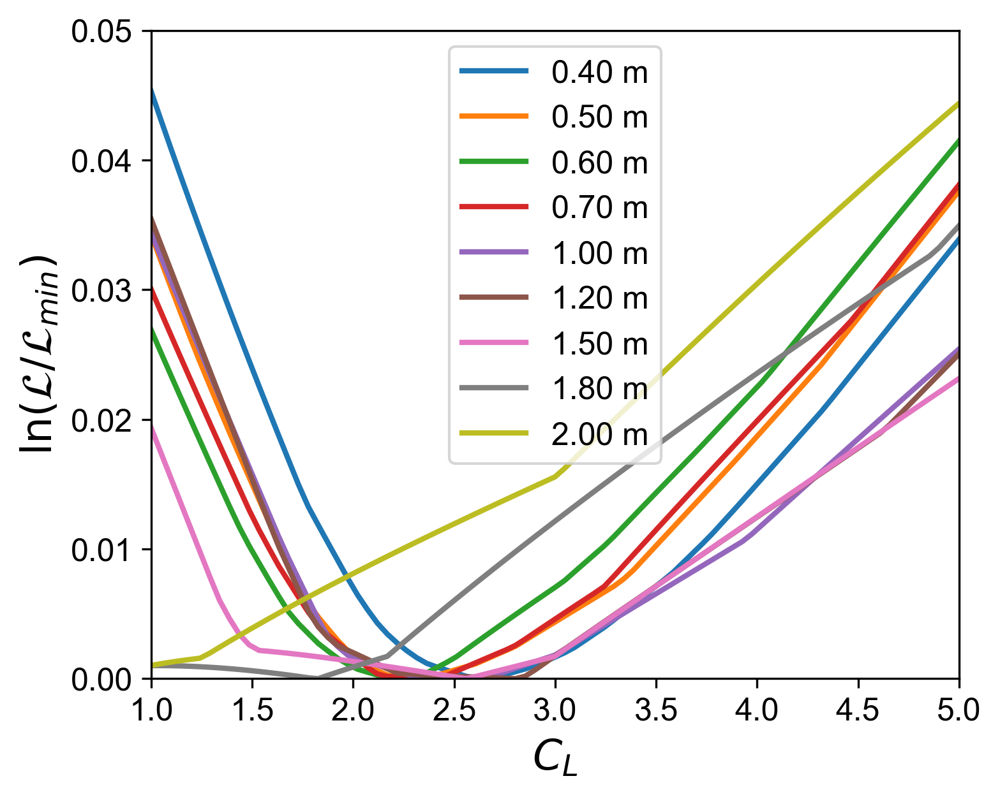

In [ ]:
plt.figure(figsize=(5,4))

for scale_num, loss in loss_all.items():

    x = lsat_vals_tkforCl * (rhof / (rhos_tk * d_tk)) / 6
    y = np.log(loss / np.min(loss))

    line, = plt.plot(
        x,
        y,
        label = f'{scale_num/10:.2f} m',
        lw=2
    )

    idx = np.argmin(loss)
    xmin = x[idx]


    print(f'scale={scale_num}: optimum x = {xmin:.3f}')



plt.legend()
plt.tight_layout()
plt.xlabel('$C_L$',fontsize=14)
plt.xlim([1,5])
plt.ylim([0,0.05])
plt.ylabel('$\\ln(\\mathcal{L}/\\mathcal{L}_{min})$',fontsize=14)

plt.show()